# Equivalência Plana

**Módulo:** 04 – Geometria Plana

**Pré-requisitos:** [`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb) (figuras congruentes; casos LAL, LLL e ALA), [`0406a_paralelismo.ipynb`](0406a_paralelismo.ipynb) (ângulos alternos internos e correspondentes), [`0407a_perpendicularidade.ipynb`](0407a_perpendicularidade.ipynb) (altura como distância de um ponto a uma reta), [`0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb`](0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb) e [`0409a_paralelogramos_e_casos_particulares.ipynb`](0409a_paralelogramos_e_casos_particulares.ipynb) (trapézio, paralelogramo, retângulo, losango e base média), [`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb) (mediana, baricentro e bissetriz), [`0411a_poligonos.ipynb`](0411a_poligonos.ipynb) (triangulação de um polígono em $n - 2$ triângulos), [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb) (razão de semelhança e média geométrica), [`0416a_triangulos_retangulos.ipynb`](0416a_triangulos_retangulos.ipynb) (Pitágoras e relações métricas), [`0417a_triangulos_quaisquer.ipynb`](0417a_triangulos_quaisquer.ipynb) e [`0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb`](0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb) (Herão, $S = p \cdot r$ e $S = p \cdot a$).

**Objetivos de aprendizagem:** ao final você será capaz de...
- Distinguir figuras **congruentes**, **equivalentes** e **semelhantes**, e usar a ideia central do notebook: **cortar e recolar não muda a área**.
- **Deduzir** (e não decorar) as áreas do retângulo, do paralelogramo, do triângulo, do trapézio e do losango a partir de um único ponto de partida, o quadrado unitário.
- Comparar e **dividir áreas** de triângulos por bases e alturas (medianas, bissetriz, teorema de Viviani) e **demonstrar Pitágoras por áreas**, inclusive para figuras semelhantes, usando a razão de áreas $k^2$.
- Transformar qualquer polígono em um **quadrado de mesma área** (teorema de Wallace–Bolyai–Gerwien) e explicar por que o círculo **não** pode ser "quadrado" com régua e compasso.

**Tempo estimado:** 90 a 105 minutos (é um notebook denso: vale dividir em duas sessões, uma para as seções 1 a 3 e outra para as seções 4 e 5)

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leandrofreiredealmeida/curso_matematica_python/blob/main/04_geometria_plana/0419a_equivalencia_plana.ipynb)

## Sete peças, muitas figuras

O **Tangram** é um quebra-cabeça chinês de sete peças, todas recortadas de um mesmo quadrado: **dois triângulos grandes**, **um triângulo médio**, **dois triângulos pequenos**, **um quadrado** e **um paralelogramo**. Com essas sete peças (sem sobrar nenhuma e sem sobrepor nenhuma) dá para montar centenas de figuras: animais, pessoas, casas, barcos.

Logo abaixo da célula de preparação, aparecem quatro figuras montadas com o mesmo jogo de peças: o **quadrado** original, um **barco**, um **triângulo** grande e um **paralelogramo**. Antes de rodar, pense:

> Qual dessas quatro figuras tem a **maior área**?

E outra pergunta, que exige um pouco mais: se o quadrado completo tem área 1, quanto vale a área de **cada peça**?

In [1]:
import math
import random
from fractions import Fraction

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ipywidgets as widgets
from IPython.display import display
from matplotlib.patches import Arc, Polygon, Rectangle, Wedge

# Paleta de cores Nord
NORD_FUNDO = "#2E3440"
NORD_PAINEL = "#3B4252"
NORD_LINHA = "#4C566A"
NORD_TEXTO = "#ECEFF4"
NORD_TEXTO_SEC = "#D8DEE9"
COR_PONTO = "#88C0D0"
COR_DESTAQUE = "#A3BE8C"
COR_ALERTA = "#BF616A"
COR_SECUNDARIA = "#81A1C1"
COR_EXTRA = "#B48EAD"
COR_AVISO = "#EBCB8B"


def estilizar_eixo(ax) -> None:
    """Aplica o estilo Nord padrão a um eixo do matplotlib."""
    ax.set_facecolor(NORD_FUNDO)
    ax.tick_params(colors=NORD_TEXTO_SEC)
    for spine in ax.spines.values():
        spine.set_color(NORD_LINHA)
    ax.grid(color=NORD_LINHA, linewidth=0.5, alpha=0.5)


# Ferramentas de desenho e de medida dos notebooks anteriores (0401a, 0402a, 0407a, 0410a e 0417a)

def preparar_eixo(ax, pontos, margem: float = 0.8) -> None:
    """Deixa o eixo pronto para desenhos de geometria (estilo Nord, sem grade, sem números,
    escala igual) e enquadra todos os `pontos` com uma margem em volta."""
    estilizar_eixo(ax)
    ax.grid(False)
    xs = [p[0] for p in pontos]
    ys = [p[1] for p in pontos]
    ax.set_xlim(min(xs) - margem, max(xs) + margem)
    ax.set_ylim(min(ys) - margem, max(ys) + margem)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])


def direcao(angulo_graus: float) -> np.ndarray:
    """Vetor de tamanho 1 apontando na direção dada, em graus, a partir da horizontal (sentido anti-horário).

    (cos e sin vêm da Trigonometria, módulo 05; aqui só servem para apontar na direção certa.)
    """
    rad = math.radians(angulo_graus)
    return np.array([math.cos(rad), math.sin(rad)])


def direcao_de(origem, destino) -> float:
    """Direção, em graus, em que `destino` está quando visto de `origem`."""
    return math.degrees(math.atan2(destino[1] - origem[1], destino[0] - origem[0]))


def ponto_medio(P, Q) -> np.ndarray:
    """Ponto médio do segmento PQ: a média das coordenadas (0402a)."""
    return (np.asarray(P, dtype=float) + np.asarray(Q, dtype=float)) / 2


def iguais(x: float, y: float) -> bool:
    """Compara duas medidas com uma tolerância pequena (as contas com float têm arredondamentos)."""
    return math.isclose(x, y, rel_tol=1e-9, abs_tol=1e-6)


def vetorial(u, v) -> float:
    """Produto vetorial de dois vetores do plano, u₁v₂ − u₂v₁: positivo se v está à esquerda de u (módulo 07)."""
    return float(u[0] * v[1] - u[1] * v[0])


def pe_da_altura(X, P, Q) -> np.ndarray:
    """Pé da perpendicular baixada de X sobre a reta PQ (0407a)."""
    X, P, Q = (np.asarray(Z, dtype=float) for Z in (X, P, Q))
    u = Q - P
    return P + np.dot(X - P, u) / np.dot(u, u) * u


def distancia_ponto_reta(X, P, Q) -> float:
    """Distância do ponto X à reta PQ: a medida de X até o pé da perpendicular (0407a)."""
    return math.dist(X, pe_da_altura(X, P, Q))


def desenhar_ponto(ax, p, nome: str = "", cor: str = COR_AVISO, deslocamento=(0.12, 0.15),
                   tamanho_fonte: int = 13) -> None:
    """Desenha um ponto com seu nome (letra maiúscula) ao lado."""
    ax.plot(*p, "o", color=cor, markersize=7, zorder=8)
    if nome:
        ax.text(p[0] + deslocamento[0], p[1] + deslocamento[1], nome, color=NORD_TEXTO, fontsize=tamanho_fonte,
                fontweight="bold", zorder=9)


def desenhar_segmento(ax, P, Q, cor: str = NORD_TEXTO, largura: float = 3.0, estilo: str = "-",
                      alpha: float = 1.0, zorder: int = 6) -> None:
    """Desenha o segmento PQ (só o pedaço entre P e Q)."""
    ax.plot(*zip(P, Q), color=cor, lw=largura, linestyle=estilo, alpha=alpha, zorder=zorder,
            solid_capstyle="round")


def desenhar_setor(ax, vertice, inicio: float, abertura: float, raio: float = 0.5, cor: str = COR_PONTO,
                   rotulo: str | None = None, marcar_reto: bool = True, raio_rotulo: float | None = None,
                   tamanho_fonte: int = 11) -> None:
    """Pinta o ângulo com vértice em `vertice` que começa na direção `inicio` e gira `abertura`
    graus no sentido anti-horário. O ângulo reto ganha o quadradinho no lugar do arco."""
    v = np.array(vertice, dtype=float)
    if marcar_reto and math.isclose(abertura, 90, abs_tol=1e-6):
        lado = 0.6 * raio
        canto = [v, v + lado * direcao(inicio), v + lado * (direcao(inicio) + direcao(inicio + 90)),
                 v + lado * direcao(inicio + 90)]
        ax.add_patch(Polygon(canto, closed=True, facecolor=cor, alpha=0.35, edgecolor=cor, lw=2, zorder=7))
    else:
        ax.add_patch(Wedge(v, raio, inicio, inicio + abertura, facecolor=cor, alpha=0.3, edgecolor="none",
                           zorder=7))
        ax.add_patch(Arc(v, 2 * raio, 2 * raio, theta1=inicio, theta2=inicio + abertura, color=cor, lw=2,
                         zorder=7))
    if rotulo:
        distancia_rotulo = 1.6 * raio if raio_rotulo is None else raio_rotulo
        posicao = v + distancia_rotulo * direcao(inicio + abertura / 2)
        ax.text(*posicao, rotulo, color=cor, fontsize=tamanho_fonte, ha="center", va="center", fontweight="bold")


def marcar_angulo_reto(ax, vertice, P, Q, tamanho: float = 0.3, cor: str = NORD_TEXTO_SEC) -> None:
    """Quadradinho de ângulo reto no `vertice`, entre as direções de P e de Q."""
    v = np.asarray(vertice, dtype=float)
    u = (np.asarray(P, dtype=float) - v) / math.dist(P, v)
    w = (np.asarray(Q, dtype=float) - v) / math.dist(Q, v)
    canto = [v, v + tamanho * u, v + tamanho * (u + w), v + tamanho * w]
    ax.add_patch(Polygon(canto, closed=True, fill=False, edgecolor=cor, lw=1.5, zorder=7))


def rotular_fora(ax, P, texto: str, centro, cor: str = NORD_TEXTO, distancia: float = 0.35,
                 tamanho: int = 12) -> None:
    """Escreve `texto` perto do ponto P, afastado do `centro` (para não ficar em cima da figura)."""
    P = np.asarray(P, dtype=float)
    afastar = P - np.asarray(centro, dtype=float)
    afastar = afastar / np.linalg.norm(afastar) if np.linalg.norm(afastar) > 0 else np.array([0.0, 1.0])
    ax.text(*(P + distancia * afastar), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=9)


def rotular_segmento(ax, P, Q, texto: str, cor: str = NORD_TEXTO, distancia: float = 0.35, longe_de=None,
                     tamanho: int = 11) -> None:
    """Escreve `texto` ao lado do meio do segmento PQ, afastado `distancia` na direção perpendicular a ele.
    Se `longe_de` for um ponto, o texto vai para o lado do segmento oposto a esse ponto."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    u = (Q - P) / np.linalg.norm(Q - P)
    normal = np.array([-u[1], u[0]])
    meio = (P + Q) / 2
    if longe_de is not None and np.dot(meio - np.asarray(longe_de, dtype=float), normal) < 0:
        normal = -normal
    ax.text(*(meio + distancia * normal), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=9)


def escrever_checklist(ax, itens, titulo: str = "") -> None:
    """Painel de texto com uma linha por item (texto, ok): ✓ verde quando vale, ✗ vermelho quando não (0410a)."""
    ax.set_facecolor(NORD_FUNDO)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    if titulo:
        ax.text(0.0, 0.97, titulo, color=NORD_TEXTO, fontsize=12, fontweight="bold", va="top")
    passo = min(0.13, 0.85 / max(len(itens), 1))
    for k, (texto, ok) in enumerate(itens):
        ax.text(0.0, 0.84 - k * passo, f"{'✓' if ok else '✗'}  {texto}", color=COR_DESTAQUE if ok else COR_ALERTA,
                fontsize=11, va="top")


# Ferramentas novas deste notebook
# Cores fixas: figura original azul-claro; peça que se move (o "corte") amarela; figura obtida (a equivalente)
# verde; base roxa; altura laranja; vão ou erro vermelho. As peças de um quebra-cabeça usam CORES_PECAS.
COR_FIGURA = COR_PONTO  # figura original: azul-claro
COR_MOVEL = COR_AVISO  # peça cortada que se desloca: amarelo
COR_RESULTADO = COR_DESTAQUE  # figura equivalente obtida: verde
COR_BASE = COR_EXTRA  # base: roxo
COR_ALTURA = "#D08770"  # altura: laranja
COR_VAO = COR_ALERTA  # vão, sobreposição ou erro: vermelho
CORES_PECAS = ("#88C0D0", "#A3BE8C", "#EBCB8B", "#BF616A", "#B48EAD", "#D08770", "#81A1C1", "#8FBCBB", "#5E81AC")


def area_cadarco(pontos) -> float:
    """Área de um polígono simples (lados que não se cruzam) a partir dos vértices EM ORDEM, pela fórmula do
    cadarço: S = |x₁y₂ − x₂y₁ + x₂y₃ − x₃y₂ + ... + xₙy₁ − x₁yₙ| / 2.

    É uma "régua de área" de CONFERÊNCIA: a justificativa chega em Geometria Analítica (módulo 07), e nenhuma
    demonstração deste notebook depende dela.
    """
    P = np.asarray(pontos, dtype=float)
    x, y = P[:, 0], P[:, 1]
    return abs(float(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))) / 2


def desenhar_peca(ax, pontos, cor: str = COR_FIGURA, opacidade: float = 0.55, borda: str = NORD_TEXTO,
                  largura: float = 1.5, estilo: str = "-", rotulo: str | None = None, tamanho: int = 11,
                  zorder: int = 3) -> None:
    """Desenha uma peça (polígono) pintada, com contorno; `rotulo` é escrito no centro da peça."""
    P = np.asarray(pontos, dtype=float)
    ax.add_patch(Polygon(P, closed=True, facecolor=cor, alpha=opacidade, edgecolor="none", zorder=zorder))
    ax.add_patch(Polygon(P, closed=True, fill=False, edgecolor=borda, lw=largura, linestyle=estilo,
                         zorder=zorder + 1))
    if rotulo:
        ax.text(*P.mean(axis=0), rotulo, color=NORD_TEXTO, fontsize=tamanho, fontweight="bold", ha="center",
                va="center", zorder=zorder + 2)


def desenhar_contorno(ax, pontos, cor: str = NORD_TEXTO_SEC, largura: float = 1.5, estilo: str = "--",
                      zorder: int = 2) -> None:
    """Só o contorno (tracejado) de um polígono: a "sombra" de onde uma peça estava ou vai ficar."""
    ax.add_patch(Polygon(np.asarray(pontos, dtype=float), closed=True, fill=False, edgecolor=cor, lw=largura,
                         linestyle=estilo, zorder=zorder))


def girar(pontos, centro, graus: float) -> np.ndarray:
    """Gira os pontos em torno de `centro` por `graus` (sentido anti-horário). Giro é um movimento rígido:
    a figura girada é congruente à original."""
    c = np.asarray(centro, dtype=float)
    u, v = direcao(graus), direcao(graus + 90)
    return np.array([c + (p[0] - c[0]) * u + (p[1] - c[1]) * v for p in np.asarray(pontos, dtype=float)])


def transladar(pontos, vetor) -> np.ndarray:
    """Desliza todos os pontos pelo mesmo `vetor` (translação, outro movimento rígido)."""
    return np.asarray(pontos, dtype=float) + np.asarray(vetor, dtype=float)


def mover(pontos, t: float, centro=None, graus: float = 0.0, vetor=(0.0, 0.0)) -> np.ndarray:
    """Fração t (de 0 a 1) de um movimento: gira graus·t em torno de `centro` e depois desliza vetor·t.
    Com t = 0 a peça está no lugar de origem; com t = 1, no lugar de destino (é o que anima os widgets)."""
    P = np.asarray(pontos, dtype=float)
    if centro is not None and graus:
        P = girar(P, centro, graus * t)
    return transladar(P, t * np.asarray(vetor, dtype=float))


def movimento_rigido(origem, destino):
    """Dado um triângulo `origem` e um triângulo `destino` CONGRUENTE (vértices na ordem correspondente), devolve
    a função que leva cada ponto do plano para a nova posição (giro, translação e talvez reflexão). Recusa
    triângulos que não são congruentes: um movimento rígido não muda distâncias."""
    p, q = np.asarray(origem, dtype=float), np.asarray(destino, dtype=float)
    M = np.column_stack([q[1] - q[0], q[2] - q[0]]) @ np.linalg.inv(np.column_stack([p[1] - p[0], p[2] - p[0]]))
    if not np.allclose(M.T @ M, np.eye(2), atol=1e-9):
        raise ValueError("os triângulos não são congruentes: não existe movimento rígido entre eles")
    return lambda pontos: (M @ (np.asarray(pontos, dtype=float) - p[0]).T).T + q[0]

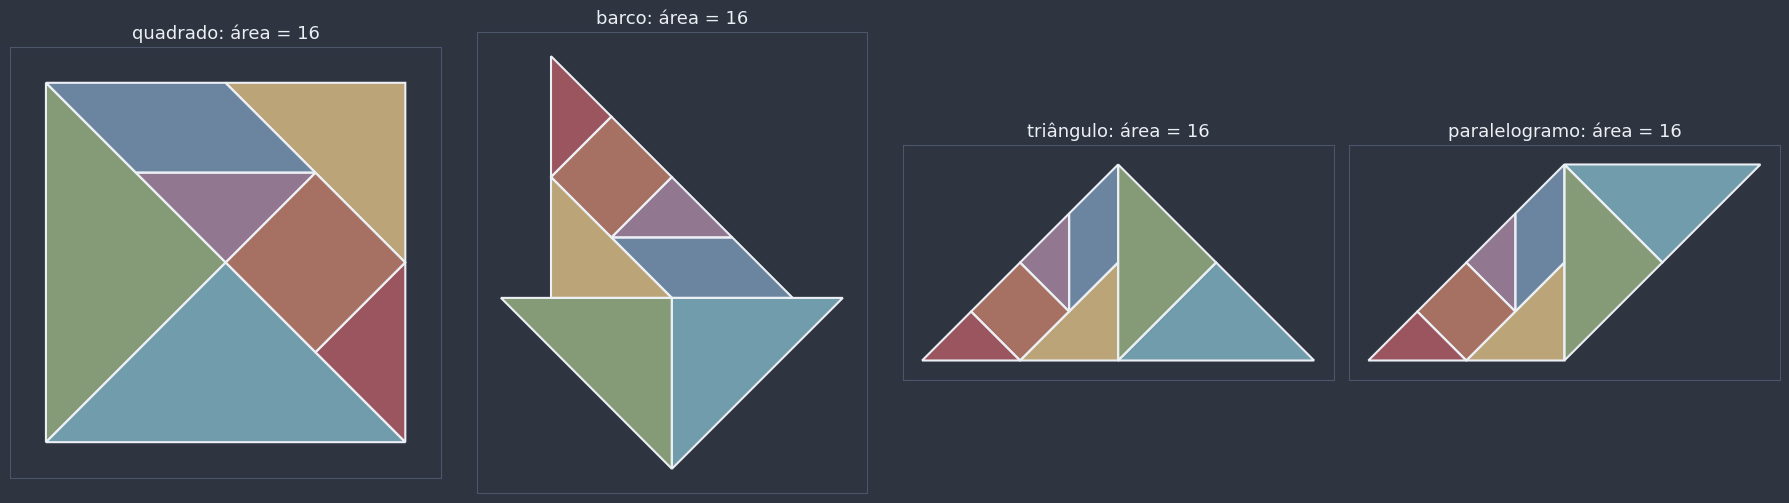

In [2]:
# As sete peças do Tangram num quadrado 4 × 4 (área 16)
TANGRAM = {
    "triângulo grande 1": [(0, 0), (4, 0), (2, 2)],
    "triângulo grande 2": [(0, 0), (2, 2), (0, 4)],
    "triângulo médio": [(2, 4), (4, 2), (4, 4)],
    "triângulo pequeno 1": [(4, 0), (4, 2), (3, 1)],
    "triângulo pequeno 2": [(2, 2), (3, 3), (1, 3)],
    "quadrado": [(2, 2), (3, 1), (4, 2), (3, 3)],
    "paralelogramo": [(0, 4), (1, 3), (3, 3), (2, 4)],
}
GRANDES = ("triângulo grande 1", "triângulo grande 2")
# Os dois triângulos grandes juntos formam o triângulo (0,0), (4,0), (0,4); as outras cinco peças formam o
# triângulo (4,4), (4,0), (0,4). Para montar outra figura, basta MOVER cada um desses dois blocos.
BLOCO_GRANDES = [(0, 0), (4, 0), (0, 4)]
BLOCO_PEQUENAS = [(4, 4), (4, 0), (0, 4)]
r2 = 2 * math.sqrt(2)
MONTAGENS = {
    "quadrado": (BLOCO_GRANDES, BLOCO_PEQUENAS),
    "barco": ([(2, -r2), (2 + r2, 0), (2 - r2, 0)], [(0, 0), (0, 4), (4, 0)]),
    "triângulo": ([(4, 0), (8, 0), (4, 4)], [(4, 0), (0, 0), (4, 4)]),
    "paralelogramo": ([(4, 4), (8, 4), (4, 0)], [(4, 0), (0, 0), (4, 4)]),
}


def montar_tangram(nome: str) -> dict:
    """Posição das sete peças na montagem `nome` (cada bloco vai para o seu lugar por um movimento rígido)."""
    destino_grandes, destino_pequenas = MONTAGENS[nome]
    mover_grandes = movimento_rigido(BLOCO_GRANDES, destino_grandes)
    mover_pequenas = movimento_rigido(BLOCO_PEQUENAS, destino_pequenas)
    return {peca: (mover_grandes if peca in GRANDES else mover_pequenas)(pts) for peca, pts in TANGRAM.items()}


fig, eixos = plt.subplots(1, 4, figsize=(18, 5))
fig.patch.set_facecolor(NORD_FUNDO)
for ax, nome in zip(eixos, MONTAGENS):
    pecas = montar_tangram(nome)
    for cor, pts in zip(CORES_PECAS, pecas.values()):
        desenhar_peca(ax, pts, cor=cor, opacidade=0.75)
    todos = np.vstack(list(pecas.values()))
    preparar_eixo(ax, todos, margem=0.4)
    area_total = sum(area_cadarco(pts) for pts in pecas.values())
    ax.set_title(f"{nome}: área = {area_total:g}", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

**Resposta:** as quatro figuras têm **exatamente a mesma área**, porque são feitas das mesmas sete peças, sem sobra e sem sobreposição. O formato muda muito; a área, nada. Figuras assim (formas diferentes, mesma área) se chamam **equivalentes**, e elas são o assunto deste notebook.

A tabela abaixo mede cada peça. Repare que todas as áreas são frações "redondas" do quadrado: as peças foram cortadas seguindo diagonais e pontos médios.

In [3]:
tabela_tangram = pd.DataFrame(
    [{"peça": peca, "área (quadrado 4 × 4)": area_cadarco(pts),
      "fração do quadrado": str(Fraction(area_cadarco(pts) / 16).limit_denominator(64))}
     for peca, pts in TANGRAM.items()]
)
display(tabela_tangram)
soma = sum(Fraction(f) for f in tabela_tangram["fração do quadrado"])
print(f"soma das frações: {soma}")
assert soma == 1

,peça,área (quadrado 4 × 4),fração do quadrado
0,triângulo grande 1,4.0,1/4
1,triângulo grande 2,4.0,1/4
2,triângulo médio,2.0,1/8
3,triângulo pequeno 1,1.0,1/16
4,triângulo pequeno 2,1.0,1/16
5,quadrado,2.0,1/8
6,paralelogramo,2.0,1/8


soma das frações: 1


Os dois triângulos grandes valem $\frac{1}{4}$ cada; o médio, o quadrado e o paralelogramo valem $\frac{1}{8}$ cada; os dois pequenos, $\frac{1}{16}$ cada. Somando: $\frac{1}{4} + \frac{1}{4} + \frac{1}{8} + \frac{1}{8} + \frac{1}{8} + \frac{1}{16} + \frac{1}{16} = 1$. (A "régua de área" `area_cadarco` usada aqui é uma ferramenta de conferência; a seção 1 explica o que ela é e por que as demonstrações não dependem dela.)

Até aqui, tudo parece óbvio: cortar e recolar não muda a área. Será mesmo?

## 64 = 65?

Agora um quebra-cabeça que parece desmentir tudo. Um quadrado $8 \times 8$ (área **64**) é cortado em **quatro peças**: dois triângulos retângulos e dois trapézios. Recolocadas de outro jeito, as mesmas quatro peças parecem formar um retângulo $5 \times 13$, que tem área **65**. De onde veio o quadradinho a mais?

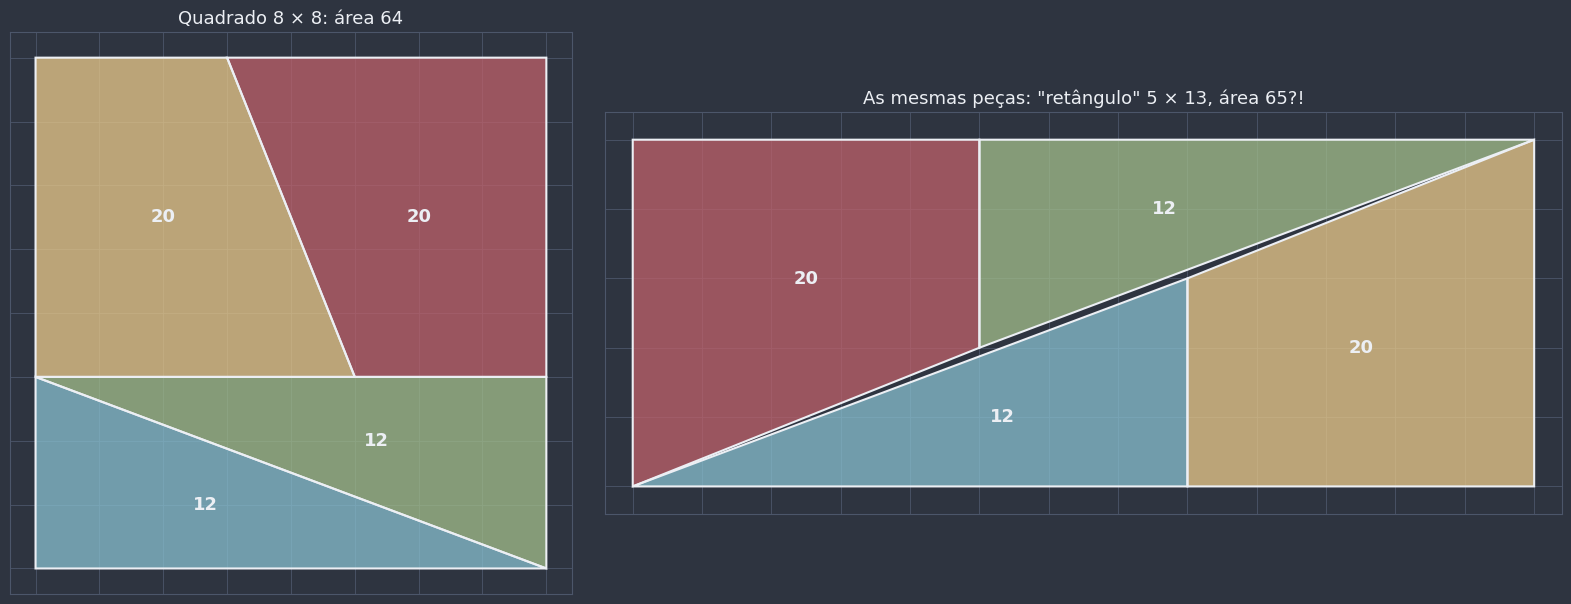

Áreas das peças: [12.0, 12.0, 20.0, 20.0]  →  soma = 64
Quadrado 8 × 8 = 64;  retângulo 5 × 13 = 65


In [4]:
def quebra_cabeca(x: int = 3, y: int = 5) -> tuple[list, list]:
    """As quatro peças do quebra-cabeça "64 = 65" (com x = 3 e y = 5): no quadrado de lado x + y e no
    "retângulo" y × (x + 2y). Cada peça do retângulo é obtida da peça do quadrado por um movimento rígido."""
    L = x + y
    no_quadrado = [
        [(0, 0), (L, 0), (0, x)],  # triângulo de catetos L e x
        [(L, x), (0, x), (L, 0)],  # o outro triângulo
        [(0, x), (y, x), (x, L), (0, L)],  # trapézio de bases y e x, altura y
        [(L, L), (x, L), (y, x), (L, x)],  # o outro trapézio
    ]
    C = L + y  # comprimento do retângulo
    destinos = [  # para onde vão três vértices de cada peça (na mesma ordem)
        [(L, 0), (0, 0), (L, x)],
        [(y, y), (C, y), (y, y - x)],
        [(C, 0), (C, y), (L, x)],
        [(0, y), (0, 0), (y, y - x)],
    ]
    no_retangulo = [movimento_rigido(p[:3], d)(p) for p, d in zip(no_quadrado, destinos)]
    return no_quadrado, no_retangulo


pecas_q, pecas_r = quebra_cabeca()
fig, (ax_q, ax_r) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1.6]})
fig.patch.set_facecolor(NORD_FUNDO)
for ax, pecas in ((ax_q, pecas_q), (ax_r, pecas_r)):
    for cor, pts in zip(CORES_PECAS, pecas):
        desenhar_peca(ax, pts, cor=cor, opacidade=0.75, rotulo=f"{area_cadarco(pts):g}", tamanho=13)
    preparar_eixo(ax, np.vstack(pecas), margem=0.4)
    for k in range(int(np.max(np.vstack(pecas)[:, 0])) + 1):  # quadriculado de fundo
        ax.axvline(k, color=NORD_LINHA, lw=0.6, zorder=0)
    for k in range(int(np.max(np.vstack(pecas)[:, 1])) + 1):
        ax.axhline(k, color=NORD_LINHA, lw=0.6, zorder=0)
ax_q.set_title("Quadrado 8 × 8: área 64", color=NORD_TEXTO, fontsize=13)
ax_r.set_title("As mesmas peças: \"retângulo\" 5 × 13, área 65?!", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

soma_pecas = sum(area_cadarco(p) for p in pecas_q)
print(f"Áreas das peças: {[area_cadarco(p) for p in pecas_q]}  →  soma = {soma_pecas:g}")
print(f"Quadrado 8 × 8 = {8 * 8};  retângulo 5 × 13 = {5 * 13}")
assert soma_pecas == 64

As peças medem $12 + 12 + 20 + 20 = 64$, e o retângulo mede $5 \cdot 13 = 65$. Algo está errado, e não é a conta. Guarde o mistério: ele será resolvido na **seção 5**, depois que você souber exatamente **o que** garante que cortar e recolar preserva a área (dica: olhe com muita desconfiança para a diagonal do retângulo).

### O fio condutor deste notebook

Desde o ensino fundamental, você usa fórmulas de área: base × altura, base × altura sobre 2, (base maior + base menor) × altura sobre 2... Os notebooks anteriores deste módulo também usaram essas fórmulas **sem demonstrar**, e deixaram várias **promessas** para cá. Todas são entregues aqui:

| Prometido em | Promessa | Onde |
|---|---|---|
| 0408a | a **base média** do triângulo e do trapézio em problemas de área | seções 2 e 3 |
| 0409a | as áreas do paralelogramo, do retângulo, do losango e do quadrado, como consequência das propriedades dos quadriláteros | seções 1 e 2 |
| 0411a | a **decomposição** de polígonos em $n - 2$ triângulos como técnica de área | seção 5 |
| 0412a | a diferença entre **comprimento** (circunferência) e **área** (círculo) | seção 5 |
| 0415a | a razão entre áreas de figuras semelhantes é $k^2$ | seção 4 |
| 0416a | **Pitágoras por áreas**, numa demonstração geral e rigorosa (lá foi só a prova visual dos quatro triângulos) | seção 4 |
| 0417a | a justificativa de $S = \frac{b \cdot h}{2}$ **por equivalência de figuras** (usada sem prova em Herão e em $S = p \cdot r$) | seção 2 |
| 0418a | a decomposição de polígonos regulares em triângulos congruentes e o regular **equivalente ao triângulo de base $2p$ e altura $a$** | seção 5 |

E toda a história sai de **uma única ideia**: cortar, deslizar e recolar.

$$\text{quadrado unitário} \to \text{retângulo} \to \text{paralelogramo} \to \text{triângulo} \to \text{trapézio e losango} \to \text{Pitágoras} \to \text{qualquer polígono}$$

| Seção | A ideia em uma frase | Ferramenta |
|---|---|---|
| 1. O que é área? | três regras escolhidas; o retângulo $b \cdot h$ e o quadrado equivalente $\sqrt{b \cdot h}$ | contagem, média geométrica (0415a) |
| 2. Transformando figuras | paralelogramo, triângulo, trapézio e losango viram retângulos | congruência (0405a), paralelismo (0406a) |
| 3. Triângulos de mesma altura | $\frac{S_1}{S_2} = \frac{b_1}{b_2}$: medianas, bissetriz, Viviani | seção 2 |
| 4. Pitágoras por áreas e $k^2$ | Euclides, o trapézio, figuras semelhantes nos lados | seções 2 e 3, semelhança (0415a) |
| 5. De qualquer polígono a um quadrado | triangular → retângulos → quadrados → um quadrado | todas as anteriores |

**Notação fixa em todo o notebook:** $S(F)$ é a **área** da figura $F$. Duas figuras são **congruentes** ($\cong$, [`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb)) quando têm a mesma forma e o mesmo tamanho; **equivalentes** quando têm a **mesma área** (a forma pode ser diferente); **semelhantes** ($\sim$, [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb)) quando têm a mesma forma, com razão de semelhança $k$. Em triângulos, $b$ é a **base** e $h$ a **altura** relativa a ela; em trapézios, $B$ é a base maior, $b$ a base menor e $h$ a altura.

As cores também são fixas: a **figura original** é azul-clara, a **peça que se move** (o "corte") é amarela, a **figura equivalente obtida** é verde; a **base** é roxa e a **altura** é laranja; **vãos e erros** são vermelhos.

## 1. O que é área? Equivalência e o quadrado unitário

O **comprimento** mede segmentos: escolhemos uma unidade (o metro, o centímetro) e contamos quantas vezes ela cabe. A **área** faz o mesmo com regiões do plano. Mas, para medir áreas, precisamos combinar as regras do jogo. São só três, e elas são o **ponto de partida de tudo**: não são demonstradas, são **escolhidas** (como os postulados de [`0401a_nocoes_e_proposicoes_primitivas.ipynb`](0401a_nocoes_e_proposicoes_primitivas.ipynb)).

1. **Unidade:** o quadrado de lado 1 tem área 1.
2. **Congruência:** figuras congruentes têm a mesma área.
3. **Aditividade:** se uma figura é dividida em partes **sem sobreposição**, a área dela é a **soma** das áreas das partes.

A regra 2 diz que mover uma figura (deslizar, girar, virar) não muda a área. A regra 3 diz que a área "se soma". Juntas, elas dão a ideia central deste notebook:

> **Cortar e recolar não muda a área.** Se uma figura é cortada em pedaços e os pedaços são remontados (sem sobrar, sem sobrepor), a nova figura tem a mesma área da original.

Foi exatamente o que aconteceu no Tangram. Duas figuras com a mesma área são chamadas **equivalentes**.

### A área do retângulo

**Lados inteiros.** Um retângulo de lados inteiros $m$ e $n$ pode ser dividido em $m$ colunas de $n$ quadrados unitários: $m \cdot n$ quadrados, sem sobrar nem sobrepor. Pelas regras 1 e 3, $S = m \cdot n$.

**Lados racionais.** E um retângulo de lados $\frac{2}{3}$ e $\frac{3}{4}$? Divida o quadrado unitário numa grade de $3 \times 4 = 12$ células iguais (cada uma de $\frac{1}{3} \times \frac{1}{4}$). As 12 células são congruentes e cobrem o quadrado, então cada uma vale $\frac{1}{12}$ (regras 2 e 3). O retângulo $\frac{2}{3} \times \frac{3}{4}$ é coberto por exatamente $2 \times 3 = 6$ dessas células, logo

$$S = \frac{6}{12} = \frac{1}{2} = \frac{2}{3} \cdot \frac{3}{4}.$$

O mesmo raciocínio vale para quaisquer frações: a área continua sendo **base × altura**.

**Lados irracionais.** E um retângulo de lados $\sqrt{2}$ e $\pi$, que não são frações ([`0416a_triangulos_retangulos.ipynb`](0416a_triangulos_retangulos.ipynb) e [`0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb`](0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb))? A fórmula continua valendo: aproximamos os lados por frações cada vez mais próximas, por dentro e por fora, e a área fica "espremida" entre $b \cdot h$ aproximados. Essa ideia de aproximar cada vez melhor é o **limite**, que aparece nos módulos de Cálculo; aqui fica só a menção.

**Quadrado de lado $\ell$:** é um retângulo com $b = h = \ell$, então $S = \ell^2$. (É daí que vem o nome "ao quadrado".)

📌 **Definição formal:**
- $S(\text{retângulo}) = b \cdot h$ e $S(\text{quadrado}) = \ell^2$.
- Duas figuras $F$ e $G$ são **equivalentes** quando $S(F) = S(G)$.
- Congruentes $\Rightarrow$ equivalentes (regra 2). A recíproca é **falsa**: o retângulo $2 \times 6$ e o retângulo $3 \times 4$ têm área 12 e não são congruentes.

### A quadratura do retângulo

Primeiro exemplo de **transformação**: dado um retângulo $b \times h$, qual é o **quadrado equivalente**? Precisamos de $\ell^2 = b \cdot h$, ou seja,

$$\ell = \sqrt{b \cdot h},$$

a **média geométrica** de $b$ e $h$ ([`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb)). Os gregos chamavam isso de **quadrar** uma figura: encontrar um quadrado com a mesma área. E dá para construir $\ell$ com **régua e compasso**, como no desafio de 0415a: numa reta, marque $b$ e $h$ em seguida; trace a circunferência de diâmetro $b + h$ e a perpendicular no ponto de junção. A meia corda mede $\sqrt{b \cdot h}$: é a relação $h^2 = m \cdot n$ de [`0416a_triangulos_retangulos.ipynb`](0416a_triangulos_retangulos.ipynb), com a altura do triângulo retângulo inscrito na semicircunferência.

A célula abaixo mostra as três situações: contagem com lados inteiros, a grade de doze avos e a quadratura do retângulo $12 \times 3$ (com a construção por régua e compasso).

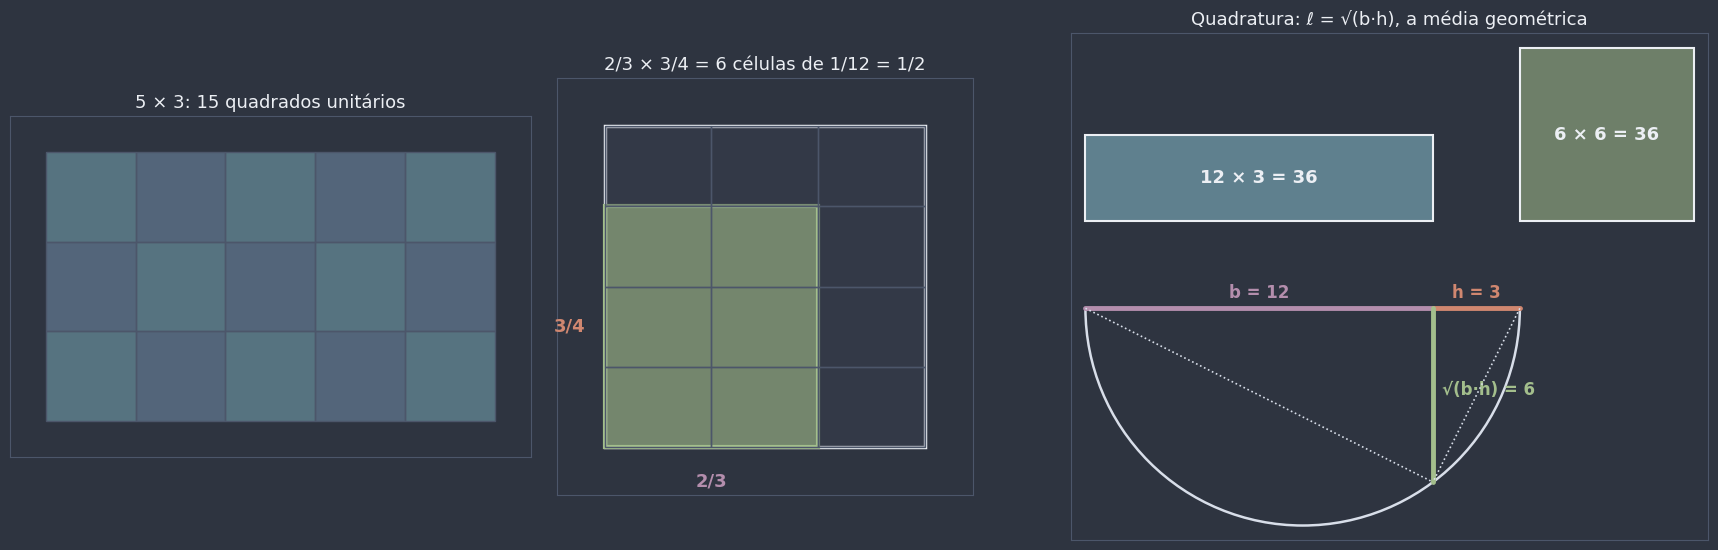

O retângulo 12 × 3 e o quadrado de lado 6 são equivalentes: 36 = 36.  ✓


In [5]:
def area_por_contagem(m: int, n: int, ax=None) -> int:
    """Conta os quadrados unitários que cobrem o retângulo de base m e altura n (inteiros); com `ax`,
    desenha a grade, pintando os quadradinhos em xadrez."""
    contagem = 0
    for i in range(m):
        for j in range(n):
            contagem += 1
            if ax is not None:
                cor = COR_FIGURA if (i + j) % 2 == 0 else COR_SECUNDARIA
                desenhar_peca(ax, [(i, j), (i + 1, j), (i + 1, j + 1), (i, j + 1)], cor=cor, opacidade=0.45,
                              largura=1, borda=NORD_LINHA)
    return contagem


def quadrado_equivalente(base: float, altura: float) -> float:
    """Lado do quadrado equivalente ao retângulo base × altura: a média geométrica √(base·altura)."""
    return math.sqrt(base * altura)


fig, (ax_1, ax_2, ax_3) = plt.subplots(1, 3, figsize=(18, 5.6), gridspec_kw={"width_ratios": [1, 0.8, 1.5]})
fig.patch.set_facecolor(NORD_FUNDO)

# (1) Lados inteiros: contar
total = area_por_contagem(5, 3, ax_1)
preparar_eixo(ax_1, [(0, 0), (5, 3)], margem=0.4)
ax_1.set_title(f"5 × 3: {total} quadrados unitários", color=NORD_TEXTO, fontsize=13)

# (2) Lados racionais: o quadrado unitário dividido em 3 × 4 células de 1/12
for i in range(3):
    for j in range(4):
        dentro = i < 2 and j < 3
        desenhar_peca(ax_2, [(i / 3, j / 4), ((i + 1) / 3, j / 4), ((i + 1) / 3, (j + 1) / 4), (i / 3, (j + 1) / 4)],
                      cor=COR_RESULTADO if dentro else NORD_PAINEL, opacidade=0.6 if dentro else 0.4, largura=1,
                      borda=NORD_LINHA)
desenhar_contorno(ax_2, [(0, 0), (1, 0), (1, 1), (0, 1)], cor=NORD_TEXTO, largura=2.5, estilo="-")
desenhar_contorno(ax_2, [(0, 0), (2 / 3, 0), (2 / 3, 3 / 4), (0, 3 / 4)], cor=COR_RESULTADO, largura=3, estilo="-")
ax_2.text(1 / 3, -0.08, "2/3", color=COR_BASE, fontsize=13, fontweight="bold", ha="center", va="top")
ax_2.text(-0.06, 3 / 8, "3/4", color=COR_ALTURA, fontsize=13, fontweight="bold", ha="right", va="center")
preparar_eixo(ax_2, [(0, 0), (1, 1)], margem=0.15)
ax_2.set_title("2/3 × 3/4 = 6 células de 1/12 = 1/2", color=NORD_TEXTO, fontsize=13)

# (3) Quadratura do retângulo 12 × 3: o quadrado de lado √36 = 6, construído pela semicircunferência
b, h = 12, 3
lado = quadrado_equivalente(b, h)
desenhar_peca(ax_3, [(0, 1), (b, 1), (b, 1 + h), (0, 1 + h)], cor=COR_FIGURA, rotulo=f"{b} × {h} = {b * h}", tamanho=13)
desenhar_peca(ax_3, [(b + 3, 1), (b + 3 + lado, 1), (b + 3 + lado, 1 + lado), (b + 3, 1 + lado)], cor=COR_RESULTADO,
              rotulo=f"{lado:g} × {lado:g} = {lado**2:g}", tamanho=13)
# construção: segmento de comprimento b + h sobre y = -2, semicircunferência e perpendicular na junção
y0, centro_x, raio = -2.0, (b + h) / 2, (b + h) / 2
ax_3.add_patch(Arc((centro_x, y0), 2 * raio, 2 * raio, theta1=180, theta2=360, color=NORD_TEXTO_SEC, lw=1.8))
desenhar_segmento(ax_3, (0, y0), (b, y0), cor=COR_BASE, largura=3.5)
desenhar_segmento(ax_3, (b, y0), (b + h, y0), cor=COR_ALTURA, largura=3.5)
pe_corda = (b, y0 - math.sqrt(b * h))
desenhar_segmento(ax_3, (b, y0), pe_corda, cor=COR_RESULTADO, largura=3.5)
desenhar_segmento(ax_3, (0, y0), pe_corda, cor=NORD_TEXTO_SEC, largura=1.2, estilo=":")
desenhar_segmento(ax_3, (b + h, y0), pe_corda, cor=NORD_TEXTO_SEC, largura=1.2, estilo=":")
ax_3.text(b / 2, y0 + 0.35, "b = 12", color=COR_BASE, fontsize=12, fontweight="bold", ha="center")
ax_3.text(b + h / 2, y0 + 0.35, "h = 3", color=COR_ALTURA, fontsize=12, fontweight="bold", ha="center")
ax_3.text(b + 0.3, y0 - lado / 2, "√(b·h) = 6", color=COR_RESULTADO, fontsize=12, fontweight="bold", ha="left")
preparar_eixo(ax_3, [(0, y0 - raio), (b + 3 + lado, 1 + lado)], margem=0.5)
ax_3.set_title("Quadratura: ℓ = √(b·h), a média geométrica", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

assert area_por_contagem(12, 3) == 36 and iguais(quadrado_equivalente(12, 3) ** 2, 12 * 3)
assert quadrado_equivalente(12, 3) == 6
print("O retângulo 12 × 3 e o quadrado de lado 6 são equivalentes: 36 = 36.  ✓")

### Uma régua de área para conferir: a fórmula do cadarço

Daqui em diante, cada demonstração vai ser acompanhada de uma **conferência numérica**: construímos a figura em coordenadas e medimos a área. Para isso serve a função `area_cadarco`, definida na célula de preparação. Ela recebe os vértices de um polígono **na ordem** do contorno e devolve a área pela **fórmula do cadarço** (em inglês, *shoelace*, porque os produtos cruzados lembram o laço de um tênis):

$$S = \frac{1}{2}\,\left| x_1 y_2 - x_2 y_1 + x_2 y_3 - x_3 y_2 + \cdots + x_n y_1 - x_1 y_n \right|.$$

📎 **Conexão:** por enquanto, ela é uma **caixa-preta**: a justificativa chega em Geometria Analítica (módulo 07), ligada aos determinantes de [`0305a_determinantes.ipynb`](../03_progressoes_matrizes_e_sistemas_lineares/0305a_determinantes.ipynb). **Nenhuma demonstração deste notebook depende dela.** Ela só serve para conferir, do mesmo jeito que o "transferidor digital" `medir_angulo` conferia ângulos nos notebooks anteriores. E lembre: uma conferência numérica **ilustra** um teorema em alguns casos, mas **não substitui** a demonstração.

Abaixo, a régua de área é testada contra o que já sabemos: retângulos sorteados (contagem) e as peças do Tangram.

In [6]:
random.seed(19)
for _ in range(200):
    m, n = random.randint(1, 30), random.randint(1, 30)
    x0, y0 = random.uniform(-10, 10), random.uniform(-10, 10)  # o retângulo pode estar em qualquer lugar
    retangulo = [(x0, y0), (x0 + m, y0), (x0 + m, y0 + n), (x0, y0 + n)]
    assert iguais(area_cadarco(retangulo), area_por_contagem(m, n))
    assert iguais(area_cadarco(retangulo[::-1]), area_por_contagem(m, n))  # a ordem pode ser horária também

# Um "L" de 5 quadradinhos (contagem direta) e o Tangram
L = [(0, 0), (3, 0), (3, 1), (1, 1), (1, 3), (0, 3)]
print("Área do L pela régua de área:", area_cadarco(L), "(contando: 3 + 2 = 5)")
for nome in MONTAGENS:
    assert iguais(sum(area_cadarco(p) for p in montar_tangram(nome).values()), 16)
print("200 retângulos sorteados e as 4 montagens do Tangram conferem.  ✓")

Área do L pela régua de área: 5.0 (contando: 3 + 2 = 5)
200 retângulos sorteados e as 4 montagens do Tangram conferem.  ✓


🕹️ **Widget interativo — editor de retângulos:** escolha a base $b$ e a altura $h$ (inteiras). À esquerda, o retângulo coberto por quadrados unitários, com a contagem em tempo real; à direita, o **quadrado equivalente**, de lado $\sqrt{b \cdot h}$, pintado com a mesma área. O painel também mostra os **perímetros**: compare-os. Experimente $b = 4, h = 4$ e depois $b = 1, h = 7$.

In [7]:
def explorar_retangulo(b: int, h: int) -> None:
    lado = quadrado_equivalente(b, h)
    fig, (ax, ax_q, ax_lista) = plt.subplots(1, 3, figsize=(17, 5.6), gridspec_kw={"width_ratios": [1, 1, 0.9]})
    fig.patch.set_facecolor(NORD_FUNDO)
    contagem = area_por_contagem(b, h, ax)
    preparar_eixo(ax, [(0, 0), (12, 12)], margem=0.3)
    ax.set_title(f"Retângulo {b} × {h}: {contagem} quadradinhos", color=NORD_TEXTO, fontsize=13)
    desenhar_peca(ax_q, [(0, 0), (lado, 0), (lado, lado), (0, lado)], cor=COR_RESULTADO, opacidade=0.6,
                  rotulo=f"S = {lado**2:g}", tamanho=14)
    preparar_eixo(ax_q, [(0, 0), (12, 12)], margem=0.3)
    ax_q.set_title(f"Quadrado equivalente: ℓ = √{b * h} ≈ {lado:.3f}", color=NORD_TEXTO, fontsize=13)
    itens = [
        (f"área do retângulo: b·h = {b}·{h} = {b * h}", contagem == b * h),
        (f"área do quadrado: ℓ² = {lado**2:.4g}", iguais(lado**2, b * h)),
        (f"perímetro do retângulo: 2(b + h) = {2 * (b + h)}", True),
        (f"perímetro do quadrado: 4ℓ ≈ {4 * lado:.3f}", True),
        ("mesma área, perímetros " + ("iguais" if iguais(2 * (b + h), 4 * lado) else "DIFERENTES"), True),
        (f"quadrado de perímetro {2 * (b + h)}: lado {(b + h) / 2:g}, área {((b + h) / 2) ** 2:g}", True),
    ]
    escrever_checklist(ax_lista, itens, "Área × perímetro")
    plt.tight_layout()
    plt.show()


widgets.interact(explorar_retangulo, b=widgets.IntSlider(value=4, min=1, max=12, description="b:"),
                 h=widgets.IntSlider(value=4, min=1, max=12, description="h:"));

interactive(children=(IntSlider(value=4, description='b:', max=12, min=1), IntSlider(value=4, description='h:'…

⚠️ **Erro comum: confundir perímetro com área.** O perímetro mede o **contorno** (um comprimento); a área mede a **região** (uma superfície). Figuras com o mesmo perímetro podem ter áreas muito diferentes, e figuras com a mesma área podem ter perímetros muito diferentes. Os quatro retângulos abaixo têm **todos** perímetro 16.

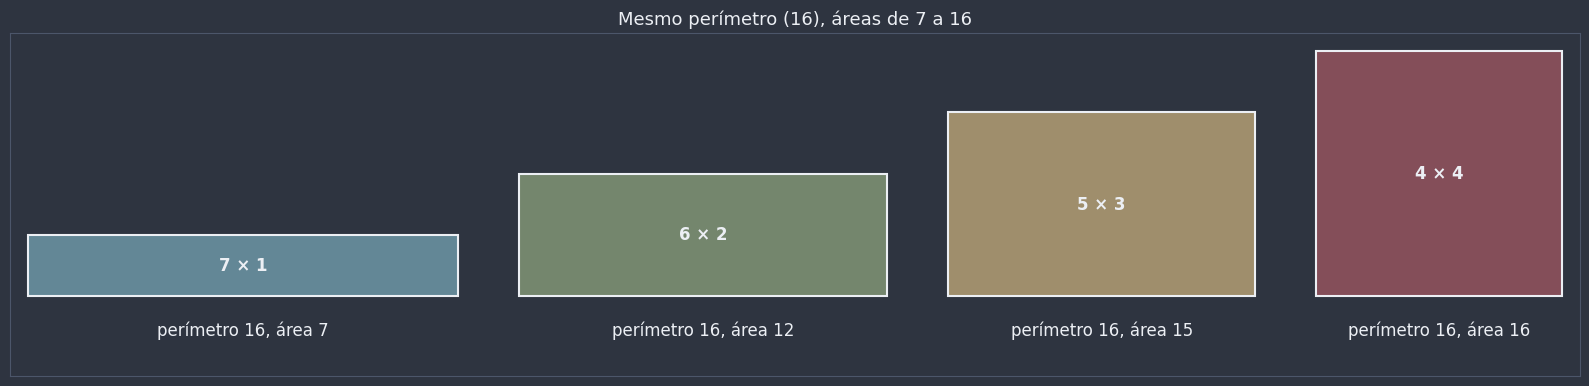

,retângulo,perímetro,área
0,7 × 1,16,7
1,6 × 2,16,12
2,5 × 3,16,15
3,4 × 4,16,16


In [8]:
fig, ax = plt.subplots(figsize=(16, 4.6))
fig.patch.set_facecolor(NORD_FUNDO)
x_inicio, linhas = 0, []
for (b, h), cor in zip([(7, 1), (6, 2), (5, 3), (4, 4)], CORES_PECAS[:4]):
    desenhar_peca(ax, [(x_inicio, 0), (x_inicio + b, 0), (x_inicio + b, h), (x_inicio, h)], cor=cor, opacidade=0.6,
                  rotulo=f"{b} × {h}", tamanho=12)
    ax.text(x_inicio + b / 2, -0.4, f"perímetro {2 * (b + h)}, área {b * h}", color=NORD_TEXTO, fontsize=12,
            ha="center", va="top")
    linhas.append({"retângulo": f"{b} × {h}", "perímetro": 2 * (b + h), "área": b * h})
    x_inicio += b + 1
preparar_eixo(ax, [(0, -1), (x_inicio - 1, 4)], margem=0.3)
ax.set_title("Mesmo perímetro (16), áreas de 7 a 16", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()
display(pd.DataFrame(linhas))

Entre os retângulos de mesmo perímetro, o **quadrado** é o que tem a maior área (no widget, o quadrado equivalente sempre tem perímetro **menor ou igual** ao do retângulo). É a versão "retangular" do fato visto no Desafio 10 de 0418a: para o mesmo contorno, as figuras mais "redondas" cercam mais área.

🎯 **Aplicação prática — quebra-cabeças e mosaicos:** o Tangram, os mosaicos de pisos e os quebra-cabeças de "dissecação" exploram exatamente a regra da aditividade: figuras diferentes, mesmas peças, mesma área. Em obras, o pedreiro calcula a quantidade de piso pela **área** do cômodo, e o rodapé pelo **perímetro**: trocar um pelo outro é o erro comum acima, com prejuízo real.

📖 **Leitura complementar:** [Área](https://pt.wikipedia.org/wiki/%C3%81rea) e [Tangram](https://pt.wikipedia.org/wiki/Tangram)

**Pergunta de checagem:** um retângulo de $12 \times 3$ equivale a um quadrado de que lado?

**Pergunta de checagem:** o retângulo $1 \times 7$ tem o mesmo perímetro de qual quadrado? Esse quadrado tem a mesma área do retângulo?

## 2. Transformando figuras: paralelogramo, triângulo, trapézio e losango

Agora a grande ideia em ação. Para cada figura nova, a pergunta é sempre a mesma: **como eu transformo isto em um retângulo** (ou em algo que já sei medir), cortando e recolando?

### 2.1 Paralelogramo = retângulo

Seja $ABCD$ um paralelogramo de base $AB = b$ e altura $h$ (a distância entre as retas $AB$ e $CD$, [`0407a_perpendicularidade.ipynb`](0407a_perpendicularidade.ipynb)). Baixe a altura $\overline{DH}$, com $H$ na reta $AB$.

1. **Corte** o triângulo $AHD$ (retângulo em $H$).
2. **Deslize** esse triângulo para a direita, pela distância $b$, até que o lado $\overline{AD}$ coincida com $\overline{BC}$.
3. O triângulo deslizado fica **congruente** ao original (deslizar é um movimento rígido), e ele se encaixa perfeitamente: $AD = BC$ e $AD \parallel BC$ (propriedades do paralelogramo, [`0409a_paralelogramos_e_casos_particulares.ipynb`](0409a_paralelogramos_e_casos_particulares.ipynb)), e os ângulos em $A$ e em $B$ (do lado de fora) são **correspondentes** entre paralelas ([`0406a_paralelismo.ipynb`](0406a_paralelismo.ipynb)), então o corte "cola" sem buraco nem sobreposição.
4. A figura nova é um **retângulo** de base $b$ e altura $h$.

Pelas regras 2 e 3, as áreas são iguais:

$$S(\text{paralelogramo}) = b \cdot h.$$

**A área não depende da inclinação.** Se você "empurrar" o lado de cima do paralelogramo ao longo da sua reta, mantendo a base e a altura, a área **não muda**: todos os paralelogramos de mesma base e mesma altura são equivalentes. (Esse "empurrar" se chama **cisalhamento**; quando o empurrão é grande, o corte precisa ser feito em mais de um pedaço, mas a conclusão é a mesma.)

🕵️ **Curiosidade histórica — Cavalieri:** no século XVII, o italiano **Bonaventura Cavalieri** formulou um princípio que generaliza essa observação: se duas figuras são cortadas por retas paralelas e cada reta encontra, nas duas, segmentos de mesmo comprimento, então as figuras têm a mesma área. Num paralelogramo e num retângulo de mesma base e altura, toda reta paralela à base corta um segmento de comprimento $b$ nos dois. O **princípio de Cavalieri** ficou famoso na versão para **sólidos e volumes**, que você vai usar em Geometria Espacial; esta é só uma analogia plana.

### 2.2 Triângulo = metade de um paralelogramo

Seja $ABC$ um triângulo de base $AB = b$ e altura $h$. Faça uma **cópia** do triângulo e gire-a meia-volta (180°) em torno do ponto médio $M$ do lado $\overline{BC}$. A cópia leva $B$ em $C$, $C$ em $B$ e $A$ num ponto $D$, e as duas peças juntas formam o quadrilátero $ABDC$, cujas diagonais $\overline{AD}$ e $\overline{BC}$ se cortam no ponto médio $M$ de ambas: pelo critério de 0409a, é um **paralelogramo**, de base $b$ e altura $h$. Os dois triângulos são **congruentes** (a cópia girada é congruente, ou, olhando de novo para o paralelogramo pronto, a diagonal $\overline{BC}$ o divide em dois triângulos congruentes pelo caso LLL). Então

$$S(\text{triângulo}) = \frac{S(\text{paralelogramo})}{2} = \frac{b \cdot h}{2}.$$

📎 Esta é a justificativa prometida em [`0417a_triangulos_quaisquer.ipynb`](0417a_triangulos_quaisquer.ipynb): lá, a fórmula $S = \frac{b \cdot h}{2}$ foi usada para chegar em Herão, em $r = \frac{S}{p}$ e em $R = \frac{abc}{4S}$; agora ela tem chão firme.

**Corolário (muito usado):** triângulos de **mesma base** e **mesma altura** são equivalentes. Se o vértice oposto desliza ao longo de uma reta **paralela à base**, a altura não muda (a distância entre duas paralelas é constante, 0407a), e a área também não.

### 2.3 Trapézio

Seja um trapézio de bases $B$ e $b$ e altura $h$. Faça uma cópia e gire-a 180° em torno do ponto médio de um dos lados não paralelos. As duas peças formam um **paralelogramo** de base $B + b$ e altura $h$ (a base maior de uma emenda com a base menor da outra). Logo

$$S(\text{trapézio}) = \frac{(B + b) \cdot h}{2} = \underbrace{\frac{B + b}{2}}_{\text{base média}} \cdot\, h.$$

📎 A área do trapézio é a **base média** ([`0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb`](0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb)) vezes a altura: o trapézio é equivalente ao retângulo cuja base é a base média. Exemplo: o trapézio isósceles de bases 10 e 4 e lados 5 de 0416a tem altura $\sqrt{5^2 - 3^2} = 4$ e área $\frac{(10 + 4) \cdot 4}{2} = 28$.

### 2.4 Losango (e todo quadrilátero de diagonais perpendiculares)

As diagonais $d_1$ e $d_2$ de um losango são **perpendiculares** e se cortam no ponto médio (0409a). Trace, pelos quatro vértices, paralelas às diagonais: elas formam um retângulo $d_1 \times d_2$ "em volta" do losango. As diagonais dividem esse retângulo em **oito** triângulos retângulos congruentes (catetos $\frac{d_1}{2}$ e $\frac{d_2}{2}$): quatro dentro do losango e quatro nos cantos. Cada canto, girado meia-volta em torno do ponto médio do lado do losango, cai exatamente sobre um triângulo de dentro. Então o losango é **metade** do retângulo:

$$S(\text{losango}) = \frac{d_1 \cdot d_2}{2}.$$

O argumento só usa diagonais perpendiculares, então a fórmula vale para **qualquer quadrilátero convexo de diagonais perpendiculares** (a pipa, por exemplo). Exemplo: diagonais 10 e 24 dão $S = 120$. Conferência pelo paralelogramo (o losango **é** um paralelogramo): o lado mede $\sqrt{5^2 + 12^2} = 13$, então a altura relativa ao lado é $\frac{120}{13} \approx 9{,}23$.

### 2.5 A estratégia

💡 **Dica:** diante de uma figura nova, pergunte "**como eu transformo isto num retângulo?**". Paralelogramo: corta um triângulo e desliza. Triângulo: duplica e vira paralelogramo. Trapézio: duplica e vira paralelogramo. Losango: completa um retângulo e mostra que é a metade.

📌 **Definição formal (as fórmulas deduzidas):**

| Figura | Área | Transformação |
|---|---|---|
| retângulo | $b \cdot h$ | quadrados unitários (seção 1) |
| quadrado | $\ell^2$ | retângulo com $b = h = \ell$ |
| paralelogramo | $b \cdot h$ | corta um triângulo e desliza: vira retângulo |
| triângulo | $\frac{b \cdot h}{2}$ | duas cópias formam um paralelogramo |
| trapézio | $\frac{(B + b) \cdot h}{2}$ | duas cópias formam um paralelogramo de base $B + b$ |
| losango | $\frac{d_1 \cdot d_2}{2}$ | metade do retângulo $d_1 \times d_2$ |

O catálogo completo (com Herão, $S = p \cdot r$, $S = p \cdot a$, círculo e setores) fica para 📌 Áreas de Superfícies Planas; aqui, o que importa é o **porquê**.

A célula abaixo constrói cada transformação em coordenadas, com as peças e os movimentos, e confere as áreas com a régua de área.

In [9]:
def area_retangulo(b: float, h: float) -> float:
    return b * h


def area_paralelogramo(b: float, h: float) -> float:
    """Paralelogramo de base b e altura h: equivalente ao retângulo b × h (corta e desliza)."""
    return b * h


def area_triangulo(b: float, h: float) -> float:
    """Triângulo de base b e altura h: metade do paralelogramo formado com uma cópia girada."""
    return b * h / 2


def area_trapezio(B: float, b: float, h: float) -> float:
    """Trapézio de bases B e b e altura h: metade do paralelogramo de base B + b (base média × altura)."""
    return (B + b) * h / 2


def area_losango(d1: float, d2: float) -> float:
    """Losango (ou quadrilátero de diagonais perpendiculares): metade do retângulo d1 × d2."""
    return d1 * d2 / 2


def corte_e_cola(figura: str, t: float) -> dict:
    """As peças de cada transformação da seção 2 na fração t do movimento (t = 0: figura original; t = 1:
    figura transformada). Devolve as peças fixas, as peças móveis, o contorno da figura original e o da
    figura de chegada, e as medidas usadas na fórmula."""
    if figura == "paralelogramo":
        b, h, s = 6.0, 4.0, 2.5
        original = [(0, 0), (b, 0), (b + s, h), (s, h)]
        fixas = [[(s, 0), (b, 0), (b + s, h), (s, h)]]
        moveis = [mover([(0, 0), (s, 0), (s, h)], t, vetor=(b, 0))]
        chegada = [(s, 0), (b + s, 0), (b + s, h), (s, h)]
        medidas = {"b": b, "h": h, "fórmula": area_paralelogramo(b, h)}
    elif figura == "triângulo":
        b, h = 6.0, 4.0
        A, B, C = (0, 0), (b, 0), (2.0, h)
        original = [A, B, C]
        fixas = [[A, B, C]]
        moveis = [mover([A, B, C], t, centro=ponto_medio(B, C), graus=180)]
        D = girar([A], ponto_medio(B, C), 180)[0]
        chegada = [A, B, D, C]
        medidas = {"b": b, "h": h, "fórmula": area_triangulo(b, h)}
    elif figura == "trapézio":
        B_, b_, h = 8.0, 4.0, 4.0
        original = [(0, 0), (B_, 0), (6.5, h), (6.5 - b_, h)]
        fixas = [original]
        moveis = [mover(original, t, centro=ponto_medio(original[1], original[2]), graus=180)]
        chegada = [(0, 0), (B_ + b_, 0), (B_ + 6.5, h), (6.5 - b_, h)]
        medidas = {"B": B_, "b": b_, "h": h, "fórmula": area_trapezio(B_, b_, h)}
    elif figura == "losango":
        d1, d2 = 8.0, 6.0
        E, N, W, S_ = (d1 / 2, 0), (0, d2 / 2), (-d1 / 2, 0), (0, -d2 / 2)
        original = [E, N, W, S_]
        fixas = [original]
        cantos = [[E, (d1 / 2, d2 / 2), N], [N, (-d1 / 2, d2 / 2), W], [W, (-d1 / 2, -d2 / 2), S_],
                  [S_, (d1 / 2, -d2 / 2), E]]
        moveis = [mover(c, t, centro=ponto_medio(c[0], c[2]), graus=180) for c in cantos]
        chegada = [(d1 / 2, -d2 / 2), (d1 / 2, d2 / 2), (-d1 / 2, d2 / 2), (-d1 / 2, -d2 / 2)]
        medidas = {"d₁": d1, "d₂": d2, "fórmula": area_losango(d1, d2)}
    else:
        raise ValueError(figura)
    return {"fixas": fixas, "moveis": moveis, "original": original, "chegada": chegada, "medidas": medidas}


# Conferência: em cada transformação, as peças somam a figura de chegada, e a fórmula bate com a régua de área
for figura in ("paralelogramo", "triângulo", "trapézio", "losango"):
    fim = corte_e_cola(figura, 1.0)
    soma_pecas = sum(area_cadarco(p) for p in fim["fixas"] + fim["moveis"])
    if figura == "losango":  # os cantos caem SOBRE o losango: losango = soma dos cantos = metade do retângulo
        assert iguais(sum(area_cadarco(p) for p in fim["moveis"]), area_cadarco(fim["original"]))
        assert iguais(area_cadarco(fim["original"]), area_cadarco(fim["chegada"]) / 2)
    elif figura in ("triângulo", "trapézio"):  # duas cópias formam o paralelogramo de chegada
        assert iguais(soma_pecas, area_cadarco(fim["chegada"]))
        assert iguais(area_cadarco(fim["original"]), area_cadarco(fim["chegada"]) / 2)
    else:  # paralelogramo: as peças recortadas formam o retângulo
        assert iguais(soma_pecas, area_cadarco(fim["chegada"]))
        assert iguais(area_cadarco(fim["original"]), area_cadarco(fim["chegada"]))
    assert iguais(area_cadarco(fim["original"]), fim["medidas"]["fórmula"])
    print(f"{figura:>13}: área pela fórmula = {fim['medidas']['fórmula']:g};  pela régua de área = "
          f"{area_cadarco(fim['original']):g}  ✓")

# Figuras sorteadas: as fórmulas contra a régua de área
random.seed(2)
for _ in range(300):
    b, h, s = random.uniform(0.5, 9), random.uniform(0.5, 9), random.uniform(-9, 9)
    assert iguais(area_paralelogramo(b, h), area_cadarco([(0, 0), (b, 0), (b + s, h), (s, h)]))
    assert iguais(area_triangulo(b, h), area_cadarco([(0, 0), (b, 0), (s, h)]))
    B_, b_ = b + random.uniform(0.1, 5), b
    assert iguais(area_trapezio(B_, b_, h), area_cadarco([(0, 0), (B_, 0), (s + b_, h), (s, h)]))
    d1, d2 = random.uniform(0.5, 9), random.uniform(0.5, 9)
    assert iguais(area_losango(d1, d2), area_cadarco([(d1 / 2, 0), (0, d2 / 2), (-d1 / 2, 0), (0, -d2 / 2)]))
print("300 paralelogramos, triângulos, trapézios e losangos sorteados conferem.  ✓")

paralelogramo: área pela fórmula = 24;  pela régua de área = 24  ✓
    triângulo: área pela fórmula = 12;  pela régua de área = 12  ✓
     trapézio: área pela fórmula = 24;  pela régua de área = 24  ✓
      losango: área pela fórmula = 24;  pela régua de área = 24  ✓
300 paralelogramos, triângulos, trapézios e losangos sorteados conferem.  ✓


A representação gráfica das quatro transformações: em cima, a figura original com as peças que vão se mover (em amarelo); embaixo, as peças já recolocadas, com o contorno da figura obtida em verde.

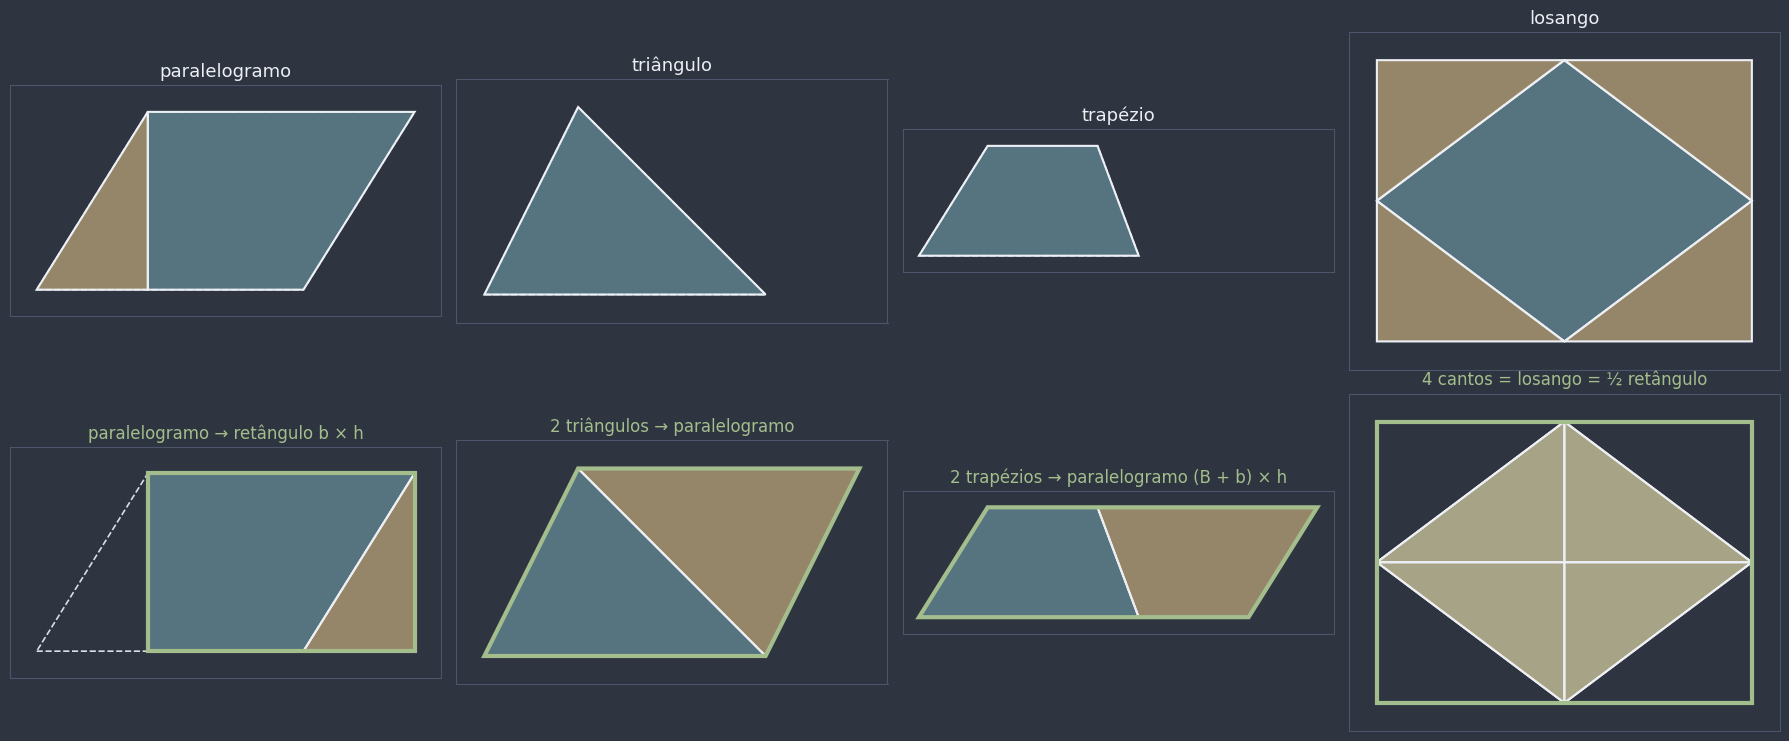

In [10]:
def desenhar_corte_e_cola(ax, figura: str, t: float, tamanho: int = 12) -> None:
    """Desenha a transformação `figura` na fração t: peças fixas (azul-claro), móveis (amarelo), o contorno
    da figura original (tracejado) e o da figura de chegada (verde, quando t = 1)."""
    estado = corte_e_cola(figura, t)
    for p in estado["fixas"]:
        desenhar_peca(ax, p, cor=COR_FIGURA, opacidade=0.45)
    if t > 0 or figura not in ("triângulo", "trapézio"):  # em t = 0 a cópia ainda coincide com a original
        for p in estado["moveis"]:
            desenhar_peca(ax, p, cor=COR_MOVEL, opacidade=0.55, zorder=4)
    desenhar_contorno(ax, estado["original"], cor=NORD_TEXTO_SEC, largura=1.2)
    if t >= 0.999:
        desenhar_contorno(ax, estado["chegada"], cor=COR_RESULTADO, largura=3, estilo="-", zorder=6)
    todos = np.vstack([estado["chegada"], estado["original"]] + estado["moveis"])
    preparar_eixo(ax, todos, margem=0.6)


fig, eixos = plt.subplots(2, 4, figsize=(18, 7.5))
fig.patch.set_facecolor(NORD_FUNDO)
titulos = {"paralelogramo": "paralelogramo → retângulo b × h", "triângulo": "2 triângulos → paralelogramo",
           "trapézio": "2 trapézios → paralelogramo (B + b) × h", "losango": "4 cantos = losango = ½ retângulo"}
for coluna, figura in enumerate(titulos):
    desenhar_corte_e_cola(eixos[0, coluna], figura, 0.0)
    desenhar_corte_e_cola(eixos[1, coluna], figura, 1.0)
    eixos[0, coluna].set_title(figura, color=NORD_TEXTO, fontsize=13)
    eixos[1, coluna].set_title(titulos[figura], color=COR_RESULTADO, fontsize=12)
plt.tight_layout()
plt.show()

🕹️ **Widget interativo — cortar e colar em câmera lenta:** escolha a figura e arraste o slider $t$ de 0 a 1: a peça amarela se desloca (deslizando ou girando meia-volta) até a posição final. O painel à direita mostra as áreas medidas a cada instante: a **soma das peças nunca muda** durante o movimento, porque cada peça é só deslocada (regra 2).

In [11]:
def explorar_corte_e_cola(figura: str, t: float) -> None:
    estado = corte_e_cola(figura, t)
    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(15.5, 6), gridspec_kw={"width_ratios": [1.4, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    desenhar_corte_e_cola(ax, figura, t)
    fim = corte_e_cola(figura, 1.0)
    preparar_eixo(ax, np.vstack([fim["chegada"], fim["original"]] + fim["moveis"]), margem=0.6)
    ax.set_title(f"{figura}, t = {t:.2f}", color=NORD_TEXTO, fontsize=13)
    medidas = {k: v for k, v in estado["medidas"].items() if k != "fórmula"}
    soma_moveis = sum(area_cadarco(p) for p in estado["moveis"])
    formulas = {"paralelogramo": "S = b·h", "triângulo": "S = b·h/2", "trapézio": "S = (B + b)·h/2",
                "losango": "S = d₁·d₂/2"}
    itens = [
        ("medidas: " + ",  ".join(f"{k} = {v:g}" for k, v in medidas.items()), True),
        (f"área da figura original: {area_cadarco(estado['original']):g}", True),
        (f"área das peças móveis agora: {soma_moveis:g}  (não muda com t)",
         iguais(soma_moveis, sum(area_cadarco(p) for p in corte_e_cola(figura, 0)["moveis"]))),
        (f"área da figura de chegada: {area_cadarco(estado['chegada']):g}", True),
        (f"fórmula {formulas[figura]} = {estado['medidas']['fórmula']:g}",
         iguais(estado["medidas"]["fórmula"], area_cadarco(estado["original"]))),
    ]
    escrever_checklist(ax_lista, itens, "Áreas medidas")
    plt.tight_layout()
    plt.show()


widgets.interact(explorar_corte_e_cola,
                 figura=widgets.Dropdown(options=["paralelogramo", "triângulo", "trapézio", "losango"],
                                         value="paralelogramo", description="figura:"),
                 t=widgets.FloatSlider(value=0.5, min=0, max=1, step=0.05, description="t:"));

interactive(children=(Dropdown(description='figura:', options=('paralelogramo', 'triângulo', 'trapézio', 'losa…

🕹️ **Widget interativo — a área não depende da inclinação:** à esquerda, um paralelogramo de base 6 e altura 4 cujo lado de cima você empurra com o slider "deslocamento" (cisalhamento); à direita, um triângulo de base 6 cujo vértice $C$ desliza numa reta paralela à base, à altura 4. Observe os números: a **área fica parada** enquanto o **perímetro** muda (e muito). O gráfico de baixo mostra o perímetro do paralelogramo para todos os deslocamentos, com a área constante em verde.

In [ ]:
def explorar_inclinacao(deslocamento: float) -> None:
    b, h = 6.0, 4.0
    P = [(0, 0), (b, 0), (b + deslocamento, h), (deslocamento, h)]
    C = (deslocamento + 2.0, h)
    T = [(0, 0), (b, 0), C]
    fig = plt.figure(figsize=(16, 7.5))
    fig.patch.set_facecolor(NORD_FUNDO)
    ax_p = fig.add_subplot(2, 2, 1)
    ax_t = fig.add_subplot(2, 2, 2)
    ax_g = fig.add_subplot(2, 1, 2)
    for ax, fig_pts, nome in ((ax_p, P, "paralelogramo"), (ax_t, T, "triângulo")):
        desenhar_contorno(ax, [(0, 0), (b, 0), (b, h), (0, h)] if nome == "paralelogramo" else [(0, 0), (b, 0), (2, h)],
                          cor=NORD_LINHA, largura=1.2)
        desenhar_peca(ax, fig_pts, cor=COR_FIGURA, opacidade=0.5)
        desenhar_segmento(ax, (0, 0), (b, 0), cor=COR_BASE, largura=4)
        topo = fig_pts[-1] if nome == "paralelogramo" else C
        desenhar_segmento(ax, topo, (topo[0], 0), cor=COR_ALTURA, largura=2.5, estilo="--")
        ax.axhline(h, color=NORD_TEXTO_SEC, lw=1, linestyle=":", zorder=0)
        perimetro = sum(math.dist(fig_pts[k], fig_pts[(k + 1) % len(fig_pts)]) for k in range(len(fig_pts)))
        ax.set_title(f"{nome}: área = {area_cadarco(fig_pts):g},  perímetro = {perimetro:.2f}", color=NORD_TEXTO,
                     fontsize=13)
        estilizar_eixo(ax)
        ax.grid(False)
        ax.set_xlim(-7, 15)
        ax.set_ylim(-0.8, 5)
        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])
    estilizar_eixo(ax_g)
    ds = np.linspace(-6, 6, 241)
    ax_g.plot(ds, [2 * b + 2 * math.hypot(d, h) for d in ds], color=COR_FIGURA, lw=2, label="perímetro do paralelogramo")
    ax_g.axhline(b * h, color=COR_RESULTADO, lw=2, linestyle="--", label="área do paralelogramo = b·h = 24")
    ax_g.plot(deslocamento, 2 * b + 2 * math.hypot(deslocamento, h), "o", color=COR_MOVEL, markersize=10)
    ax_g.set_xlabel("deslocamento do lado de cima", color=NORD_TEXTO)
    ax_g.legend(facecolor=NORD_PAINEL, edgecolor=NORD_LINHA, labelcolor=NORD_TEXTO, loc="upper center")
    plt.tight_layout()
    plt.show()


widgets.interact(explorar_inclinacao,
                 deslocamento=widgets.FloatSlider(value=3, min=-6, max=6, step=0.5, description="deslocamento:"));

interactive(children=(FloatSlider(value=3.0, description='deslocamento:', max=6.0, min=-6.0, step=0.5), Output…

A área depende só da **base** e da **altura**; o "quanto o paralelogramo está deitado" mexe no perímetro, mas não na área. E o mesmo vale para o triângulo: o vértice pode andar à vontade na paralela.

Os números de 0416a, conferidos com as fórmulas recém-demonstradas:

In [13]:
# Trapézio isósceles de bases 10 e 4 e lados 5 (0416a): a altura sai de Pitágoras no triângulo de catetos 3 e h
h_trap = math.sqrt(5**2 - ((10 - 4) / 2) ** 2)
trapezio = [(0, 0), (10, 0), (7, h_trap), (3, h_trap)]
print(f"trapézio: h = {h_trap:g}, S = (10 + 4)·{h_trap:g}/2 = {area_trapezio(10, 4, h_trap):g}, "
      f"régua de área = {area_cadarco(trapezio):g}")

# Losango de diagonais 10 e 24: lado 13, área 120, altura relativa ao lado = 120/13
losango = [(5, 0), (0, 12), (-5, 0), (0, -12)]
lado_l = math.dist(losango[0], losango[1])
altura_l = area_losango(10, 24) / lado_l
print(f"losango: lado = {lado_l:g}, S = 10·24/2 = {area_losango(10, 24):g}, altura relativa ao lado = 120/13 ≈ "
      f"{altura_l:.4f}, distância entre lados opostos medida = {distancia_ponto_reta(losango[2], losango[0], losango[1]):.4f}")
assert iguais(area_trapezio(10, 4, h_trap), 28) and iguais(area_cadarco(trapezio), 28)
assert iguais(area_cadarco(losango), 120) and iguais(altura_l, distancia_ponto_reta(losango[2], losango[0], losango[1]))

trapézio: h = 4, S = (10 + 4)·4/2 = 28, régua de área = 28
losango: lado = 13, S = 10·24/2 = 120, altura relativa ao lado = 120/13 ≈ 9.2308, distância entre lados opostos medida = 9.2308


⚠️ **Erro comum: usar o lado inclinado no lugar da altura.** A altura é a distância **perpendicular** entre a base e o lado oposto (ou o vértice oposto), não o comprimento do lado inclinado (0407a). Um paralelogramo de lados 5 e 8 **não** tem, necessariamente, área 40: o widget acima mostra paralelogramos de lados 6 e $\sqrt{d^2 + 16}$ com área sempre 24. A área 40 só aparece se o paralelogramo for um retângulo.

⚠️ **Erro comum: esquecer o fator $\frac{1}{2}$** no triângulo, no trapézio e no losango. Os três foram obtidos como **metade** de alguma coisa (um paralelogramo ou um retângulo). Se a conta deu o dobro do esperado, foi ele que fugiu.

🎯 **Aplicação prática — terrenos, pisos e telhados:** terrenos com formato de trapézio (comuns em esquinas) têm área $\frac{(B + b) \cdot h}{2}$, onde $h$ é a profundidade medida **perpendicularmente** às frentes paralelas, e não o comprimento da divisa inclinada. Num telhado, cada "pano" é um retângulo ou um trapézio **inclinado**: a área de telhas depende da largura medida **ao longo da inclinação** do pano (a hipotenusa), e não da sua projeção horizontal (a planta). Calcular telhas pela planta da casa é um erro clássico de orçamento.

**Pergunta de checagem:** um trapézio tem bases 10 e 4 e altura 4. Qual é a área?

**Pergunta de checagem:** um losango tem diagonais 10 e 24. Qual é a área? E a altura relativa ao lado (que mede 13)?

## 3. Triângulos de mesma altura: dividindo áreas

Uma consequência simples de $S = \frac{b \cdot h}{2}$ vai render muitos teoremas. Se dois triângulos têm a **mesma altura** $h$ (por exemplo, um vértice comum e as bases sobre a mesma reta), então

$$\frac{S_1}{S_2} = \frac{\frac{b_1 \cdot h}{2}}{\frac{b_2 \cdot h}{2}} = \frac{b_1}{b_2}:$$

**as áreas estão na mesma razão que as bases.** (E, do mesmo jeito, triângulos de mesma base têm áreas na razão das alturas.)

### 3.1 A mediana divide o triângulo em duas metades equivalentes

Seja $M$ o ponto médio de $\overline{BC}$. Os triângulos $ABM$ e $AMC$ têm a mesma altura (a de $A$ até a reta $BC$) e bases iguais ($BM = MC$). Logo $S(ABM) = S(AMC) = \frac{S}{2}$.

**As três medianas dividem o triângulo em seis triângulos equivalentes**, cada um com $\frac{S}{6}$. Demonstração: seja $G$ o baricentro e $M_a$, $M_b$, $M_c$ os pontos médios de $\overline{BC}$, $\overline{CA}$ e $\overline{AB}$. Os dois pedaços apoiados em $\overline{BC}$, $GBM_a$ e $GM_aC$, têm bases iguais e a mesma altura (a de $G$): chame a área de cada um de $x$. Do mesmo jeito, os dois apoiados em $\overline{CA}$ valem $y$ cada, e os dois apoiados em $\overline{AB}$ valem $z$ cada.
- A mediana $\overline{AM_a}$ divide o triângulo em duas metades: $S(ABM_a) = z + z + x$ e $S(AM_aC) = x + y + y$. Igualando, $z = y$.
- A mediana $\overline{BM_b}$ dá, do mesmo jeito, $S(BCM_b) = x + x + y$ e $S(BM_bA) = y + z + z$, logo $x = z$.

Então $x = y = z$, e cada pedaço vale $\frac{S}{6}$. ∎ (A primeira figura mais abaixo mostra os seis pedaços.)

**Bônus: outra demonstração de que o baricentro divide cada mediana na razão $2 : 1$** (retomando [`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb) e o desafio de 0414a). O triângulo $GBC$ é formado por dois dos seis pedaços, então $S(GBC) = \frac{2S}{6} = \frac{S}{3}$. Mas $GBC$ e $ABC$ têm a **mesma base** $\overline{BC}$, então as áreas estão na razão das alturas: a altura de $G$ é $\frac{1}{3}$ da altura de $A$. Como $G$ está na mediana $\overline{AM_a}$, as distâncias à reta $BC$ crescem proporcionalmente ao longo dela (Tales, 0414a), e $GM_a = \frac{1}{3} AM_a$, isto é, $AG : GM_a = 2 : 1$. ∎

### 3.2 O teorema da bissetriz interna, por áreas

Seja $\overline{AD}$ a bissetriz do ângulo $\hat{A}$, com $D$ em $\overline{BC}$, e lados $AB = c$ e $AC = b$ (notação de 0417a).

1. $ABD$ e $ADC$ têm a mesma altura (a de $A$ até $BC$): $\frac{S(ABD)}{S(ADC)} = \frac{BD}{DC}$.
2. $D$ está na bissetriz, então está à **mesma distância** $d$ dos lados $\overline{AB}$ e $\overline{AC}$ (0410a). Tomando esses lados como bases: $S(ABD) = \frac{c \cdot d}{2}$ e $S(ADC) = \frac{b \cdot d}{2}$, e a razão vale $\frac{c}{b}$.
3. Igualando: $$\frac{BD}{DC} = \frac{c}{b}.$$ ∎

É o teorema de [`0414a_teorema_de_tales.ipynb`](0414a_teorema_de_tales.ipynb), agora sem Tales, só com áreas. No triângulo 13–14–15 de 0417a ($c = 13$, $b = 15$), a bissetriz de $A$ divide a área 84 na razão $13 : 15$: $39$ e $45$.

### 3.3 No paralelogramo

- As duas diagonais dividem o paralelogramo em **quatro triângulos equivalentes** (as diagonais se cortam ao meio, 0409a, então cada diagonal é mediana dos dois triângulos formados pela outra).
- Para **qualquer** ponto $P$ interior ao paralelogramo $ABCD$: $$S(PAB) + S(PCD) = \frac{S(ABCD)}{2}.$$ Os dois triângulos têm bases $AB = CD = b$, e as suas alturas (as distâncias de $P$ às retas $AB$ e $CD$) **somam a altura** $h$ do paralelogramo. Então $\frac{b \cdot h_1}{2} + \frac{b \cdot h_2}{2} = \frac{b(h_1 + h_2)}{2} = \frac{b \cdot h}{2}$. ∎

### 3.4 No trapézio

No trapézio $ABCD$ ($AB \parallel CD$), as diagonais $\overline{AC}$ e $\overline{BD}$ se cortam em $P$. Os triângulos "laterais" $ADP$ e $BCP$ são **equivalentes**: $ABD$ e $ABC$ têm a mesma base $\overline{AB}$ e a mesma altura (os vértices $C$ e $D$ estão na mesma paralela a $AB$), então $S(ABD) = S(ABC)$. Retirando de ambos o triângulo $ABP$, que é comum, sobram $S(ADP) = S(BCP)$. ∎

### 3.5 O teorema de Viviani

> Num triângulo **equilátero**, a soma das distâncias de **qualquer** ponto interior aos três lados é **constante** e igual à **altura** do triângulo.

*Demonstração por áreas:* seja $\ell$ o lado, $h$ a altura e $d_1, d_2, d_3$ as distâncias de $P$ aos lados. Ligando $P$ aos três vértices, o triângulo fica dividido em três triângulos, cada um com base $\ell$ e altura $d_i$:

$$\frac{\ell \cdot d_1}{2} + \frac{\ell \cdot d_2}{2} + \frac{\ell \cdot d_3}{2} = \frac{\ell \cdot h}{2} \;\Longrightarrow\; d_1 + d_2 + d_3 = h. \quad ∎$$

📎 É a mesma ideia de $S = p \cdot r$ de [`0417a_triangulos_quaisquer.ipynb`](0417a_triangulos_quaisquer.ipynb): lá, o ponto era o incentro e as três distâncias valiam $r$; aqui, o ponto é qualquer, as distâncias variam, mas a soma não. (Só funciona com os três lados iguais: num triângulo qualquer, é a soma **ponderada** $a \cdot d_1 + b \cdot d_2 + c \cdot d_3 = 2S$ que fica constante.)

### 3.6 O triângulo medial

📎 Ligando os pontos médios dos três lados, a **base média** ([`0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb`](0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb)) mede metade do lado paralelo. Os quatro triângulos formados têm, cada um, lados iguais às metades de $a$, $b$ e $c$: são **congruentes** (LLL), e o triângulo medial tem $\frac{1}{4}$ da área (é a área $k^2 = \frac{1}{4}$ com $k = \frac{1}{2}$, que a seção 4 explica).

📌 **Definição formal (resumo da seção):**
- mesma altura $\Rightarrow \frac{S_1}{S_2} = \frac{b_1}{b_2}$;
- mediana $\Rightarrow$ duas metades; três medianas $\Rightarrow$ seis partes de $\frac{S}{6}$; $AG : GM = 2 : 1$;
- bissetriz: $\frac{BD}{DC} = \frac{c}{b}$;
- paralelogramo: $S(PAB) + S(PCD) = \frac{S}{2}$; trapézio: $S(ADP) = S(BCP)$;
- Viviani: $d_1 + d_2 + d_3 = h$ (equilátero).

Agora, as conferências numéricas. A área de cada triângulo é calculada por **base × altura / 2** (seção 2), com a altura medida como distância de ponto a reta (`distancia_ponto_reta`, 0407a), e comparada com a régua de área.

In [15]:
def area_triangulo_pontos(A, B, C) -> float:
    """Área do triângulo ABC por base × altura / 2: base AB e altura = distância de C à reta AB (seção 2)."""
    return math.dist(A, B) * distancia_ponto_reta(C, A, B) / 2


def triangulo_sorteado() -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Três vértices sorteados que formam um triângulo de verdade (área não muito pequena)."""
    while True:
        A, B, C = (np.array([random.uniform(-6, 6), random.uniform(-6, 6)]) for _ in range(3))
        if area_cadarco([A, B, C]) > 2:
            return A, B, C


def lados_ordenados(P, Q, R) -> list[float]:
    """Os três lados do triângulo PQR em ordem crescente (dois triângulos congruentes têm a mesma lista, LLL)."""
    return sorted([math.dist(P, Q), math.dist(Q, R), math.dist(R, P)])


random.seed(3)
for _ in range(500):
    A, B, C = triangulo_sorteado()
    S = area_triangulo_pontos(A, B, C)
    assert iguais(S, area_cadarco([A, B, C]))
    # 3.1 Seis triângulos das medianas e a razão 2 : 1
    G = (A + B + C) / 3
    Ma, Mb, Mc = ponto_medio(B, C), ponto_medio(C, A), ponto_medio(A, B)
    seis = [(A, Mc, G), (Mc, B, G), (B, Ma, G), (Ma, C, G), (C, Mb, G), (Mb, A, G)]
    assert all(iguais(area_triangulo_pontos(*t), S / 6) for t in seis)
    assert iguais(math.dist(A, G), 2 * math.dist(G, Ma))
    # 3.6 Triângulo medial: 1/4 da área, quatro triângulos congruentes (mesmos lados)
    assert iguais(area_triangulo_pontos(Ma, Mb, Mc), S / 4)
    quatro = [(A, Mc, Mb), (Mc, B, Ma), (Mb, Ma, C), (Ma, Mb, Mc)]
    assert all(np.allclose(lados_ordenados(*t), lados_ordenados(*quatro[0])) for t in quatro)
print("500 triângulos sorteados: seis pedaços de S/6, AG = 2·GM e triângulo medial = S/4.  ✓")

# 3.2 Bissetriz no triângulo 13–14–15 (B na origem, BC no eixo x)
B, C, A = np.array([0.0, 0.0]), np.array([14.0, 0.0]), np.array([5.0, 12.0])
u = (B - A) / math.dist(A, B) + (C - A) / math.dist(A, C)  # direção da bissetriz: soma dos unitários
D = A + (-A[1] / u[1]) * u  # onde a bissetriz encontra o eixo x (a reta BC)
S_ABD, S_ADC = area_triangulo_pontos(A, B, D), area_triangulo_pontos(A, D, C)
print(f"\nBissetriz no 13–14–15: BD = {math.dist(B, D):.4f}, DC = {math.dist(D, C):.4f}, BD/DC = "
      f"{math.dist(B, D) / math.dist(D, C):.6f}, c/b = 13/15 = {13 / 15:.6f}")
print(f"S(ABD) = {S_ABD:.4f}, S(ADC) = {S_ADC:.4f} (soma {S_ABD + S_ADC:.4f}); distâncias de D a AB e a AC: "
      f"{distancia_ponto_reta(D, A, B):.4f} e {distancia_ponto_reta(D, A, C):.4f}")
assert iguais(S_ABD, 39) and iguais(S_ADC, 45)

# 3.3 e 3.4 Paralelogramo e trapézio com pontos sorteados
random.seed(4)
for _ in range(500):
    b, h, s = random.uniform(1, 9), random.uniform(1, 9), random.uniform(-5, 5)
    A, B, C, D = (np.array(p, dtype=float) for p in [(0, 0), (b, 0), (b + s, h), (s, h)])
    P = A + random.random() * (B - A) + random.random() * (D - A)  # ponto interior qualquer
    assert iguais(area_triangulo_pontos(P, A, B) + area_triangulo_pontos(P, C, D), b * h / 2)
    O = ponto_medio(A, C)
    assert all(iguais(area_triangulo_pontos(O, X, Y), b * h / 4) for X, Y in ((A, B), (B, C), (C, D), (D, A)))
    # Trapézio ABCD com AB ∥ CD; P = cruzamento das diagonais (a razão AP/PC é B/b, por semelhança)
    B_, b_ = b + random.uniform(0.5, 5), b
    A, B, C, D = (np.array(p, dtype=float) for p in [(0, 0), (B_, 0), (s + b_, h), (s, h)])
    P = A + B_ / (B_ + b_) * (C - A)
    assert distancia_ponto_reta(P, B, D) < 1e-9  # P também está na diagonal BD
    assert iguais(area_triangulo_pontos(A, D, P), area_triangulo_pontos(B, C, P))
print("500 paralelogramos (S(PAB) + S(PCD) = S/2; quatro triângulos das diagonais) e 500 trapézios "
      "(S(ADP) = S(BCP)) conferem.  ✓")

# 3.5 Viviani: 300 pontos sorteados dentro do equilátero de lado 6
lado = 6.0
A, B, C = np.array([0.0, 0.0]), np.array([lado, 0.0]), np.array([lado / 2, lado * math.sqrt(3) / 2])
altura = lado * math.sqrt(3) / 2
somas = []
for _ in range(300):
    r1, r2 = random.random(), random.random()
    if r1 + r2 > 1:
        r1, r2 = 1 - r1, 1 - r2
    P = A + r1 * (B - A) + r2 * (C - A)  # sorteio uniforme dentro do triângulo
    somas.append(sum(distancia_ponto_reta(P, X, Y) for X, Y in ((A, B), (B, C), (C, A))))
print(f"\nViviani: 300 pontos, soma das distâncias entre {min(somas):.10f} e {max(somas):.10f}; "
      f"altura = 3√3 = {altura:.10f}")
assert all(iguais(s_, altura) for s_ in somas)

500 triângulos sorteados: seis pedaços de S/6, AG = 2·GM e triângulo medial = S/4.  ✓

Bissetriz no 13–14–15: BD = 6.5000, DC = 7.5000, BD/DC = 0.866667, c/b = 13/15 = 0.866667
S(ABD) = 39.0000, S(ADC) = 45.0000 (soma 84.0000); distâncias de D a AB e a AC: 6.0000 e 6.0000
500 paralelogramos (S(PAB) + S(PCD) = S/2; quatro triângulos das diagonais) e 500 trapézios (S(ADP) = S(BCP)) conferem.  ✓

Viviani: 300 pontos, soma das distâncias entre 5.1961524227 e 5.1961524227; altura = 3√3 = 5.1961524227


A representação gráfica dos seis resultados, cada um com as áreas medidas escritas dentro das peças.

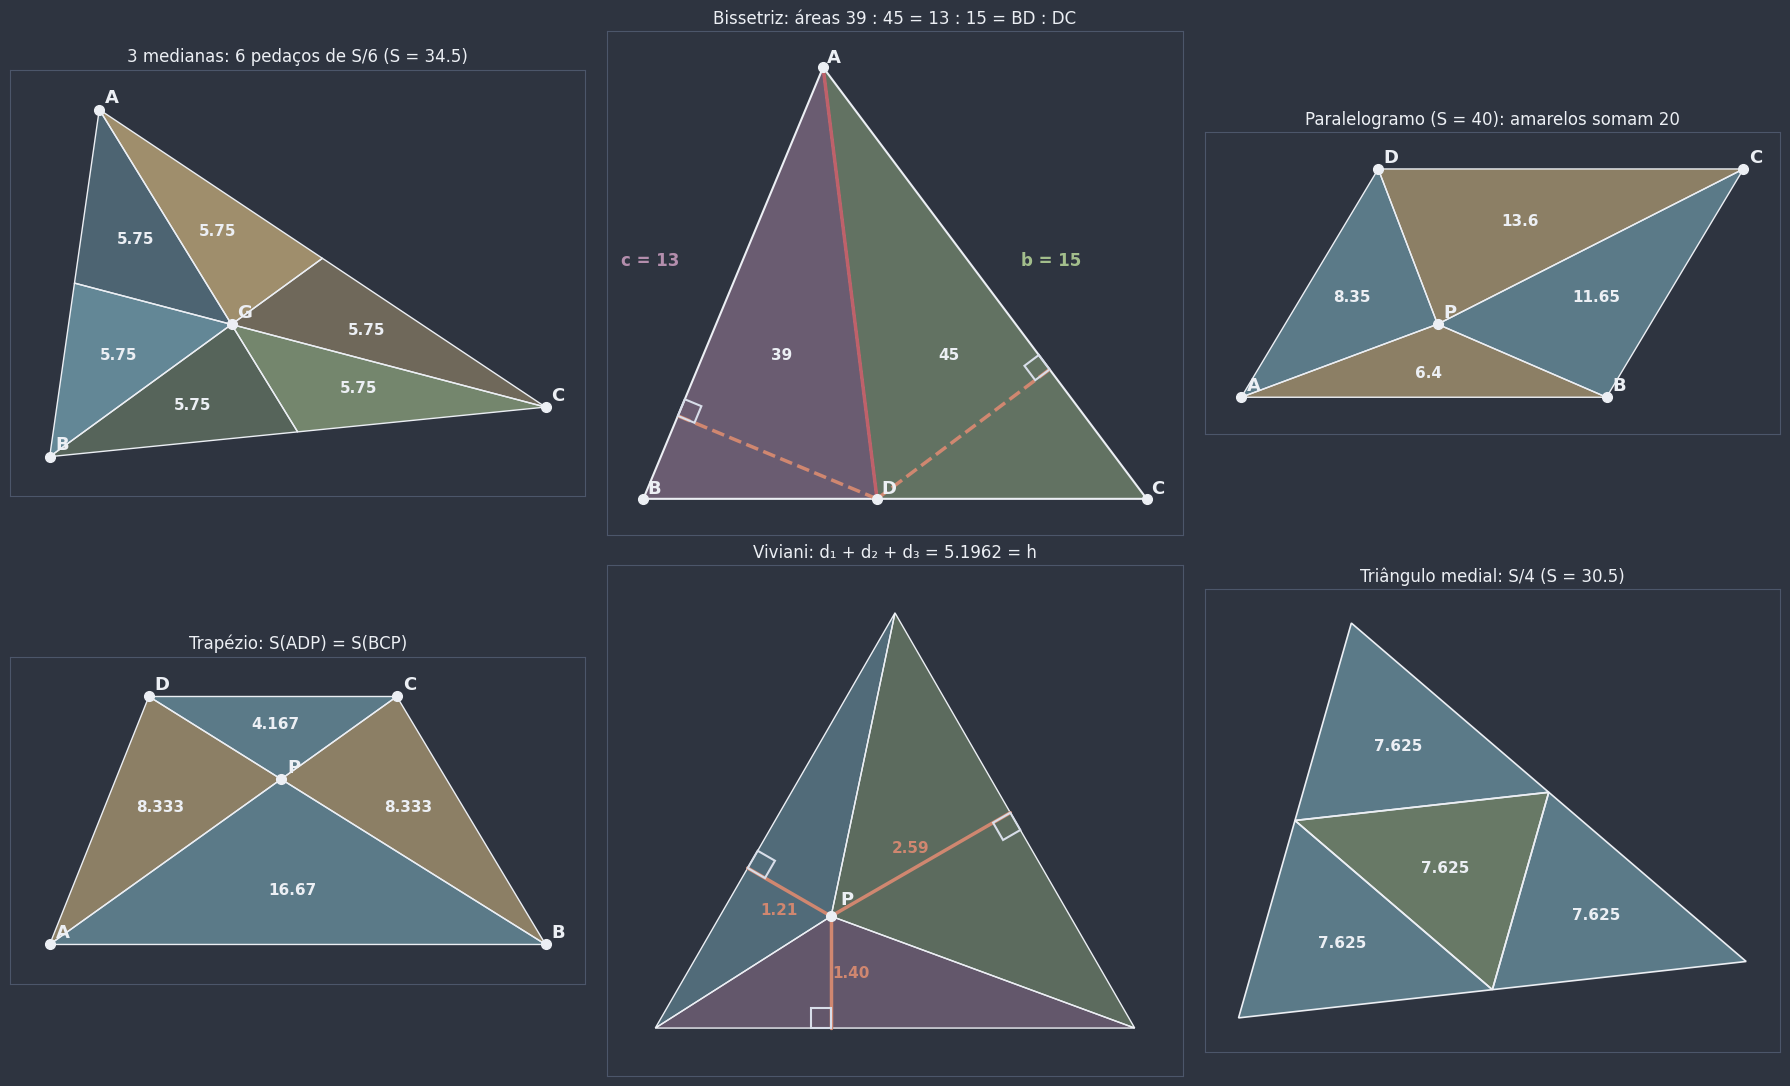

In [16]:
def rotular_area(ax, pontos, cor: str = NORD_TEXTO, tamanho: int = 11, prefixo: str = "") -> None:
    """Escreve a área (base × altura / 2) no centro do triângulo."""
    ax.text(*np.mean(pontos, axis=0), f"{prefixo}{area_triangulo_pontos(*pontos):.4g}", color=cor, fontsize=tamanho,
            fontweight="bold", ha="center", va="center", zorder=9)


fig, eixos = plt.subplots(2, 3, figsize=(18, 11))
fig.patch.set_facecolor(NORD_FUNDO)

# (1) Medianas: seis triângulos de S/6
ax = eixos[0, 0]
A, B, C = np.array([1.0, 7.0]), np.array([0.0, 0.0]), np.array([10.0, 1.0])
G = (A + B + C) / 3
Ma, Mb, Mc = ponto_medio(B, C), ponto_medio(C, A), ponto_medio(A, B)
for k, t in enumerate([(A, Mc, G), (Mc, B, G), (B, Ma, G), (Ma, C, G), (C, Mb, G), (Mb, A, G)]):
    desenhar_peca(ax, t, cor=CORES_PECAS[k // 2], opacidade=0.35 + 0.25 * (k % 2), largura=1)
    rotular_area(ax, t)
for X, nome in ((A, "A"), (B, "B"), (C, "C"), (G, "G")):
    desenhar_ponto(ax, X, nome, cor=NORD_TEXTO)
preparar_eixo(ax, [A, B, C], margem=0.8)
ax.set_title(f"3 medianas: 6 pedaços de S/6 (S = {area_triangulo_pontos(A, B, C):g})", color=NORD_TEXTO, fontsize=12)

# (2) Bissetriz no 13–14–15
ax = eixos[0, 1]
B, C, A = np.array([0.0, 0.0]), np.array([14.0, 0.0]), np.array([5.0, 12.0])
u = (B - A) / 13 + (C - A) / 15
D = A + (-A[1] / u[1]) * u
desenhar_peca(ax, [A, B, D], cor=COR_EXTRA, opacidade=0.45)
desenhar_peca(ax, [A, D, C], cor=COR_RESULTADO, opacidade=0.45)
rotular_area(ax, [A, B, D])
rotular_area(ax, [A, D, C])
for lado_ in ((A, B), (A, C)):  # as distâncias iguais de D aos lados AB e AC
    pe = pe_da_altura(D, *lado_)
    desenhar_segmento(ax, D, pe, cor=COR_ALTURA, largura=2.5, estilo="--")
    marcar_angulo_reto(ax, pe, D, lado_[0], tamanho=0.5)
desenhar_segmento(ax, A, D, cor=COR_ALERTA, largura=2.5)
for X, nome in ((A, "A"), (B, "B"), (C, "C"), (D, "D")):
    desenhar_ponto(ax, X, nome, cor=NORD_TEXTO)
ax.text(1.0, 6.5, "c = 13", color=COR_EXTRA, fontsize=12, fontweight="bold", ha="right")
ax.text(10.5, 6.5, "b = 15", color=COR_RESULTADO, fontsize=12, fontweight="bold")
preparar_eixo(ax, [A, B, C], margem=1.0)
ax.set_title("Bissetriz: áreas 39 : 45 = 13 : 15 = BD : DC", color=NORD_TEXTO, fontsize=12)

# (3) Paralelogramo com um ponto P
ax = eixos[0, 2]
A, B, C, D = (np.array(p, dtype=float) for p in [(0, 0), (8, 0), (11, 5), (3, 5)])
P = np.array([4.3, 1.6])
for t, cor in (((P, A, B), COR_MOVEL), ((P, C, D), COR_MOVEL), ((P, B, C), COR_FIGURA), ((P, D, A), COR_FIGURA)):
    desenhar_peca(ax, t, cor=cor, opacidade=0.5, largura=1)
    rotular_area(ax, t)
for X, nome in ((A, "A"), (B, "B"), (C, "C"), (D, "D"), (P, "P")):
    desenhar_ponto(ax, X, nome, cor=NORD_TEXTO)
preparar_eixo(ax, [A, B, C, D], margem=0.8)
ax.set_title("Paralelogramo (S = 40): amarelos somam 20", color=NORD_TEXTO, fontsize=12)

# (4) Trapézio: os triângulos laterais ADP e BCP
ax = eixos[1, 0]
A, B, C, D = (np.array(p, dtype=float) for p in [(0, 0), (10, 0), (7, 5), (2, 5)])
P = A + 10 / 15 * (C - A)
for t, cor in (((A, B, P), COR_FIGURA), ((C, D, P), COR_FIGURA), ((A, D, P), COR_MOVEL), ((B, C, P), COR_MOVEL)):
    desenhar_peca(ax, t, cor=cor, opacidade=0.5, largura=1)
    rotular_area(ax, t)
for X, nome in ((A, "A"), (B, "B"), (C, "C"), (D, "D"), (P, "P")):
    desenhar_ponto(ax, X, nome, cor=NORD_TEXTO)
preparar_eixo(ax, [A, B, C, D], margem=0.8)
ax.set_title("Trapézio: S(ADP) = S(BCP)", color=NORD_TEXTO, fontsize=12)

# (5) Viviani
ax = eixos[1, 1]
A, B, C = np.array([0.0, 0.0]), np.array([6.0, 0.0]), np.array([3.0, 3 * math.sqrt(3)])
P = np.array([2.2, 1.4])
for (X, Y), cor in zip(((A, B), (B, C), (C, A)), (COR_EXTRA, COR_RESULTADO, COR_FIGURA)):
    desenhar_peca(ax, (P, X, Y), cor=cor, opacidade=0.4, largura=1)
    pe = pe_da_altura(P, X, Y)
    desenhar_segmento(ax, P, pe, cor=COR_ALTURA, largura=2.5)
    marcar_angulo_reto(ax, pe, P, X, tamanho=0.25)
    rotular_segmento(ax, P, pe, f"{math.dist(P, pe):.2f}", cor=COR_ALTURA, distancia=0.25, tamanho=11)
desenhar_ponto(ax, P, "P", cor=NORD_TEXTO)
preparar_eixo(ax, [A, B, C], margem=0.6)
soma_d = sum(distancia_ponto_reta(P, X, Y) for X, Y in ((A, B), (B, C), (C, A)))
ax.set_title(f"Viviani: d₁ + d₂ + d₃ = {soma_d:.4f} = h", color=NORD_TEXTO, fontsize=12)

# (6) Triângulo medial
ax = eixos[1, 2]
A, B, C = np.array([2.0, 7.0]), np.array([0.0, 0.0]), np.array([9.0, 1.0])
Ma, Mb, Mc = ponto_medio(B, C), ponto_medio(C, A), ponto_medio(A, B)
for t, cor in (((A, Mc, Mb), COR_FIGURA), ((Mc, B, Ma), COR_FIGURA), ((Mb, Ma, C), COR_FIGURA), ((Ma, Mb, Mc), COR_RESULTADO)):
    desenhar_peca(ax, t, cor=cor, opacidade=0.5, largura=1.2)
    rotular_area(ax, t)
preparar_eixo(ax, [A, B, C], margem=0.6)
ax.set_title(f"Triângulo medial: S/4 (S = {area_triangulo_pontos(A, B, C):g})", color=NORD_TEXTO, fontsize=12)
plt.tight_layout()
plt.show()

🕹️ **Widget interativo — o ponto de Viviani:** mova o ponto $P$ com os sliders $x$ e $y$ dentro do triângulo equilátero de lado 6. As três distâncias aos lados (laranja) mudam, as três áreas parciais (coloridas) mudam, mas a **soma das distâncias** fica sempre igual à altura $3\sqrt{3} \approx 5{,}196$, e a **soma das áreas** fica sempre igual a $S = 9\sqrt{3}$. Leve $P$ para perto de um vértice e depois para fora do triângulo: o que acontece?

In [ ]:
def explorar_viviani(x: float, y: float) -> None:
    A, B, C = np.array([0.0, 0.0]), np.array([6.0, 0.0]), np.array([3.0, 3 * math.sqrt(3)])
    P = np.array([x, y])
    h = 3 * math.sqrt(3)
    dentro = all(vetorial(Y - X, P - X) >= -1e-12 for X, Y in ((A, B), (B, C), (C, A)))
    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(15.5, 6.5), gridspec_kw={"width_ratios": [1.15, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    desenhar_contorno(ax, [A, B, C], cor=NORD_TEXTO, largura=2.5, estilo="-")
    distancias, areas = [], []
    for (X, Y), cor in zip(((A, B), (B, C), (C, A)), (COR_EXTRA, COR_RESULTADO, COR_FIGURA)):
        desenhar_peca(ax, (P, X, Y), cor=cor, opacidade=0.4, largura=1)
        pe = pe_da_altura(P, X, Y)
        desenhar_segmento(ax, P, pe, cor=COR_ALTURA, largura=2.5)
        distancias.append(math.dist(P, pe))
        areas.append(area_triangulo_pontos(P, X, Y))
    desenhar_ponto(ax, P, "P", cor=NORD_TEXTO)
    preparar_eixo(ax, [(-1, -1), (7, 6)], margem=0.2)
    ax.set_title("P dentro do triângulo" if dentro else "P FORA do triângulo", color=NORD_TEXTO if dentro else COR_ALERTA,
                 fontsize=13)
    S = 9 * math.sqrt(3)
    itens = [
        (f"d₁ (até AB) = {distancias[0]:.4f}", True),
        (f"d₂ (até BC) = {distancias[1]:.4f}", True),
        (f"d₃ (até CA) = {distancias[2]:.4f}", True),
        (f"d₁ + d₂ + d₃ = {sum(distancias):.4f};  h = 3√3 ≈ {h:.4f}", iguais(sum(distancias), h)),
        (f"áreas: {areas[0]:.3f} + {areas[1]:.3f} + {areas[2]:.3f} = {sum(areas):.4f}", True),
        (f"S = 9√3 ≈ {S:.4f}", iguais(sum(areas), S)),
    ]
    escrever_checklist(ax_lista, itens, "Teorema de Viviani")
    plt.tight_layout()
    plt.show()


widgets.interact(explorar_viviani, x=widgets.FloatSlider(value=2.2, min=-0.5, max=6.5, step=0.1, description="x:"),
                 y=widgets.FloatSlider(value=1.4, min=-0.5, max=5.5, step=0.1, description="y:"));

interactive(children=(FloatSlider(value=2.2, description='x:', max=6.5, min=-0.5), FloatSlider(value=1.4, desc…

Com $P$ **fora** do triângulo, a soma passa a ser **maior** que a altura: as três áreas parciais deixam de "cobrir" o triângulo sem sobrar (uma delas fica de fora e precisaria ser **subtraída**). A demonstração por áreas mostra exatamente onde a hipótese "$P$ interior" foi usada: na regra 3, que exige partes sem sobreposição.

💡 **Dica:** "mesma altura $\Rightarrow$ áreas na razão das bases" é, provavelmente, a ferramenta mais usada nos problemas de geometria de olimpíada. Diante de uma figura cheia de cevianas, procure triângulos com um vértice comum e bases na mesma reta.

🎯 **Aplicação prática — partilha justa:** três irmãos herdam um terreno triangular e querem parti-lo em três lotes de **mesma área**, todos com acesso a um poço no vértice $A$. Basta dividir o lado oposto $\overline{BC}$ em **três partes iguais** e cercar a partir de $A$: os três triângulos têm a mesma altura e bases iguais. (Para dois irmãos, a cerca é a **mediana**.)

🎯 **Aplicação prática — Viviani numa sala:** numa sala com formato de triângulo equilátero, a soma das distâncias de um ponto às três paredes é a mesma em todo lugar. Se o custo de levar cabos de um ponto até as três paredes (pelo caminho mais curto, perpendicular) é proporcional ao comprimento total, **qualquer** posição dentro da sala custa o mesmo.

📖 **Leitura complementar:** [Teorema de Viviani](https://pt.wikipedia.org/wiki/Teorema_de_Viviani)

**Pergunta de checagem:** num triângulo de área 60, $G$ é o baricentro. Qual é a área do triângulo $GBC$?

**Pergunta de checagem:** num triângulo equilátero de lado 6, a soma das distâncias de um ponto interior qualquer aos três lados vale quanto?

## 4. Pitágoras por áreas e a razão $k^2$ entre figuras semelhantes

Em [`0416a_triangulos_retangulos.ipynb`](0416a_triangulos_retangulos.ipynb), o Teorema de Pitágoras foi demonstrado por **semelhança** (as relações métricas) e ilustrado por uma prova visual com quatro triângulos. Agora vamos demonstrá-lo como os gregos faziam: **só com áreas**, cortando, deslizando e girando.

Nesta seção, as cores seguem 0416a: o cateto $c$ e a sua projeção $m$ são **roxos**; o cateto $b$ e a sua projeção $n$ são **verdes**; a hipotenusa é $a$. Os triângulos que se movem continuam **amarelos**.

### 4.1 A demonstração de Euclides

É a demonstração da Proposição 47 do Livro I dos *Elementos* de Euclides (por volta de 300 a.C.), e ela **não usa semelhança**. Seja $ABC$ retângulo em $A$, com $A = (0, 0)$, $B = (c, 0)$ e $C = (0, b)$. Construa os quadrados sobre os três lados, para fora do triângulo, e trace a altura $\overline{AH}$, prolongada até cortar o quadrado da hipotenusa em dois **retângulos**: um junto a $B$, de lados $a$ e $m = BH$, e outro junto a $C$, de lados $a$ e $n = HC$.

**Afirmação:** o quadrado sobre o cateto $\overline{AB}$ é **equivalente** ao retângulo $a \times m$.

1. Seja $F = (c, -c)$ o vértice do quadrado de $\overline{AB}$ adjacente a $B$, e $D$ o vértice do quadrado da hipotenusa adjacente a $B$. Considere os triângulos $FBC$ e $ABD$.
2. **$FBC \cong ABD$ (LAL):** $FB = AB = c$ (lados do mesmo quadrado), $BC = BD = a$ (idem) e os ângulos em $B$ são iguais: $F\hat{B}C = 90° + A\hat{B}C$ e $A\hat{B}D = 90° + A\hat{B}C$. (De fato, girar $FBC$ de 90° em torno de $B$, no sentido horário, leva $F$ em $A$ e $C$ em $D$.) Então $S(FBC) = S(ABD)$.
3. **$S(FBC)$ é metade do quadrado de $\overline{AB}$:** a reta $CA$ é **paralela** a $FB$ (as duas são verticais). Deslizando o vértice $C$ por essa paralela até $A$, a área não muda (corolário da seção 2): $S(FBC) = S(FBA) = \frac{c^2}{2}$.
4. **$S(ABD)$ é metade do retângulo $a \times m$:** a reta $AH$ é **paralela** a $BD$ (as duas são perpendiculares a $BC$). Deslizando o vértice $A$ por essa paralela até $H$: $S(ABD) = S(HBD) = \frac{a \cdot m}{2}$.
5. Juntando 2, 3 e 4: $\frac{c^2}{2} = \frac{a \cdot m}{2}$, isto é, $$c^2 = a \cdot m.$$

É a primeira relação métrica de 0416a, agora provada por áreas! O mesmo argumento, do outro lado, dá $b^2 = a \cdot n$. Somando:

$$b^2 + c^2 = a \cdot n + a \cdot m = a\,(m + n) = a \cdot a = a^2. \quad ∎$$

A célula abaixo confere cada passo em coordenadas, para vários triângulos retângulos; depois, um widget mostra a demonstração passo a passo.

In [18]:
def figura_euclides(b: float, c: float) -> dict:
    """Pontos da figura de Euclides para o triângulo retângulo A = (0, 0), B = (c, 0), C = (0, b): quadrados
    sobre os três lados (para fora), o pé H da altura e o ponto K onde a altura prolongada corta o lado DE."""
    a = math.hypot(b, c)
    A, B, C = np.array([0.0, 0.0]), np.array([c, 0.0]), np.array([0.0, b])
    fora = np.array([b, c]) / a  # direção perpendicular a BC, para longe de A
    D, E = B + a * fora, C + a * fora
    H = pe_da_altura(A, B, C)
    K = H + a * fora
    return {"A": A, "B": B, "C": C, "D": D, "E": E, "H": H, "K": K, "F": np.array([c, -c]), "G": np.array([0.0, -c]),
            "I": np.array([-b, b]), "J": np.array([-b, 0.0]), "a": a, "b": b, "c": c,
            "m": math.dist(B, H), "n": math.dist(H, C)}


for b, c in ((4, 3), (3, 4), (5, 12), (1, 1), (2.5, 7.1), (6, 1.3)):
    f = figura_euclides(b, c)
    A, B, C, D, F, H, K = (f[k] for k in "ABCDFHK")
    assert np.allclose(lados_ordenados(F, B, C), lados_ordenados(A, B, D))  # passo 2: congruentes (LAL ⇒ LLL)
    assert np.allclose(girar([F, C], B, -90), [A, D])  # o giro de 90° (horário) em torno de B leva FBC em ABD
    assert iguais(area_triangulo_pontos(F, B, C), c**2 / 2)  # passo 3
    assert iguais(area_triangulo_pontos(A, B, D), f["a"] * f["m"] / 2)  # passo 4
    assert iguais(area_cadarco([B, D, K, H]), c**2)  # o retângulo junto a B é equivalente ao quadrado de AB
    assert iguais(area_cadarco([H, K, f["E"], C]), b**2)  # e o junto a C, ao quadrado de AC
    assert iguais(b**2 + c**2, f["a"] ** 2)
    print(f"b = {b:>4}, c = {c:>4}:  c² = {c**2:8.4f} = a·m = {f['a'] * f['m']:8.4f};   "
          f"b² = {b**2:8.4f} = a·n = {f['a'] * f['n']:8.4f}")

b =    4, c =    3:  c² =   9.0000 = a·m =   9.0000;   b² =  16.0000 = a·n =  16.0000
b =    3, c =    4:  c² =  16.0000 = a·m =  16.0000;   b² =   9.0000 = a·n =   9.0000
b =    5, c =   12:  c² = 144.0000 = a·m = 144.0000;   b² =  25.0000 = a·n =  25.0000
b =    1, c =    1:  c² =   1.0000 = a·m =   1.0000;   b² =   1.0000 = a·n =   1.0000
b =  2.5, c =  7.1:  c² =  50.4100 = a·m =  50.4100;   b² =   6.2500 = a·n =   6.2500
b =    6, c =  1.3:  c² =   1.6900 = a·m =   1.6900;   b² =  36.0000 = a·n =  36.0000


🕹️ **Widget interativo — Euclides passo a passo:** use o slider "passo" (0 a 4) e escolha os catetos $b$ e $c$. Passo 0: os três quadrados. Passo 1: o triângulo $FBC$ e o deslizamento de $C$ até $A$ ($FBC$ vale metade do quadrado roxo). Passo 2: o giro de 90° em torno de $B$ que leva $FBC$ em $ABD$ (com posições intermediárias). Passo 3: o deslizamento de $A$ até $H$ ($ABD$ vale metade do retângulo $BDKH$). Passo 4: o quadrado roxo e o retângulo roxo são equivalentes, assim como o quadrado verde e o retângulo verde.

In [19]:
def desenhar_euclides(ax, f: dict, passo: int, tamanho: int = 12) -> None:
    A, B, C, D, E, F, G, H, I, J, K = (f[k] for k in "ABCDEFGHIJK")
    preencher_c = passo in (0, 4)
    desenhar_peca(ax, [A, B, F, G], cor=COR_EXTRA, opacidade=0.45 if preencher_c else 0.12, largura=1.5)
    desenhar_peca(ax, [A, C, I, J], cor=COR_DESTAQUE, opacidade=0.45 if passo in (0, 4) else 0.12, largura=1.5)
    desenhar_peca(ax, [B, D, E, C], cor=NORD_PAINEL, opacidade=0.3, largura=1.5)
    desenhar_peca(ax, [A, B, C], cor=COR_FIGURA, opacidade=0.6, largura=2)
    desenhar_segmento(ax, A, K, cor=COR_ALTURA, largura=2, estilo="--")
    if passo == 4:
        desenhar_peca(ax, [B, D, K, H], cor=COR_EXTRA, opacidade=0.45, rotulo=f"a·m = {f['a'] * f['m']:.3g}", tamanho=tamanho)
        desenhar_peca(ax, [H, K, E, C], cor=COR_DESTAQUE, opacidade=0.45, rotulo=f"a·n = {f['a'] * f['n']:.3g}",
                      tamanho=tamanho)
        ax.text(*np.mean([A, B, F, G], axis=0), f"c² = {f['c'] ** 2:.3g}", color=NORD_TEXTO, fontsize=tamanho,
                fontweight="bold", ha="center", va="center", zorder=9)
        ax.text(*np.mean([A, C, I, J], axis=0), f"b² = {f['b'] ** 2:.3g}", color=NORD_TEXTO, fontsize=tamanho,
                fontweight="bold", ha="center", va="center", zorder=9)
    if passo == 1:
        desenhar_peca(ax, [F, B, C], cor=COR_MOVEL, opacidade=0.5, zorder=5)
        desenhar_peca(ax, [F, B, A], cor=COR_EXTRA, opacidade=0.55, zorder=4)
        desenhar_segmento(ax, C, A, cor=COR_MOVEL, largura=3, estilo=":")
        ax.annotate("", xy=A + (0, 0.25), xytext=C, arrowprops=dict(arrowstyle="->", color=COR_MOVEL, lw=2.5), zorder=9)
    if passo == 2:
        for fracao, alpha in ((0.33, 0.15), (0.66, 0.25)):
            desenhar_contorno(ax, girar([F, B, C], B, -90 * fracao), cor=COR_MOVEL, largura=1.3, estilo=":")
        desenhar_peca(ax, [F, B, C], cor=COR_MOVEL, opacidade=0.35, zorder=5)
        desenhar_peca(ax, [A, B, D], cor=COR_MOVEL, opacidade=0.6, zorder=5)
        ax.add_patch(Arc(B, 1.2, 1.2, theta1=180, theta2=270, color=COR_MOVEL, lw=2.5, zorder=9))
    if passo == 3:
        desenhar_peca(ax, [A, B, D], cor=COR_MOVEL, opacidade=0.5, zorder=5)
        desenhar_peca(ax, [H, B, D], cor=COR_EXTRA, opacidade=0.55, zorder=4)
        ax.annotate("", xy=H, xytext=A, arrowprops=dict(arrowstyle="->", color=COR_MOVEL, lw=2.5), zorder=9)
    centro = (A + B + C) / 3
    for X, nome in zip((A, B, C, D, E, F, H, K), "ABCDEFHK"):
        rotular_fora(ax, X, nome, centro, distancia=0.35, tamanho=tamanho)
    preparar_eixo(ax, [I, J, G, F, D, E], margem=0.5)


TEXTOS_EUCLIDES = [
    "Quadrados sobre os três lados e a altura AH prolongada até K",
    "S(FBC) = S(FBA) = c²/2: o vértice C desliza na paralela CA ∥ FB",
    "Giro de 90° em torno de B: FBC ≅ ABD (LAL)",
    "S(ABD) = S(HBD) = a·m/2: o vértice A desliza na paralela AH ∥ BD",
    "c² = a·m e b² = a·n  ⇒  b² + c² = a(m + n) = a²",
]


def explorar_euclides(passo: int, b: float, c: float) -> None:
    f = figura_euclides(b, c)
    fig, ax = plt.subplots(figsize=(10, 9))
    fig.patch.set_facecolor(NORD_FUNDO)
    desenhar_euclides(ax, f, passo)
    ax.set_title(f"Passo {passo}: {TEXTOS_EUCLIDES[passo]}", color=NORD_TEXTO, fontsize=13)
    plt.tight_layout()
    plt.show()


widgets.interact(explorar_euclides, passo=widgets.IntSlider(value=2, min=0, max=4, description="passo:"),
                 b=widgets.FloatSlider(value=4, min=1, max=6, step=0.5, description="b:"),
                 c=widgets.FloatSlider(value=3, min=1, max=6, step=0.5, description="c:"));

interactive(children=(IntSlider(value=2, description='passo:', max=4), FloatSlider(value=4.0, description='b:'…

### 4.2 A demonstração do trapézio

Uma segunda demonstração, ainda mais curta. Segundo a tradição, ela foi publicada em 1876 por **James Garfield**, que anos depois se tornaria presidente dos Estados Unidos. Dois triângulos retângulos congruentes, de catetos $b$ e $c$ e hipotenusa $a$, são colocados lado a lado como na figura abaixo, com os catetos alinhados numa reta; o espaço entre eles é um terceiro triângulo, **retângulo e isósceles**, de catetos $a$ (o ângulo entre as duas hipotenusas é reto porque, no ponto de encontro, os três ângulos somam 180° e os dois agudos dos triângulos somam 90°). As três peças formam um **trapézio** de bases $b$ e $c$ e altura $b + c$. Somando as áreas (seção 2):

$$\frac{(b + c)\,(b + c)}{2} = 2 \cdot \frac{b \cdot c}{2} + \frac{a^2}{2} \;\Longrightarrow\; b^2 + 2bc + c^2 = 2bc + a^2 \;\Longrightarrow\; a^2 = b^2 + c^2. \quad ∎$$

📎 É **metade** da prova visual dos quatro triângulos de 0416a (o quadrado de lado $b + c$ cortado pela diagonal), agora com as áreas justificadas.

### 4.3 Pitágoras sem usar Pitágoras

Repare no que as duas provas usaram: as três regras da área, a congruência e as fórmulas do retângulo, do triângulo e do trapézio (seções 1 e 2). **Em nenhum momento** usaram o próprio Teorema de Pitágoras. Por isso elas **não são circulares**: a cadeia é quadrado unitário → retângulo → paralelogramo → triângulo → Pitágoras. E, de quebra, ficam justificadas as áreas de triângulos que 0416a e 0417a usaram "do ensino fundamental".

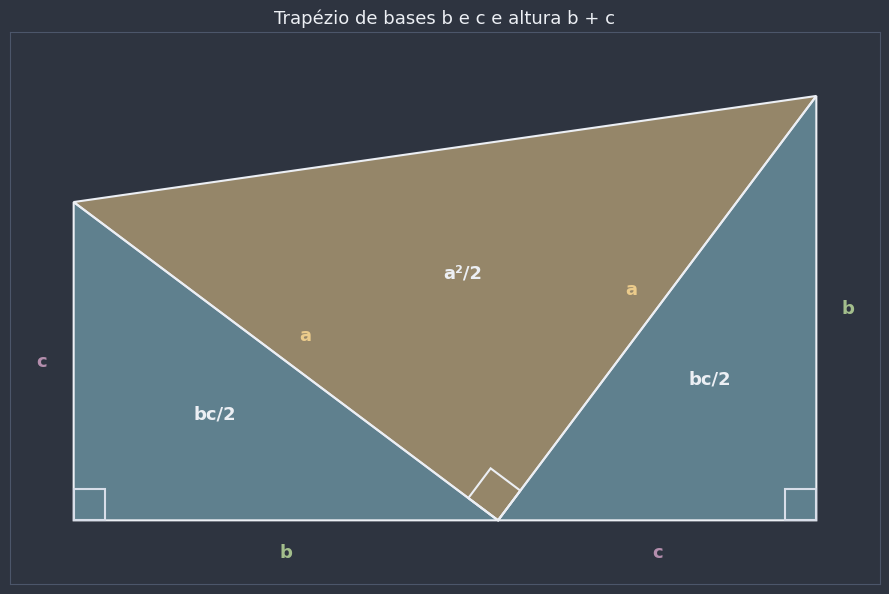

Trapézio: (b + c)²/2 = bc + a²/2 conferido em 4 triângulos retângulos.  ✓


In [20]:
def trapezio_garfield(b: float, c: float) -> dict:
    """As três peças do trapézio: dois triângulos retângulos de catetos b e c e o triângulo isósceles de catetos a."""
    Q, M, R = np.array([0.0, 0.0]), np.array([b, 0.0]), np.array([b + c, 0.0])
    U, V = np.array([0.0, c]), np.array([b + c, b])
    return {"t1": [Q, M, U], "t2": [M, R, V], "t3": [U, M, V], "trapezio": [Q, R, V, U]}


fig, ax = plt.subplots(figsize=(9, 6.5))
fig.patch.set_facecolor(NORD_FUNDO)
p = trapezio_garfield(4, 3)
desenhar_peca(ax, p["t1"], cor=COR_FIGURA, rotulo="bc/2", tamanho=13)
desenhar_peca(ax, p["t2"], cor=COR_FIGURA, rotulo="bc/2", tamanho=13)
desenhar_peca(ax, p["t3"], cor=COR_MOVEL, rotulo="a²/2", tamanho=13)
Q, M, U = p["t1"]
_, R, V = p["t2"]
marcar_angulo_reto(ax, M, U, V, tamanho=0.35, cor=NORD_TEXTO)
marcar_angulo_reto(ax, Q, M, U, tamanho=0.3)
marcar_angulo_reto(ax, R, V, M, tamanho=0.3)
rotular_segmento(ax, Q, M, "b", cor=COR_DESTAQUE, distancia=0.3, longe_de=U, tamanho=13)
rotular_segmento(ax, Q, U, "c", cor=COR_EXTRA, distancia=0.3, longe_de=M, tamanho=13)
rotular_segmento(ax, M, R, "c", cor=COR_EXTRA, distancia=0.3, longe_de=V, tamanho=13)
rotular_segmento(ax, R, V, "b", cor=COR_DESTAQUE, distancia=0.3, longe_de=M, tamanho=13)
rotular_segmento(ax, U, M, "a", cor=COR_AVISO, distancia=0.3, longe_de=Q, tamanho=13)
rotular_segmento(ax, M, V, "a", cor=COR_AVISO, distancia=0.3, longe_de=R, tamanho=13)
preparar_eixo(ax, p["trapezio"], margem=0.6)
ax.set_title("Trapézio de bases b e c e altura b + c", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

for b, c in ((4, 3), (12, 5), (1, 1), (2.7, 9.4)):
    p = trapezio_garfield(b, c)
    U, M, V = p["t3"]
    a = math.dist(U, M)
    assert iguais(math.dist(M, V), a) and iguais(np.dot(U - M, V - M), 0)  # isósceles e retângulo em M
    assert iguais(area_trapezio(c, b, b + c), 2 * area_triangulo(b, c) + area_triangulo(a, a))
    assert iguais(sum(area_cadarco(p[k]) for k in ("t1", "t2", "t3")), area_cadarco(p["trapezio"]))
print("Trapézio: (b + c)²/2 = bc + a²/2 conferido em 4 triângulos retângulos.  ✓")

### 4.4 A razão entre áreas de figuras semelhantes é $k^2$

📎 Prometido em [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb): quando uma figura é ampliada (ou reduzida) na razão $k$, **todos os comprimentos** ficam multiplicados por $k$, e a **área** fica multiplicada por $k^2$. Dedução em três passos:

1. **Quadrado:** lado $\ell$ vira $k\ell$, e a área $\ell^2$ vira $(k\ell)^2 = k^2 \ell^2$.
2. **Triângulo:** base $b$ e altura $h$ viram $kb$ e $kh$ (a altura também é um comprimento), e a área vira $\frac{(kb)(kh)}{2} = k^2 \cdot \frac{bh}{2}$.
3. **Qualquer polígono:** triangule-o ([`0411a_poligonos.ipynb`](0411a_poligonos.ipynb)); a ampliação leva a triangulação numa triangulação da figura ampliada, cada triângulo fica multiplicado por $k^2$ e, pela aditividade, a soma também.

$$\frac{S(F')}{S(F)} = k^2.$$

Para figuras **curvas** a razão é a mesma: o argumento usa polígonos cada vez mais próximos da curva, como em [`0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb`](0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb).

**Exemplo: as folhas A.** Dobrando uma folha **A4** ao meio, obtém-se uma **A5**, que é **semelhante** à A4 (é assim que a série foi definida) e tem metade da área. Então $k^2 = \frac{1}{2}$, isto é, $k = \frac{1}{\sqrt{2}}$. Como o lado maior da A5 é o lado menor da A4, a razão entre comprimento e largura de toda folha A é $\sqrt{2}$. A **A0** tem área de $1$ m², e cada número a mais divide a área por 2.

### 4.5 Pitágoras generalizado

Se, sobre os três lados de um triângulo retângulo, construirmos **figuras semelhantes entre si** (três quadrados, três triângulos equiláteros, três semicírculos, três "casinhas" iguais...), com o lado do triângulo no papel do mesmo segmento homólogo, então

$$F_a = F_b + F_c.$$

Motivo: cada figura é uma ampliação de um mesmo **molde** de lado 1, de área $S_1$; pela razão $k^2$, $F_a = a^2 S_1$, $F_b = b^2 S_1$ e $F_c = c^2 S_1$. Multiplicando $a^2 = b^2 + c^2$ por $S_1$, pronto. Exemplo: triângulos equiláteros sobre os lados do 3–4–5 têm áreas $\frac{9\sqrt{3}}{4}$, $4\sqrt{3}$ e $\frac{25\sqrt{3}}{4}$, e $\frac{9\sqrt{3}}{4} + \frac{16\sqrt{3}}{4} = \frac{25\sqrt{3}}{4}$ ✓.

🕵️ **Curiosidade histórica — as lúnulas de Hipócrates:** construa um **semicírculo** sobre cada cateto, para fora, e um semicírculo sobre a hipotenusa, para o lado do triângulo (ele passa por $A$, porque o ângulo reto está inscrito numa semicircunferência, 0413a). As duas "luas" (as **lúnulas**: as partes dos semicírculos dos catetos que ficam fora do semicírculo grande) têm, **juntas**, exatamente a **área do triângulo**:

$$\text{lúnulas} = F_b + F_c - (F_a - S_{\triangle}) = S_{\triangle}, \quad\text{porque } F_b + F_c = F_a.$$

Não foi preciso nenhuma fórmula da área do círculo (que só chega em 📌 Áreas de Superfícies Planas): só a razão $k^2$. Esse resultado é atribuído a **Hipócrates de Quios** (século V a.C., não confundir com o médico Hipócrates de Cós) e é considerado um dos primeiros cálculos exatos de uma área limitada por curvas. Ele alimentou a esperança de "quadrar" também o círculo (seção 5).

A célula abaixo confere $k^2$ num polígono irregular e $F_a = F_b + F_c$ para vários moldes (o semicírculo é aproximado por um polígono de 2000 lados, que é, ele próprio, um molde exato).

In [21]:
def ampliar(pontos, k: float, centro=(0.0, 0.0)) -> np.ndarray:
    """Amplia (k > 1) ou reduz (k < 1) a figura na razão k, a partir do `centro` (homotetia, 0415a)."""
    c = np.asarray(centro, dtype=float)
    return c + k * (np.asarray(pontos, dtype=float) - c)


def perimetro(pontos) -> float:
    P = np.asarray(pontos, dtype=float)
    return sum(math.dist(P[i], P[(i + 1) % len(P)]) for i in range(len(P)))


PEIXE = [(0, 0), (2, -1.2), (4, -0.6), (5.2, -1.6), (5, 0), (5.2, 1.6), (4, 0.6), (2, 1.2)]  # polígono irregular
linhas = []
for k in (0.5, 1 / math.sqrt(2), 1.5, 2, 3, 10):
    ampliado = ampliar(PEIXE, k)
    linhas.append({"k": round(k, 4), "razão dos perímetros": perimetro(ampliado) / perimetro(PEIXE),
                   "razão das áreas": area_cadarco(ampliado) / area_cadarco(PEIXE), "k²": k**2})
    assert iguais(area_cadarco(ampliado), k**2 * area_cadarco(PEIXE))
display(pd.DataFrame(linhas).round(6))

MOLDES = {  # cada molde está sobre o segmento de (0, 0) a (1, 0), do lado de cima
    "quadrado": [(0, 0), (1, 0), (1, 1), (0, 1)],
    "triângulo equilátero": [(0, 0), (1, 0), (0.5, math.sqrt(3) / 2)],
    "semicírculo": [(0.5 - 0.5 * math.cos(t), 0.5 * math.sin(t)) for t in np.linspace(0, math.pi, 2001)],
    "casinha": [(0, 0), (1, 0), (1, 0.6), (0.5, 1.0), (0, 0.6)],
}


def figura_sobre_lado(P, Q, molde, para_fora: bool = True) -> np.ndarray:
    """Copia o `molde` sobre o segmento PQ (o lado (0,0)–(1,0) do molde vai para PQ). Com o triângulo em sentido
    anti-horário, `para_fora=True` desenha a figura do lado de fora (à direita de quem anda de P para Q)."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    u = Q - P
    normal = np.array([u[1], -u[0]]) * (1 if para_fora else -1)
    return np.array([P + s * u + t * normal for s, t in molde])


A, B, C = np.array([0.0, 0.0]), np.array([4.0, 0.0]), np.array([0.0, 3.0])  # catetos 4 e 3, hipotenusa 5
for nome, molde in MOLDES.items():
    Fc, Fa, Fb = (area_cadarco(figura_sobre_lado(P, Q, molde)) for P, Q in ((A, B), (B, C), (C, A)))
    assert iguais(Fa, Fb + Fc)
    print(f"{nome:>21}:  F_b + F_c = {Fb:8.4f} + {Fc:8.4f} = {Fb + Fc:8.4f};   F_a = {Fa:8.4f}")
print(f"(semicírculo de diâmetro 5, com 2000 lados: {area_cadarco(figura_sobre_lado(B, C, MOLDES['semicírculo'])):.6f};"
      f" com a fórmula de Áreas, π·2,5²/2 = {math.pi * 2.5**2 / 2:.6f})")

# Folhas da série A: lado maior / lado menor = √2 e área de A0 = 1 m²
folhas = []
for n in range(0, 7):
    menor = 2 ** (-0.25) * 2 ** (-n / 2)  # em metros: com a razão √2 e área 2⁻ⁿ m²
    maior = math.sqrt(2) * menor
    folhas.append({"folha": f"A{n}", "área (m²)": maior * menor, "lado maior (mm)": round(1000 * maior, 1),
                   "lado menor (mm)": round(1000 * menor, 1)})
display(pd.DataFrame(folhas))
print("A norma arredonda para milímetros inteiros: A4 = 297 × 210 mm.")

,k,razão dos perímetros,razão das áreas,k²
0,0.5000,0.500000,0.25,0.25
1,0.7071,0.707107,0.50,0.50
2,1.5000,1.500000,2.25,2.25
3,2.0000,2.000000,4.00,4.00
4,3.0000,3.000000,9.00,9.00
5,10.0000,10.000000,100.00,100.00


             quadrado:  F_b + F_c =   9.0000 +  16.0000 =  25.0000;   F_a =  25.0000
 triângulo equilátero:  F_b + F_c =   3.8971 +   6.9282 =  10.8253;   F_a =  10.8253
          semicírculo:  F_b + F_c =   3.5343 +   6.2832 =   9.8175;   F_a =   9.8175
              casinha:  F_b + F_c =   7.2000 +  12.8000 =  20.0000;   F_a =  20.0000
(semicírculo de diâmetro 5, com 2000 lados: 9.817473; com a fórmula de Áreas, π·2,5²/2 = 9.817477)


,folha,área (m²),lado maior (mm),lado menor (mm)
0,A0,1.000000,1189.2,840.9
1,A1,0.500000,840.9,594.6
2,A2,0.250000,594.6,420.4
3,A3,0.125000,420.4,297.3
4,A4,0.062500,297.3,210.2
5,A5,0.031250,210.2,148.7
6,A6,0.015625,148.7,105.1


A norma arredonda para milímetros inteiros: A4 = 297 × 210 mm.


Na tabela das folhas, a coluna da A4 dá $297{,}3 \times 210{,}2$ mm, e a norma (ISO 216) arredonda para $297 \times 210$ mm: a sua folha de caderno de impressora está aí.

🕹️ **Widget interativo — semelhança e áreas:** à esquerda, o "peixe" (azul) e a sua ampliação na razão $k$ (verde), desenhados sobre a mesma grade. À direita, escolha o **molde** e os catetos do triângulo retângulo: as figuras semelhantes sobre os três lados e a igualdade $F_a = F_b + F_c$ em tempo real. Escolha "semicírculo" para ver as lúnulas de Hipócrates (em amarelo, com a área comparada à do triângulo).

In [ ]:
def explorar_semelhanca(k: float, molde: str, b: float, c: float) -> None:
    fig, (ax_k, ax_p, ax_lista) = plt.subplots(1, 3, figsize=(18, 6.4), gridspec_kw={"width_ratios": [1.1, 1.1, 0.9]})
    fig.patch.set_facecolor(NORD_FUNDO)
    # Ampliação do peixe a partir do vértice (0, 0)
    estilizar_eixo(ax_k)
    ampliado = ampliar(PEIXE, k)
    desenhar_peca(ax_k, ampliado, cor=COR_RESULTADO, opacidade=0.35)
    desenhar_peca(ax_k, PEIXE, cor=COR_FIGURA, opacidade=0.6)
    ax_k.set_xlim(-0.5, 16.5)
    ax_k.set_ylim(-5.5, 5.5)
    ax_k.set_aspect("equal")
    ax_k.set_title(f"k = {k:.2f}: perímetro × {k:.2f}, área × {k**2:.2f}", color=NORD_TEXTO, fontsize=13)
    # Figuras semelhantes sobre os lados do triângulo retângulo
    A, B, C = np.array([0.0, 0.0]), np.array([c, 0.0]), np.array([0.0, b])
    areas, enquadrar = {}, []
    cores = {"c": COR_EXTRA, "a": COR_AVISO, "b": COR_DESTAQUE}
    for (P, Q), nome in (((A, B), "c"), ((B, C), "a"), ((C, A), "b")):
        figura = figura_sobre_lado(P, Q, MOLDES[molde], para_fora=True)
        areas[nome] = area_cadarco(figura)
        enquadrar.extend(figura)
        desenhar_peca(ax_p, figura, cor=cores[nome], opacidade=0.4, largura=1.2)
    S_tri = b * c / 2
    if molde == "semicírculo":
        # Semicírculo da hipotenusa virado PARA DENTRO: o que sobra dos semicírculos dos catetos são as lúnulas
        dentro = figura_sobre_lado(B, C, MOLDES[molde], para_fora=False)
        for P, Q in ((A, B), (C, A)):
            desenhar_peca(ax_p, figura_sobre_lado(P, Q, MOLDES[molde]), cor=COR_MOVEL, opacidade=0.7, largura=1.2)
        ax_p.add_patch(Polygon(dentro, closed=True, facecolor=NORD_FUNDO, edgecolor=COR_AVISO, lw=1.5, linestyle="--",
                               zorder=5))
    desenhar_peca(ax_p, [A, B, C], cor=COR_FIGURA, opacidade=0.8, largura=2, zorder=6)
    preparar_eixo(ax_p, enquadrar, margem=0.3)
    ax_p.set_title(f"{molde} sobre os lados", color=NORD_TEXTO, fontsize=13)
    a = math.hypot(b, c)
    itens = [
        (f"a = √(b² + c²) = {a:.4f}", True),
        (f"F_c = {areas['c']:.4f}   F_b = {areas['b']:.4f}", True),
        (f"F_b + F_c = {areas['b'] + areas['c']:.4f}", True),
        (f"F_a = {areas['a']:.4f}", iguais(areas["a"], areas["b"] + areas["c"])),
        (f"F_a / a² = {areas['a'] / a**2:.4f} = F_b / b² = {areas['b'] / b**2:.4f}", iguais(areas["a"] / a**2, areas["b"] / b**2)),
    ]
    if molde == "semicírculo":
        lunulas = areas["b"] + areas["c"] - (areas["a"] - S_tri)
        itens.append((f"lúnulas = {lunulas:.4f} = triângulo = {S_tri:.4f}", iguais(lunulas, S_tri)))
    itens.append((f"razão das áreas do peixe = {area_cadarco(ampliado) / area_cadarco(PEIXE):.4f} = k²",
                  iguais(area_cadarco(ampliado) / area_cadarco(PEIXE), k**2)))
    escrever_checklist(ax_lista, itens, "Pitágoras generalizado")
    plt.tight_layout()
    plt.show()


widgets.interact(explorar_semelhanca,
                 k=widgets.FloatSlider(value=2, min=0.5, max=3, step=0.1, description="k:"),
                 molde=widgets.Dropdown(options=list(MOLDES), value="semicírculo", description="molde:"),
                 b=widgets.FloatSlider(value=4, min=1, max=6, step=0.5, description="b:"),
                 c=widgets.FloatSlider(value=3, min=1, max=6, step=0.5, description="c:"));

interactive(children=(FloatSlider(value=2.0, description='k:', max=3.0, min=0.5), Dropdown(description='molde:…

⚠️ **Erro comum: "dobrando os lados, a área dobra".** Não: com $k = 2$, a área fica multiplicada por $k^2 = 4$ (ela **quadruplica**). Com $k = 3$, por 9. No widget, o peixe com $k = 2$ cabe quatro vezes no ampliado.

⚠️ **Erro comum: aplicar $k^2$ a figuras que não são semelhantes.** Um retângulo $2 \times 1$ e um retângulo $4 \times 1$ **não** são semelhantes (só um dos lados dobrou), e a área só dobra. A razão $k^2$ exige **todos** os comprimentos multiplicados por $k$.

⚠️ **Erro comum: trocar as potências.** $k$ vale para **comprimentos** (lados, perímetros, alturas), $k^2$ para **áreas**, e $k^3$, que você vai encontrar em Geometria Espacial, para **volumes**.

🎯 **Aplicação prática — escalas e preços:** numa **maquete** na escala $1 : 100$, as áreas ficam divididas por $100^2 = 10\,000$ (um terreno de $500$ m² vira $500$ cm² na maquete). Numa **planta** de arquitetura, o mesmo. As **telas de TV** de mesmo formato (16 : 9) são semelhantes, e a medida em polegadas é a diagonal: uma TV de 64" tem $\left(\frac{64}{32}\right)^2 = 4$ vezes a área de uma de 32". E as **pizzas**: se o preço for proporcional à área, ele deve seguir $k^2$ em relação ao diâmetro.

📖 **Leitura complementar:** [Teorema de Pitágoras](https://pt.wikipedia.org/wiki/Teorema_de_Pit%C3%A1goras) (com a demonstração de Euclides e provas por rearranjo)

**Pergunta de checagem:** uma pizza de 30 cm de diâmetro custa R\$ 36,00. Qual deve ser o preço justo de uma pizza de 20 cm de diâmetro, se o preço é proporcional à área?

**Pergunta de checagem:** se o lado de um quadrado aumenta 50%, a área aumenta quantos por cento?

## 5. Cortar e recolar: de qualquer polígono a um quadrado

Já sabemos transformar cada figura simples num retângulo. Dá para ir até o fim? Dado **qualquer** polígono, existe um **quadrado** de mesma área no qual ele pode ser transformado por cortes e colagens?

> **Teorema de Wallace–Bolyai–Gerwien:** dois polígonos com a **mesma área** sempre podem ser cortados num número **finito** de peças que, reorganizadas, formam o outro.

(O nome junta o escocês **William Wallace**, a quem se atribui uma versão no início do século XIX, e o húngaro **Farkas Bolyai** e o alemão **Paul Gerwien**, que publicaram demonstrações por volta de 1833.)

A demonstração é uma **receita em quatro passos**, e você já conhece cada um:

1. **Triangular** o polígono ([`0411a_poligonos.ipynb`](0411a_poligonos.ipynb): um polígono de $n$ lados se divide em $n - 2$ triângulos; para polígonos côncavos, cortamos "orelhas" uma a uma).
2. Cada **triângulo → retângulo** de mesma base e **metade da altura**: corte pela base média (paralela à base, na metade da altura) e corte a parte de cima pela altura; os dois triangulinhos giram meia-volta em torno dos pontos médios dos lados e se encaixam embaixo (é a seção 2, com outro corte).
3. Cada **retângulo → quadrado** de lado $\sqrt{b \cdot h}$ (seção 1). O corte exato usa semelhança: corta-se o retângulo ao longo da reta que liga um vértice ao ponto da base à distância $\sqrt{b \cdot h}$, desliza-se a peça grande ao longo do corte e um triangulinho que "sobra" em cima cai exatamente no buraco de baixo. Esse corte funciona quando o lado maior é no máximo 4 vezes o menor; para retângulos muito alongados, primeiro **corte ao meio e empilhe** quantas vezes for preciso.
4. **Somar quadrados:** dois quadrados de lados $x$ e $y$ viram um único quadrado de lado $\sqrt{x^2 + y^2}$, com três cortes. É exatamente o **Teorema de Pitágoras** da seção 4! Repetindo, todos os quadrados viram um só.

No fim, o polígono vira um quadrado. E, como os cortes podem ser "desfeitos", dois polígonos de mesma área viram o **mesmo** quadrado, logo um vira o outro. ∎

O código abaixo implementa os passos 2 e 3 de verdade, peça por peça, e os combina: as linhas de corte do passo 2 e do passo 3 se **sobrepõem**, e as peças finais são os pedaços em que as duas famílias de cortes dividem a figura (o recorte de um polígono convexo por outro é feito pelo algoritmo de Sutherland–Hodgman, usado em computação gráfica).

In [23]:
def anti_horario(pontos) -> np.ndarray:
    """Devolve os vértices em sentido anti-horário (inverte a ordem se estiverem no horário)."""
    P = np.asarray(pontos, dtype=float)
    x, y = P[:, 0], P[:, 1]
    return P if np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)) > 0 else P[::-1]


def recorte_convexo(sujeito, recorte) -> np.ndarray:
    """A parte comum de dois polígonos CONVEXOS (algoritmo de Sutherland–Hodgman): o `sujeito` é aparado,
    lado a lado, pelas retas dos lados do `recorte`, guardando o que fica do lado de dentro."""
    saida = list(anti_horario(sujeito))
    R = anti_horario(recorte)
    for i in range(len(R)):
        P, Q = R[i], R[(i + 1) % len(R)]
        entrada, saida = saida, []
        for j in range(len(entrada)):
            X, Y = entrada[j], entrada[(j + 1) % len(entrada)]
            if vetorial(Q - P, Y - P) >= -1e-12:
                if vetorial(Q - P, X - P) < -1e-12:
                    saida.append(cruza(P, Q, X, Y))
                saida.append(Y)
            elif vetorial(Q - P, X - P) >= -1e-12:
                saida.append(cruza(P, Q, X, Y))
        if not saida:
            return np.zeros((0, 2))
    return np.array(saida)


def cruza(P, Q, X, Y) -> np.ndarray:
    """Ponto onde o segmento XY cruza a reta PQ."""
    d1, d2 = vetorial(Q - P, X - P), vetorial(Q - P, Y - P)
    return X + d1 / (d1 - d2) * (Y - X)


def triangulo_para_retangulo(A, B, C) -> dict:
    """Passo 2: o triângulo ABC (base AB, o pé da altura de C entre A e B) vira o retângulo de base AB e metade
    da altura. Devolve as três peças (na posição do triângulo), o centro e o ângulo do giro de cada uma, e o
    retângulo obtido."""
    A, B, C = (np.asarray(X, dtype=float) for X in (A, B, C))
    H = pe_da_altura(C, A, B)
    t = np.dot(H - A, B - A) / np.dot(B - A, B - A)
    if not 0 <= t <= 1:
        raise ValueError("o pé da altura caiu fora da base: escolha como base o MAIOR lado do triângulo")
    Ma, Mb, Hm = ponto_medio(A, C), ponto_medio(B, C), ponto_medio(C, H)
    pecas = [
        {"pontos": anti_horario([A, B, Mb, Ma]), "centro": Ma, "graus": 0},  # o trapézio de baixo fica parado
        {"pontos": anti_horario([Ma, Hm, C]), "centro": Ma, "graus": 180},  # meia-volta em torno de Ma
        {"pontos": anti_horario([Hm, Mb, C]), "centro": Mb, "graus": 180},  # meia-volta em torno de Mb
    ]
    subida = Hm - H
    return {"pecas": pecas, "retangulo": anti_horario([A, B, B + subida, A + subida])}


def retangulo_para_quadrado(b: float, h: float) -> dict:
    """Passo 3: o retângulo [0, b] × [0, h] (h ≤ b ≤ 4h) vira o quadrado [0, s] × [0, s], s = √(b·h), com três
    peças que só deslizam. Corte de D = (0, h) até (s, 0); a peça grande desliza ao longo do corte e o
    triangulinho que sobra em cima é levado para o buraco de baixo."""
    if not h <= b <= 4 * h:
        raise ValueError("este corte exige h ≤ b ≤ 4h (corte ao meio e empilhe antes)")
    s = math.sqrt(b * h)
    mu = s / h - 1
    desliza = mu * np.array([-s, h])
    pecas = [
        {"pontos": anti_horario([(0, 0), (s, 0), (0, h)]), "vetor": np.zeros(2)},
        {"pontos": anti_horario([(mu * s, h - mu * h), (s, 0), (b, 0), (b, h), (mu * s, h)]), "vetor": desliza},
        {"pontos": anti_horario([(0, h), (mu * s, h - mu * h), (mu * s, h)]), "vetor": desliza + np.array([s, -s + mu * h])},
    ]
    return {"pecas": pecas, "lado": s}


def retangulo_para_quadrado_lado(b: float, h: float) -> float:
    """O lado do quadrado equivalente ao retângulo b × h (o resultado do passo 3)."""
    return math.sqrt(b * h)


def dissecar_triangulo(A, B, C) -> list[dict]:
    """Passos 2 e 3 juntos, com as linhas de corte sobrepostas: cada peça final sabe onde está no triângulo,
    no retângulo e no quadrado. O triângulo precisa ter a base AB sobre o eixo x, com A = (0, 0)."""
    etapa2 = triangulo_para_retangulo(A, B, C)
    R = etapa2["retangulo"]
    b, h = R[:, 0].max() - R[:, 0].min(), R[:, 1].max() - R[:, 1].min()
    etapa3 = retangulo_para_quadrado(b, h)
    finais = []
    for p2 in etapa2["pecas"]:
        no_retangulo = girar(p2["pontos"], p2["centro"], p2["graus"])
        for p3 in etapa3["pecas"]:
            pedaco = recorte_convexo(no_retangulo, p3["pontos"])
            if len(pedaco) >= 3 and area_cadarco(pedaco) > 1e-9:
                finais.append({"triangulo": girar(pedaco, p2["centro"], -p2["graus"]), "retangulo": pedaco,
                               "quadrado": transladar(pedaco, p3["vetor"]), "centro": p2["centro"],
                               "graus": p2["graus"], "vetor": p3["vetor"], "lado": etapa3["lado"]})
    return finais


# Conferências: a soma das peças é a mesma nas três posições, e as peças finais cobrem o quadrado
random.seed(5)
for _ in range(200):
    base, altura, x_c = 8.0, random.uniform(4, 10), random.uniform(0, 8)
    A, B, C = (0.0, 0.0), (base, 0.0), (x_c, altura)
    pecas = dissecar_triangulo(A, B, C)
    s = pecas[0]["lado"]
    for chave in ("triangulo", "retangulo", "quadrado"):
        assert iguais(sum(area_cadarco(p[chave]) for p in pecas), base * altura / 2)
    todos = np.vstack([p["quadrado"] for p in pecas])
    assert todos.min() > -1e-9 and todos.max() < s + 1e-9  # nenhuma peça sai do quadrado [0, s] × [0, s]
    assert iguais(s**2, base * altura / 2)
print(f"200 triângulos de base 8: as peças (de {min(len(dissecar_triangulo((0, 0), (8, 0), (x, 6))) for x in range(9))} "
      f"a 9 por triângulo) formam o triângulo, o retângulo e o quadrado, sem sobrar nem faltar área.  ✓")

200 triângulos de base 8: as peças (de 4 a 9 por triângulo) formam o triângulo, o retângulo e o quadrado, sem sobrar nem faltar área.  ✓


🕹️ **Widget interativo — o triângulo que vira quadrado:** a base do triângulo mede 8; escolha a altura e a posição do vértice $C$, e arraste o slider "etapa" de 0 a 2. De 0 a 1, as peças **giram** meia-volta e o triângulo vira um retângulo de base 8 e metade da altura (passo 2). De 1 a 2, as peças **deslizam** e o retângulo vira um quadrado (passo 3). Cada peça tem uma cor fixa do começo ao fim, para você acompanhar o caminho dela; o contorno tracejado é o quadrado de chegada.

In [24]:
def posicao_na_etapa(peca: dict, etapa: float) -> np.ndarray:
    """Onde a peça está na `etapa` (0: triângulo; 1: retângulo; 2: quadrado)."""
    if etapa <= 1:
        return mover(peca["triangulo"], etapa, centro=peca["centro"], graus=peca["graus"])
    return mover(peca["retangulo"], etapa - 1, vetor=peca["vetor"])


def desenhar_dissecacao(ax, pecas: list[dict], etapa: float) -> None:
    s = pecas[0]["lado"]
    desenhar_contorno(ax, [(0, 0), (s, 0), (s, s), (0, s)], cor=COR_RESULTADO, largura=1.5)
    for k, p in enumerate(pecas):
        desenhar_peca(ax, posicao_na_etapa(p, etapa), cor=CORES_PECAS[k % len(CORES_PECAS)], opacidade=0.7, largura=1.2)


def explorar_dissecacao(etapa: float, altura: float, x_c: float) -> None:
    pecas = dissecar_triangulo((0, 0), (8, 0), (x_c, altura))
    s = pecas[0]["lado"]
    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(15.5, 6.8), gridspec_kw={"width_ratios": [1.3, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    desenhar_dissecacao(ax, pecas, etapa)
    preparar_eixo(ax, [(-4, -0.5), (12, 10.5)], margem=0.2)
    fase = "triângulo" if etapa == 0 else ("retângulo" if etapa == 1 else ("quadrado" if etapa == 2 else "em movimento"))
    ax.set_title(f"etapa {etapa:.2f}: {fase}", color=NORD_TEXTO, fontsize=13)
    soma = sum(area_cadarco(posicao_na_etapa(p, etapa)) for p in pecas)
    itens = [
        (f"triângulo: base 8, altura {altura:g}: S = 8·{altura:g}/2 = {4 * altura:g}", True),
        (f"retângulo: 8 × {altura / 2:g} = {4 * altura:g}", True),
        (f"quadrado: lado √{4 * altura:g} ≈ {s:.4f}", iguais(s**2, 4 * altura)),
        (f"número de peças: {len(pecas)}", True),
        (f"soma das áreas das peças agora: {soma:.4f}", iguais(soma, 4 * altura)),
    ]
    escrever_checklist(ax_lista, itens, "Wallace–Bolyai–Gerwien, passos 2 e 3")
    plt.tight_layout()
    plt.show()


widgets.interact(explorar_dissecacao,
                 etapa=widgets.FloatSlider(value=1.5, min=0, max=2, step=0.05, description="etapa:"),
                 altura=widgets.FloatSlider(value=6, min=4, max=10, step=0.5, description="altura:"),
                 x_c=widgets.FloatSlider(value=3, min=0, max=8, step=0.25, description="x de C:"));

interactive(children=(FloatSlider(value=1.5, description='etapa:', max=2.0, step=0.05), FloatSlider(value=6.0,…

**O passo 4: somar dois quadrados.** Coloque os quadrados de lados $x$ e $y$ ($x \geq y$) lado a lado, apoiados na mesma reta. Marque o ponto $P$ da base à distância $y$ do canto esquerdo e faça dois cortes: de $P$ até o canto de cima à esquerda do quadrado grande, e de $P$ até o canto de cima à direita do quadrado pequeno. Os dois cortes medem $\sqrt{x^2 + y^2}$ (Pitágoras!) e são perpendiculares. Os dois triângulos cortados (catetos $x$ e $y$) giram 90° e completam um **quadrado de lado $\sqrt{x^2 + y^2}$**: são cinco peças no total, três cortes, e a figura abaixo mostra o antes e o depois.

E a receita completa, aplicada a um polígono côncavo em forma de seta: triangulação por "orelhas", cada triângulo vira um quadrado (passos 2 e 3) e os quadrados são somados um a um por Pitágoras (passo 4).

Seta: 5 triângulos (n − 2 = 5); área pela receita = 22.5000; régua de área = 22.5000; quadrado de lado 4.7434


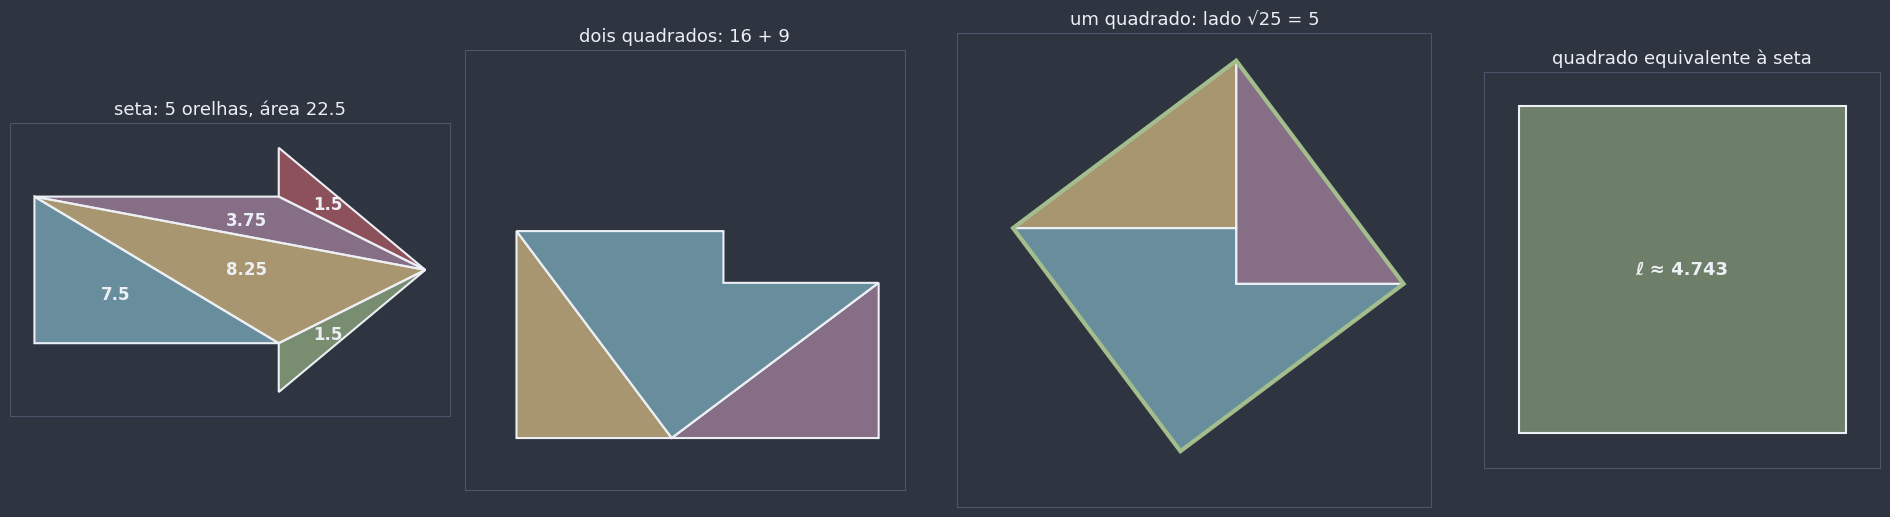

In [25]:
def somar_quadrados(x: float, y: float) -> dict:
    """Passo 4: os quadrados de lados x ≥ y, lado a lado, viram o quadrado de lado √(x² + y²). Devolve as três
    peças (a do meio fica parada; os dois triângulos giram 90°) e o quadrado de chegada."""
    x, y = max(x, y), min(x, y)
    T1 = [(0, 0), (y, 0), (0, x)]
    T2 = [(y, 0), (x + y, 0), (x + y, y)]
    meio = [(0, x), (y, 0), (x + y, y), (x, y), (x, x)]
    return {"pecas": [{"pontos": np.array(meio, dtype=float), "centro": (0, 0), "graus": 0},
                      {"pontos": np.array(T1, dtype=float), "centro": (0, x), "graus": 90},
                      {"pontos": np.array(T2, dtype=float), "centro": (x + y, y), "graus": -90}],
            "quadrado": np.array([(y, 0), (x + y, y), (x, x + y), (0, x)], dtype=float), "lado": math.hypot(x, y)}


def eh_orelha(P, i: int) -> bool:
    """O vértice i do polígono P (anti-horário) é uma "orelha": convexo e sem outro vértice dentro do triângulo."""
    n = len(P)
    A, B, C = P[i - 1], P[i], P[(i + 1) % n]
    if vetorial(B - A, C - B) <= 1e-12:
        return False
    for j in range(n):
        if j in (i - 1 if i > 0 else n - 1, i, (i + 1) % n):
            continue
        X = P[j]
        if all(vetorial(Q - Pp, X - Pp) >= -1e-12 for Pp, Q in ((A, B), (B, C), (C, A))):
            return False
    return True


def triangular_orelhas(pontos) -> list[np.ndarray]:
    """Triangulação de um polígono simples (convexo ou côncavo) cortando orelhas: n − 2 triângulos (0411a)."""
    P = list(anti_horario(pontos))
    triangulos = []
    while len(P) > 3:
        for i in range(len(P)):
            if eh_orelha(np.array(P), i):
                triangulos.append(np.array([P[i - 1], P[i], P[(i + 1) % len(P)]]))
                del P[i]
                break
        else:
            raise ValueError("não achei orelha: o polígono tem lados que se cruzam?")
    triangulos.append(np.array(P))
    return triangulos


def poligono_para_quadrado(pontos) -> tuple[list[np.ndarray], float, float]:
    """A receita de Wallace–Bolyai–Gerwien: triangula, transforma cada triângulo num quadrado de lado
    √(base·altura/2) e soma os quadrados por Pitágoras. Devolve (triângulos, área total, lado do quadrado)."""
    triangulos = triangular_orelhas(pontos)
    lado = 0.0
    for T in triangulos:
        lado_t = retangulo_para_quadrado_lado(math.dist(T[0], T[1]), distancia_ponto_reta(T[2], T[0], T[1]) / 2)
        lado = math.hypot(lado, lado_t)  # somar quadrados: passo 4
    return triangulos, lado**2, lado


SETA = [(0, 1), (5, 1), (5, 0), (8, 2.5), (5, 5), (5, 4), (0, 4)]
triangulos, area_seta, lado_seta = poligono_para_quadrado(SETA)
print(f"Seta: {len(triangulos)} triângulos (n − 2 = {len(SETA) - 2}); área pela receita = {area_seta:.4f}; "
      f"régua de área = {area_cadarco(SETA):.4f}; quadrado de lado {lado_seta:.4f}")
assert len(triangulos) == len(SETA) - 2 and iguais(area_seta, area_cadarco(SETA))

fig, (ax_s, ax_a, ax_d, ax_q) = plt.subplots(1, 4, figsize=(19, 5.2), gridspec_kw={"width_ratios": [1, 1, 1.25, 0.9]})
fig.patch.set_facecolor(NORD_FUNDO)
soma = somar_quadrados(4, 3)
for ax, t, titulo in ((ax_a, 0, "dois quadrados: 16 + 9"), (ax_d, 1, f"um quadrado: lado √25 = {soma['lado']:g}")):
    for k, p in enumerate(soma["pecas"]):
        desenhar_peca(ax, mover(p["pontos"], t, centro=p["centro"], graus=p["graus"]),
                      cor=(COR_FIGURA, COR_MOVEL, COR_EXTRA)[k], opacidade=0.65)
    if t == 1:
        desenhar_contorno(ax, soma["quadrado"], cor=COR_RESULTADO, largura=3, estilo="-", zorder=6)
    preparar_eixo(ax, [(-1, -1), (7.5, 7.5)], margem=0)
    ax.set_title(titulo, color=NORD_TEXTO, fontsize=13)
for k, T in enumerate(triangulos):
    desenhar_peca(ax_s, T, cor=CORES_PECAS[k], opacidade=0.65,
                  rotulo=f"{area_triangulo_pontos(*T):g}", tamanho=12)
preparar_eixo(ax_s, SETA, margem=0.5)
ax_s.set_title(f"seta: {len(triangulos)} orelhas, área {area_seta:g}", color=NORD_TEXTO, fontsize=13)
desenhar_peca(ax_q, [(0, 0), (lado_seta, 0), (lado_seta, lado_seta), (0, lado_seta)], cor=COR_RESULTADO,
              rotulo=f"ℓ ≈ {lado_seta:.3f}", tamanho=13)
preparar_eixo(ax_q, [(0, 0), (lado_seta, lado_seta)], margem=0.5)
ax_q.set_title("quadrado equivalente à seta", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

assert iguais(sum(area_cadarco(mover(p["pontos"], 1, centro=p["centro"], graus=p["graus"])) for p in soma["pecas"]), 25)

### O polígono regular é equivalente a um triângulo

📎 Promessa de [`0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb`](0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb): um polígono regular de $n$ lados, lado $\ell$ e apótema $a$ se decompõe em $n$ triângulos **congruentes** $OAB$, $OBC$, ..., todos de base $\ell$ e altura $a$. Coloque as $n$ bases **em fila** sobre uma reta: elas formam um segmento de comprimento $n \cdot \ell = 2p$ (o perímetro). Agora, **deslize** o vértice de cada triângulo ao longo da paralela à reta, à altura $a$, até um mesmo ponto: pelo corolário da seção 2, nenhuma área muda, e os $n$ triângulos viram **um só triângulo**, de base $2p$ e altura $a$. Então

$$S(\text{regular}) = \frac{2p \cdot a}{2} = p \cdot a,$$

a fórmula $S = p \cdot a$ de 0418a, agora vista como **equivalência**. Para o hexágono regular de lado 6: $2p = 36$, $a = 3\sqrt{3}$, $S = \frac{36 \cdot 3\sqrt{3}}{2} = 54\sqrt{3} \approx 93{,}53$, e o quadrado equivalente tem lado $\sqrt{54\sqrt{3}} \approx 9{,}67$.

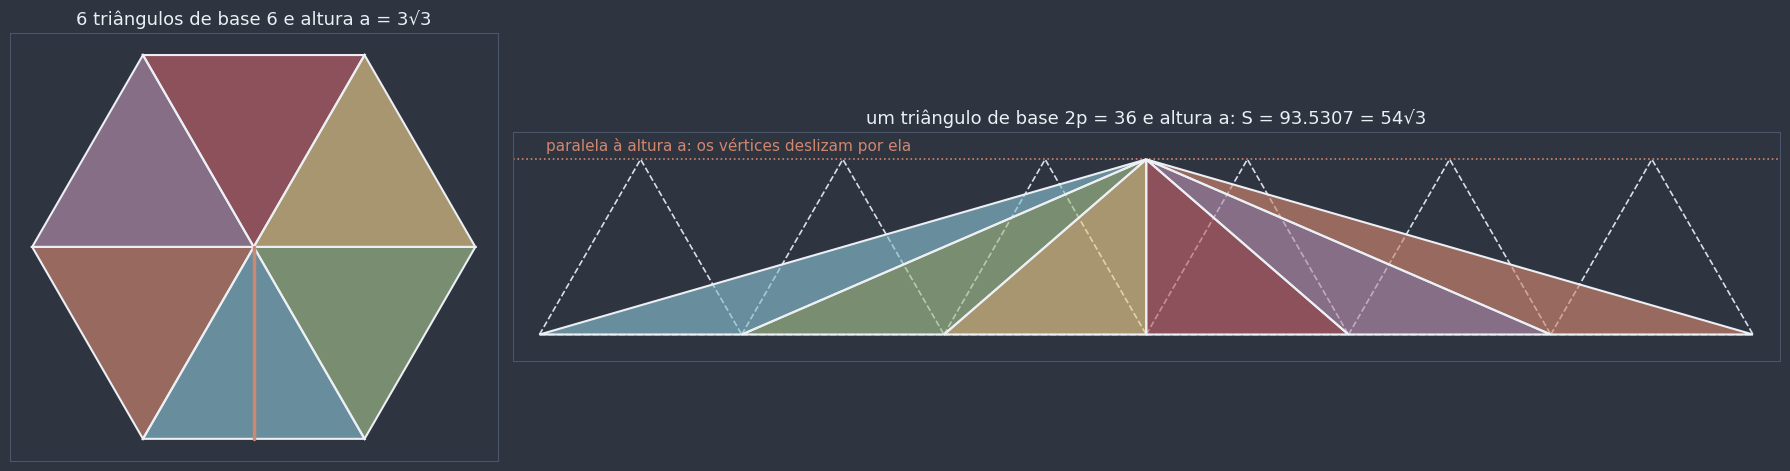

S = 54√3 ≈ 93.5307;  quadrado equivalente: lado √(54√3) ≈ 9.6711


In [26]:
lado_h = 6.0
apotema_h = lado_h * math.sqrt(3) / 2
hexagono = np.array([(lado_h * math.cos(math.radians(-120 + 60 * k)), lado_h * math.sin(math.radians(-120 + 60 * k)))
                     for k in range(6)])
O = np.array([0.0, 0.0])
fig, (ax_h, ax_t) = plt.subplots(1, 2, figsize=(18, 5.5), gridspec_kw={"width_ratios": [1, 2.6]})
fig.patch.set_facecolor(NORD_FUNDO)
for k in range(6):
    desenhar_peca(ax_h, [O, hexagono[k], hexagono[(k + 1) % 6]], cor=CORES_PECAS[k], opacidade=0.65)
desenhar_segmento(ax_h, O, ponto_medio(hexagono[0], hexagono[1]), cor=COR_ALTURA, largura=2.5)
preparar_eixo(ax_h, hexagono, margem=0.6)
ax_h.set_title("6 triângulos de base 6 e altura a = 3√3", color=NORD_TEXTO, fontsize=13)

topo = np.array([3 * lado_h, apotema_h])  # o ponto comum, em cima do meio da base de comprimento 2p
area_total = 0.0
for k in range(6):
    X, Y = np.array([k * lado_h, 0.0]), np.array([(k + 1) * lado_h, 0.0])
    desenhar_contorno(ax_t, [X, Y, ponto_medio(X, Y) + (0, apotema_h)], cor=NORD_TEXTO_SEC, largura=1.2)
    desenhar_peca(ax_t, [X, Y, topo], cor=CORES_PECAS[k], opacidade=0.65)
    area_total += area_triangulo_pontos(X, Y, topo)
ax_t.axhline(apotema_h, color=COR_ALTURA, lw=1.2, linestyle=":")
ax_t.text(0.2, apotema_h + 0.25, "paralela à altura a: os vértices deslizam por ela", color=COR_ALTURA, fontsize=11)
preparar_eixo(ax_t, [(0, 0), (6 * lado_h, apotema_h)], margem=0.8)
ax_t.set_title(f"um triângulo de base 2p = 36 e altura a: S = {area_total:.4f} = 54√3", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

assert iguais(area_total, area_cadarco(hexagono)) and iguais(area_total, 54 * math.sqrt(3))
print(f"S = 54√3 ≈ {54 * math.sqrt(3):.4f};  quadrado equivalente: lado √(54√3) ≈ {math.sqrt(54 * math.sqrt(3)):.4f}")

### Resposta ao gancho: 64 = 65?

Agora que sabemos o que garante a equivalência, voltemos ao quebra-cabeça. A aditividade (regra 3) exige que as peças cubram a figura **sem sobrar e sem sobrepor**. Será que, no "retângulo" $5 \times 13$, as peças se encaixam de verdade?

Olhe para a "diagonal" do retângulo. Ela é formada por dois tipos de segmento:
- a **hipotenusa do triângulo** (catetos 3 e 8): sobe 3 a cada 8, inclinação $\frac{3}{8} = 0{,}375$;
- o **lado oblíquo do trapézio** (que sobe 2 enquanto anda 5): inclinação $\frac{2}{5} = 0{,}4$.

Como $0{,}375 \neq 0{,}4$, esses segmentos **não estão na mesma reta**: a "diagonal" é, na verdade, uma linha quebrada, e entre as duas metades do retângulo sobra um **paralelogramo finíssimo**, de vértices $(0, 0)$, $(8, 3)$, $(13, 5)$ e $(5, 2)$. A área dele é exatamente

$$|8 \cdot 2 - 3 \cdot 5| = |16 - 15| = 1.$$

As contas batem: $65 = 64 + 1$. O quadradinho "a mais" é o **vão**, esticado ao longo da diagonal, tão fino (no ponto mais largo, menos de 0,08) que o olho não percebe.

💡 **Moral:** cortar e recolar só preserva a área quando as peças **encaixam de verdade**. Uma figura que "parece" um retângulo não é um retângulo.

🕵️ **Curiosidade:** os números do quebra-cabeça (3, 5, 8, 13) são termos consecutivos da sequência de **Fibonacci** (1, 1, 2, 3, 5, 8, 13, 21, ...), em que cada termo é a soma dos dois anteriores. É por isso que o truque funciona tão bem: as razões $\frac{3}{8}$ e $\frac{2}{5}$ entre termos de Fibonacci são muito próximas, e $8 \cdot 2 - 3 \cdot 5 = 1$ é um caso da **identidade de Cassini** (o Desafio 9 explora o padrão).

In [27]:
_, pecas_r = quebra_cabeca()
vao = [(0, 0), (8, 3), (13, 5), (5, 2)]
print(f"inclinação da hipotenusa do triângulo: 3/8 = {3 / 8};  do lado oblíquo do trapézio: 2/5 = {2 / 5}")
print(f"área do vão (régua de área): {area_cadarco(vao):g};  peças: {sum(area_cadarco(p) for p in pecas_r):g};  "
      f"peças + vão = {sum(area_cadarco(p) for p in pecas_r) + area_cadarco(vao):g} = 5 × 13")
largura_maxima = 8 * 5 / 13 - 3  # na abscissa 8, a diagonal verdadeira passa a 40/13, e a peça chega a 3
print(f"largura do vão (na vertical, na abscissa 8): 40/13 − 3 = {largura_maxima:.4f}")
assert iguais(area_cadarco(vao), 1) and iguais(sum(area_cadarco(p) for p in pecas_r) + area_cadarco(vao), 65)

inclinação da hipotenusa do triângulo: 3/8 = 0.375;  do lado oblíquo do trapézio: 2/5 = 0.4
área do vão (régua de área): 1;  peças: 64;  peças + vão = 65 = 5 × 13
largura do vão (na vertical, na abscissa 8): 40/13 − 3 = 0.0769


🕹️ **Widget interativo — onde está o quadradinho?** O botão alterna entre a **visão geral** do "retângulo" $5 \times 13$ e um **zoom no vão**, na região do meio da diagonal. No zoom, a escala é a mesma nas duas direções: o vão vermelho é real, não um exagero do desenho. A reta tracejada é a diagonal **verdadeira** do retângulo, que as peças não acompanham.

In [28]:
def explorar_vao(visao: str) -> None:
    fig, ax = plt.subplots(figsize=(15, 6.5))
    fig.patch.set_facecolor(NORD_FUNDO)
    for cor, pts in zip(CORES_PECAS, pecas_r):
        desenhar_peca(ax, pts, cor=cor, opacidade=0.75, largura=1 if visao == "visão geral" else 2)
    desenhar_peca(ax, vao, cor=COR_VAO, opacidade=0.9, borda=COR_VAO, largura=1, zorder=5)
    ax.plot([0, 13], [0, 5], color=NORD_TEXTO, lw=1, linestyle="--", zorder=7)
    if visao == "visão geral":
        preparar_eixo(ax, [(0, 0), (13, 5)], margem=0.4)
        ax.set_title("Visão geral: parece um retângulo 5 × 13", color=NORD_TEXTO, fontsize=13)
    else:
        preparar_eixo(ax, [(4.4, 1.75), (8.6, 3.25)], margem=0)
        for X in ((5, 2), (8, 3)):
            desenhar_ponto(ax, X, f"({X[0]}, {X[1]})", cor=NORD_TEXTO, deslocamento=(0.05, -0.12))
        ax.set_title("Zoom no vão: um paralelogramo fino de área 1", color=COR_VAO, fontsize=13)
    plt.tight_layout()
    plt.show()


widgets.interact(explorar_vao, visao=widgets.ToggleButtons(options=["visão geral", "zoom no vão"], value="zoom no vão",
                                                            description="visão:"));

interactive(children=(ToggleButtons(description='visão:', index=1, options=('visão geral', 'zoom no vão'), val…

⚠️ **Erro comum: achar que, se as peças "parecem" encaixar, elas encaixam.** Em geometria, **parecer** não é **demonstrar**. O que prova a equivalência é a **congruência** das peças e a garantia de que elas cobrem a figura sem buracos nem sobreposições, como fizemos em cada passo das seções 2, 4 e 5 (ângulos correspondentes, paralelas, pontos médios). No quebra-cabeça, faltou justamente verificar que os segmentos da diagonal estão alinhados.

🕵️ **Curiosidade histórica — a quadratura do círculo:** a receita de Wallace–Bolyai–Gerwien transforma **qualquer polígono** num quadrado. Os gregos tentaram fazer o mesmo com o **círculo**: construir, com **régua e compasso** e um número finito de passos, um quadrado de mesma área que um círculo dado. As lúnulas de Hipócrates (seção 4) davam esperança, porque mostravam regiões curvas com área igual à de polígonos. Ninguém conseguiu, por mais de 2 000 anos. Em **1882**, o matemático alemão **Ferdinand von Lindemann** demonstrou que $\pi$ é **transcendente** (não é raiz de nenhum polinômio de coeficientes inteiros, 0418a), e disso decorre que a construção é **impossível**. Desde então, "quadrar o círculo" virou sinônimo de tarefa impossível.

📎 Repare na diferença entre duas medidas que usam $\pi$: o **comprimento** da circunferência, $C = 2\pi r$ (um comprimento, [`0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb`](0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb)), e a **área** do círculo (uma superfície), que chega em 📌 Áreas de Superfícies Planas pelo mesmo argumento do polígono regular: o círculo é "equivalente" ao triângulo de base $C$ e altura $r$. É a distinção comprimento × área de [`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb).

🎯 **Aplicação prática — computação gráfica e mapas:** todo modelo 3D de um jogo ou de um filme de animação é uma **malha de triângulos**, e a triangulação de polígonos (como o corte de orelhas acima) é uma das primeiras etapas para desenhar qualquer figura na tela. Em mapas digitais (GPS, cadastro de terrenos), a área de uma região é calculada triangulando o contorno, ou pela própria fórmula do cadarço.

📖 **Leitura complementar:** [Teorema de Wallace–Bolyai–Gerwien](https://pt.wikipedia.org/wiki/Teorema_de_Wallace%E2%80%93Bolyai%E2%80%93Gerwien) e [Quadratura do círculo](https://pt.wikipedia.org/wiki/Quadratura_do_c%C3%ADrculo)

**Pergunta de checagem:** um triângulo de base 12 e altura 6 vira um retângulo de que dimensões, cortando na metade da altura? E o quadrado equivalente tem lado quanto?

**Pergunta de checagem:** por que o "retângulo" $5 \times 13$ do gancho não prova que $64 = 65$?

## Resumo — cheat sheet

**Notação fixa:** $S(F)$ área de $F$; $b$ base, $h$ altura; $B$ e $b$ bases do trapézio; $d_1$, $d_2$ diagonais; $k$ razão de semelhança; no triângulo retângulo, $a$ hipotenusa, $b$ e $c$ catetos, $m$ e $n$ projeções.

| Conceito | Ideia-chave |
|---|---|
| **Três regras da área** | quadrado unitário vale 1; congruentes têm a mesma área; aditividade (partes sem sobreposição somam) |
| **Hierarquia** | congruentes ⇒ equivalentes (mesma área); a recíproca é falsa; semelhantes têm áreas na razão $k^2$ |
| **Ideia central** | cortar e recolar (sem sobrar nem sobrepor) não muda a área |
| **Retângulo e quadrado** | $b \cdot h$ (contagem, frações, aproximação); $\ell^2$ |
| **Quadratura do retângulo** | quadrado equivalente de lado $\sqrt{b \cdot h}$ (média geométrica) |
| **Paralelogramo** | $b \cdot h$: corta um triângulo e desliza; não depende da inclinação |
| **Triângulo** | $\frac{b \cdot h}{2}$: duas cópias formam um paralelogramo; mesma base e mesma altura ⇒ equivalentes |
| **Trapézio** | $\frac{(B + b) \cdot h}{2}$ = base média × altura |
| **Losango** | $\frac{d_1 \cdot d_2}{2}$ (todo quadrilátero convexo de diagonais perpendiculares) |
| **Mesma altura** | $\frac{S_1}{S_2} = \frac{b_1}{b_2}$; mediana ⇒ duas metades; três medianas ⇒ seis partes de $\frac{S}{6}$; $AG : GM = 2 : 1$ |
| **Bissetriz por áreas** | $\frac{BD}{DC} = \frac{c}{b}$ |
| **Paralelogramo e trapézio** | $S(PAB) + S(PCD) = \frac{S}{2}$; no trapézio, $S(ADP) = S(BCP)$ |
| **Viviani** | equilátero: $d_1 + d_2 + d_3 = h$ para todo ponto interior |
| **Euclides** | quadrado do cateto = retângulo na hipotenusa: $c^2 = a \cdot m$, $b^2 = a \cdot n$ ⇒ $a^2 = b^2 + c^2$ |
| **Trapézio de Garfield** | $\frac{(b + c)^2}{2} = bc + \frac{a^2}{2}$ |
| **Razão de áreas** | $\frac{S'}{S} = k^2$ (comprimentos: $k$; volumes: $k^3$); folhas A: lados na razão $\sqrt{2}$ |
| **Pitágoras generalizado** | figuras semelhantes nos lados: $F_a = F_b + F_c$; lúnulas de Hipócrates = triângulo |
| **Polígono → quadrado** | triangular → retângulos (metade da altura) → quadrados $\sqrt{b \cdot h}$ → somar quadrados por Pitágoras |
| **Regular** | equivalente ao triângulo de base $2p$ e altura $a$: $S = p \cdot a$ |
| **Cuidado** | $64 \neq 65$: as peças precisam encaixar de verdade; quadrar o círculo com régua e compasso é impossível |

**O fio condutor:** quadrado unitário → retângulo → paralelogramo → triângulo → trapézio e losango → Pitágoras → qualquer polígono. Uma única ideia sustenta tudo: **cortar, deslizar e recolar**.

As figuras abaixo repetem a cadeia, com as cores do notebook.

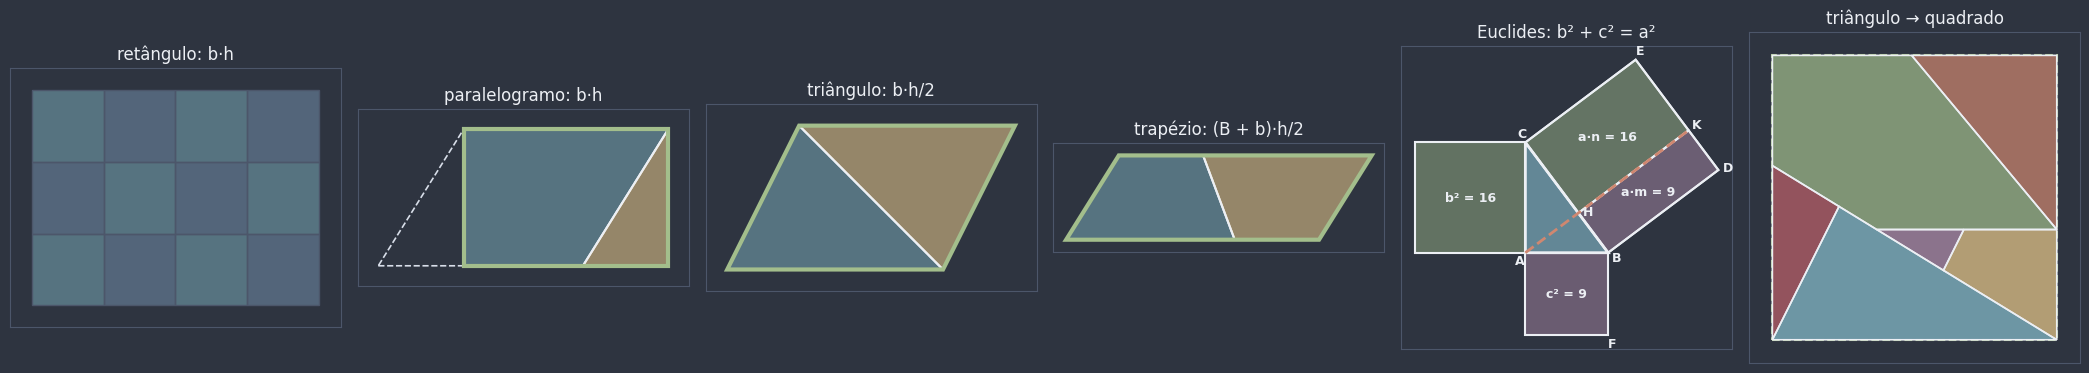

In [29]:
# Esta célula usa as ferramentas construídas ao longo do notebook (contagem, corte e cola, Euclides e dissecação)
fig, eixos = plt.subplots(1, 6, figsize=(21, 4.6))
fig.patch.set_facecolor(NORD_FUNDO)
area_por_contagem(4, 3, eixos[0])
preparar_eixo(eixos[0], [(0, 0), (4, 3)], margem=0.3)
eixos[0].set_title("retângulo: b·h", color=NORD_TEXTO, fontsize=12)
for ax, figura, titulo in ((eixos[1], "paralelogramo", "paralelogramo: b·h"), (eixos[2], "triângulo", "triângulo: b·h/2"),
                           (eixos[3], "trapézio", "trapézio: (B + b)·h/2")):
    desenhar_corte_e_cola(ax, figura, 1.0)
    ax.set_title(titulo, color=NORD_TEXTO, fontsize=12)
desenhar_euclides(eixos[4], figura_euclides(4, 3), 4, tamanho=9)
eixos[4].set_title("Euclides: b² + c² = a²", color=NORD_TEXTO, fontsize=12)
pecas_resumo = dissecar_triangulo((0, 0), (8, 0), (3, 6))
desenhar_dissecacao(eixos[5], pecas_resumo, 2.0)
preparar_eixo(eixos[5], [(0, 0), (pecas_resumo[0]["lado"],) * 2], margem=0.4)
eixos[5].set_title("triângulo → quadrado", color=NORD_TEXTO, fontsize=12)
plt.tight_layout()
plt.show()

## Exercícios

**Básico**
1. Áreas por transformação: paralelogramo, triângulo, trapézio e losango.
2. O lado do quadrado equivalente.
3. Razões de áreas: mesma altura, baricentro e $k^2$.

**Intermediário**

4. As suas próprias funções: régua de área, fórmulas, quadrado equivalente e o triângulo que vira retângulo.
5. Verificações numéricas: medianas, Viviani, Pitágoras generalizado e o ponto no paralelogramo.
6. Problemas de dois ou três passos: o trapézio isósceles, a distância a um lado e o triângulo dos pontos que dividem os lados.

**Desafio**

7. Qualquer polígono → quadrado (triangulação por orelhas).
8. As lúnulas de Hipócrates, numericamente.
9. Fibonacci e as peças que não encaixam.

Gabarito completo com resolução comentada em [`0419b_equivalencia_plana_gabarito.ipynb`](0419b_equivalencia_plana_gabarito.ipynb).

### Básico

In [ ]:
# Exercício Básico 1: áreas por transformação (use as fórmulas da seção 2; cuidado com o lado inclinado!).
# (a) Um paralelogramo tem base 8, lado inclinado 5 e altura 4. Guarde a área em `area_ex1a`.
# (b) Um triângulo tem base 14 e altura 12. Guarde a área em `area_ex1b`.
# (c) Um trapézio tem bases 12 e 7 e altura 6. Guarde a área em `area_ex1c`.
# (d) Um losango tem diagonais 16 e 30. Guarde a área em `area_ex1d`, o lado em `lado_ex1d` e a altura relativa
#     ao lado (a distância entre dois lados opostos) em `altura_ex1d`.
area_ex1a = ...
area_ex1b = ...
area_ex1c = ...
area_ex1d = ...
lado_ex1d = ...
altura_ex1d = ...

print(area_ex1a, area_ex1b, area_ex1c, area_ex1d, lado_ex1d, altura_ex1d)

In [ ]:
# Verificação
assert area_ex1a is not ... and math.isclose(area_ex1a, 32), (
    "Tente de novo, revise: a área do paralelogramo é base × ALTURA, não base × lado (seção 2 - Transformando figuras)."
)
assert area_ex1b is not ... and math.isclose(area_ex1b, 84), (
    "Tente de novo, revise: o triângulo é metade do paralelogramo, S = b·h/2 (seção 2 - Transformando figuras)."
)
assert area_ex1c is not ... and math.isclose(area_ex1c, 57), (
    "Tente de novo, revise: S = (B + b)·h/2, a base média vezes a altura (seção 2 - Transformando figuras)."
)
assert area_ex1d is not ... and math.isclose(area_ex1d, 240), (
    "Tente de novo, revise: o losango é metade do retângulo d₁ × d₂ (seção 2 - Transformando figuras)."
)
assert lado_ex1d is not ... and math.isclose(lado_ex1d, 17), (
    "Tente de novo, revise: as semidiagonais 8 e 15 são catetos, e o lado é a hipotenusa (seção 2 - Transformando figuras)."
)
assert altura_ex1d is not ... and math.isclose(altura_ex1d, 240 / 17), (
    "Tente de novo, revise: o losango é um paralelogramo: área = lado × altura, então altura = área/lado "
    "(seção 2 - Transformando figuras)."
)
print("Certo!")

In [ ]:
# Exercício Básico 2: o lado do quadrado equivalente (use math.sqrt).
# (a) Retângulo 18 × 8: guarde o lado do quadrado equivalente em `lado_ex2a`.
# (b) Triângulo de base 12 e altura 6: guarde em `lado_ex2b`.
# (c) Trapézio de bases 10 e 6 e altura 4: guarde em `lado_ex2c`.
# (d) Um quadrado tem a mesma área que um losango de diagonais 4 e 8. Guarde o lado do quadrado em `lado_ex2d`.
lado_ex2a = ...
lado_ex2b = ...
lado_ex2c = ...
lado_ex2d = ...

print(lado_ex2a, lado_ex2b, lado_ex2c, lado_ex2d)

In [ ]:
# Verificação
assert lado_ex2a is not ... and math.isclose(lado_ex2a, 12), (
    "Tente de novo, revise: ℓ² = b·h, então ℓ = √(b·h), a média geométrica (seção 1 - O que é área?)."
)
assert lado_ex2b is not ... and math.isclose(lado_ex2b, 6), (
    "Tente de novo, revise: primeiro a área do triângulo (b·h/2 = 36), depois a raiz (seção 1 - O que é área?)."
)
assert lado_ex2c is not ... and math.isclose(lado_ex2c, math.sqrt(32)), (
    "Tente de novo, revise: a área do trapézio é (10 + 6)·4/2 = 32, e o lado é √32 (seção 2 - Transformando figuras)."
)
assert lado_ex2d is not ... and math.isclose(lado_ex2d, 4), (
    "Tente de novo, revise: a área do losango é d₁·d₂/2 = 16 (seção 2 - Transformando figuras)."
)
print("Certo!")

In [ ]:
# Exercício Básico 3: razões de áreas.
# (a) No triângulo ABC de área 60, o ponto D está no lado BC com BD : DC = 1 : 3. Guarde as áreas de ABD e ADC
#     em `S_ABD_ex3` e `S_ADC_ex3`.
# (b) No mesmo triângulo, G é o baricentro. Guarde a área de GBC em `S_GBC_ex3`.
# (c) Uma pizza de 30 cm de diâmetro custa R$ 36,00. Guarde em `preco_ex3` o preço justo de uma pizza de 20 cm,
#     se o preço for proporcional à área.
# (d) O lado de um quadrado aumenta 50%. Guarde em `aumento_ex3` o aumento percentual da área (ex.: 30 para 30%).
# (e) Numa maquete na escala 1 : 50, um terreno real de 300 m² ocupa quantos cm²? Guarde em `maquete_ex3`.
S_ABD_ex3 = ...
S_ADC_ex3 = ...
S_GBC_ex3 = ...
preco_ex3 = ...
aumento_ex3 = ...
maquete_ex3 = ...

print(S_ABD_ex3, S_ADC_ex3, S_GBC_ex3, preco_ex3, aumento_ex3, maquete_ex3)

In [ ]:
# Verificação
assert S_ABD_ex3 is not ... and S_ADC_ex3 is not ... and math.isclose(S_ABD_ex3, 15) and math.isclose(S_ADC_ex3, 45), (
    "Tente de novo, revise: mesma altura ⇒ áreas na razão das bases, 1 : 3, somando 60 "
    "(seção 3 - Triângulos de mesma altura)."
)
assert S_GBC_ex3 is not ... and math.isclose(S_GBC_ex3, 20), (
    "Tente de novo, revise: GBC é formado por 2 dos 6 pedaços de S/6 (seção 3 - Triângulos de mesma altura)."
)
assert preco_ex3 is not ... and math.isclose(preco_ex3, 16), (
    "Tente de novo, revise: k = 20/30 = 2/3 e as áreas seguem k² = 4/9 (seção 4 - Pitágoras por áreas e a razão k²)."
)
assert aumento_ex3 is not ... and math.isclose(aumento_ex3, 125), (
    "Tente de novo, revise: k = 1,5 ⇒ k² = 2,25, isto é, 225% da área original (seção 4 - Pitágoras por áreas e a razão k²)."
)
assert maquete_ex3 is not ... and math.isclose(maquete_ex3, 1200), (
    "Tente de novo, revise: as áreas ficam divididas por 50² = 2500; e 1 m² = 10 000 cm² "
    "(seção 4 - Pitágoras por áreas e a razão k²)."
)
print("Certo!")

### Intermediário

In [ ]:
# Exercício Intermediário 4: as suas próprias funções.
# Complete as funções abaixo SEM usar as do notebook (area_cadarco, area_paralelogramo, ..., triangulo_para_retangulo).
# Pode usar math, numpy e as funções ponto_medio, pe_da_altura, distancia_ponto_reta e girar.
# (a) area_cadarco_ex4(pontos): a fórmula do cadarço (a área é sempre positiva, em qualquer sentido).
# (b) area_paralelogramo_ex4(b, h), area_triangulo_ex4(b, h), area_trapezio_ex4(B, b, h), area_losango_ex4(d1, d2).
# (c) quadrado_equivalente_ex4(b, h): o lado do quadrado equivalente ao retângulo b × h.
# (d) triangulo_para_retangulo_ex4(A, B, C): para um triângulo com A = (0, 0), B = (b, 0) e C = (x, h), com
#     0 ≤ x ≤ b e h > 0, devolva a LISTA das três peças (cada uma, um array de vértices) JÁ NA POSIÇÃO FINAL, formando
#     o retângulo [0, b] × [0, h/2]: o trapézio de baixo (parado) e os dois triangulinhos de cima, girados 180° em
#     torno dos pontos médios de AC e de BC.
def area_cadarco_ex4(pontos) -> float:
    return ...


def area_paralelogramo_ex4(b: float, h: float) -> float:
    return ...


def area_triangulo_ex4(b: float, h: float) -> float:
    return ...


def area_trapezio_ex4(B: float, b: float, h: float) -> float:
    return ...


def area_losango_ex4(d1: float, d2: float) -> float:
    return ...


def quadrado_equivalente_ex4(b: float, h: float) -> float:
    return ...


def triangulo_para_retangulo_ex4(A, B, C) -> list[np.ndarray]:
    return ...


print(area_cadarco_ex4([(0, 0), (4, 0), (4, 3), (0, 3)]), quadrado_equivalente_ex4(12, 3))

In [ ]:
# Verificação (contra a régua de área do notebook, em figuras sorteadas)
random.seed(40)
for _ in range(200):
    # pentágono simples (talvez côncavo): vértices em ângulos crescentes em volta da origem, raios sorteados
    pts_v = [tuple(random.uniform(1, 9) * direcao(72 * k_v + random.uniform(-20, 20))) for k_v in range(5)]
    assert area_cadarco_ex4(pts_v) is not ... and iguais(area_cadarco_ex4(pts_v), area_cadarco(pts_v)), (
        "Tente de novo, revise: some xᵢ·yᵢ₊₁ − xᵢ₊₁·yᵢ (o último com o primeiro), tome o módulo e divida por 2 "
        "(seção 1 - O que é área?)."
    )
    assert iguais(area_cadarco_ex4(pts_v[::-1]), area_cadarco(pts_v)), (
        "Tente de novo, revise: no sentido horário a soma dá negativa; use abs (seção 1 - O que é área?)."
    )
    b_v, h_v, s_v = random.uniform(0.5, 9), random.uniform(0.5, 9), random.uniform(-9, 9)
    assert area_paralelogramo_ex4(b_v, h_v) is not ... and iguais(area_paralelogramo_ex4(b_v, h_v),
                                                                   area_cadarco([(0, 0), (b_v, 0), (b_v + s_v, h_v), (s_v, h_v)])), (
        "Tente de novo, revise: paralelogramo = b·h (seção 2 - Transformando figuras)."
    )
    assert area_triangulo_ex4(b_v, h_v) is not ... and iguais(area_triangulo_ex4(b_v, h_v),
                                                               area_cadarco([(0, 0), (b_v, 0), (s_v, h_v)])), (
        "Tente de novo, revise: triângulo = b·h/2 (seção 2 - Transformando figuras)."
    )
    B_v = b_v + random.uniform(0.1, 5)
    assert area_trapezio_ex4(B_v, b_v, h_v) is not ... and iguais(
        area_trapezio_ex4(B_v, b_v, h_v), area_cadarco([(0, 0), (B_v, 0), (s_v + b_v, h_v), (s_v, h_v)])), (
        "Tente de novo, revise: trapézio = (B + b)·h/2 (seção 2 - Transformando figuras)."
    )
    assert area_losango_ex4(b_v, h_v) is not ... and iguais(
        area_losango_ex4(b_v, h_v), area_cadarco([(b_v / 2, 0), (0, h_v / 2), (-b_v / 2, 0), (0, -h_v / 2)])), (
        "Tente de novo, revise: losango = d₁·d₂/2 (seção 2 - Transformando figuras)."
    )
    assert quadrado_equivalente_ex4(b_v, h_v) is not ... and iguais(quadrado_equivalente_ex4(b_v, h_v) ** 2, b_v * h_v), (
        "Tente de novo, revise: ℓ = √(b·h) (seção 1 - O que é área?)."
    )
    x_v = random.uniform(0, b_v)
    pecas_v = triangulo_para_retangulo_ex4((0, 0), (b_v, 0), (x_v, h_v))
    assert pecas_v is not ... and len(pecas_v) == 3, (
        "Tente de novo, revise: são três peças, o trapézio e os dois triangulinhos (seção 5 - Cortar e recolar)."
    )
    todos_v = np.vstack([np.asarray(p, dtype=float) for p in pecas_v])
    assert todos_v[:, 0].min() > -1e-9 and todos_v[:, 0].max() < b_v + 1e-9 and todos_v[:, 1].min() > -1e-9 and \
        todos_v[:, 1].max() < h_v / 2 + 1e-9, (
        "Tente de novo, revise: na posição final, todas as peças ficam dentro do retângulo [0, b] × [0, h/2]; gire os "
        "triangulinhos 180° em torno dos pontos médios de AC e BC (seção 5 - Cortar e recolar)."
    )
    assert iguais(sum(area_cadarco(p) for p in pecas_v), b_v * h_v / 2), (
        "Tente de novo, revise: as peças devem somar a área do triângulo (seção 5 - Cortar e recolar)."
    )
print("Certo!")

In [ ]:
# Exercício Intermediário 5: verificações numéricas (cada resposta é True ou False).
# Use random.seed(5) no começo, area_triangulo_pontos (base × altura / 2) e iguais para comparar.
# (a) `medianas_ok_ex5`: em 100 triângulos sorteados, os seis pedaços formados pelas três medianas valem todos S/6?
# (b) `viviani_ok_ex5`: em 200 pontos sorteados DENTRO do triângulo equilátero de lado 10, a soma das distâncias aos
#     três lados é sempre 5√3?
# (c) `pitagoras_ok_ex5`: para os triângulos retângulos de catetos (3, 4), (5, 12), (1, 2) e (2.5, 6), e para os
#     moldes "quadrado", "triângulo equilátero" e "semicírculo" de MOLDES, vale F_a = F_b + F_c?
#     (Use figura_sobre_lado e area_cadarco, da seção 4.)
# (d) `paralelogramo_ok_ex5`: no paralelogramo A = (0, 0), B = (9, 0), C = (12, 5), D = (3, 5), para 200 pontos P
#     sorteados no interior, vale S(PAB) + S(PCD) = S(ABCD)/2?
medianas_ok_ex5 = ...
viviani_ok_ex5 = ...
pitagoras_ok_ex5 = ...
paralelogramo_ok_ex5 = ...

print(medianas_ok_ex5, viviani_ok_ex5, pitagoras_ok_ex5, paralelogramo_ok_ex5)

In [ ]:
# Verificação
assert medianas_ok_ex5 is not ... and medianas_ok_ex5 is True, (
    "Tente de novo, revise: os seis pedaços são (A, Mc, G), (Mc, B, G), (B, Ma, G), (Ma, C, G), (C, Mb, G), (Mb, A, G) "
    "(seção 3 - Triângulos de mesma altura)."
)
assert viviani_ok_ex5 is not ... and viviani_ok_ex5 is True, (
    "Tente de novo, revise: sorteie P = A + r₁(B − A) + r₂(C − A) com r₁ + r₂ ≤ 1 e use distancia_ponto_reta "
    "(seção 3 - Triângulos de mesma altura)."
)
assert pitagoras_ok_ex5 is not ... and pitagoras_ok_ex5 is True, (
    "Tente de novo, revise: com A = (0, 0), B = (c, 0), C = (0, b), os lados são AB, BC e CA, nessa ordem "
    "(seção 4 - Pitágoras por áreas e a razão k²)."
)
assert paralelogramo_ok_ex5 is not ... and paralelogramo_ok_ex5 is True, (
    "Tente de novo, revise: P = A + u(B − A) + v(D − A), com u e v entre 0 e 1; a metade de 45 é 22,5 "
    "(seção 3 - Triângulos de mesma altura)."
)
print("Certo!")

In [ ]:
# Exercício Intermediário 6: problemas de dois ou três passos.
# (a) Um trapézio isósceles tem bases 14 e 6 e lados não paralelos 5. Guarde a altura em `altura_ex6a` e a área
#     em `area_ex6a`.
# (b) O triângulo de lados 13, 14 e 15 tem área 84 (0417a). Guarde em `distancia_ex6b` a distância do vértice oposto
#     ao lado de medida 13 até esse lado.
# (c) No triângulo ABC, os pontos D, E e F dividem os lados AB, BC e CA (nesse sentido) na razão 1 : 2, isto é,
#     AD = AB/3, BE = BC/3 e CF = CA/3. Guarde em `canto_ex6c` a fração da área de ABC ocupada pelo triângulo ADF
#     (o "canto" em A) e em `razao_ex6c` a fração ocupada pelo triângulo DEF.
#     (Dica: use duas vezes "mesma altura ⇒ razão das bases".)
altura_ex6a = ...
area_ex6a = ...
distancia_ex6b = ...
canto_ex6c = ...
razao_ex6c = ...

print(altura_ex6a, area_ex6a, distancia_ex6b, canto_ex6c, razao_ex6c)

In [ ]:
# Verificação
assert altura_ex6a is not ... and math.isclose(altura_ex6a, 3), (
    "Tente de novo, revise: cada \"aba\" do trapézio tem base (14 − 6)/2 = 4 e hipotenusa 5 (seção 2 - Transformando figuras)."
)
assert area_ex6a is not ... and math.isclose(area_ex6a, 30), (
    "Tente de novo, revise: S = (B + b)·h/2 (seção 2 - Transformando figuras)."
)
assert distancia_ex6b is not ... and math.isclose(distancia_ex6b, 168 / 13), (
    "Tente de novo, revise: 84 = 13·d/2, isole d (seção 2 - Transformando figuras)."
)
assert canto_ex6c is not ... and math.isclose(canto_ex6c, 2 / 9), (
    "Tente de novo, revise: S(ADF)/S(ABF) = AD/AB = 1/3 e S(ABF)/S(ABC) = AF/AC = 2/3 "
    "(seção 3 - Triângulos de mesma altura)."
)
assert razao_ex6c is not ... and math.isclose(razao_ex6c, 1 / 3), (
    "Tente de novo, revise: retire os três cantos de 2/9 cada (seção 3 - Triângulos de mesma altura)."
)
print("Certo!")

### Desafio

In [ ]:
# Exercício Desafio 7: qualquer polígono → quadrado.
# Complete poligono_para_quadrado_ex7(pontos), que recebe os vértices de um polígono simples (convexo OU côncavo,
# em qualquer sentido) e devolve a tupla (triangulos, area, lado):
#   - triangulos: a lista dos n − 2 triângulos de uma triangulação por "orelhas" (cada um, um array 3 × 2);
#   - area: a soma das áreas dos triângulos, cada uma por base × altura / 2;
#   - lado: o lado do quadrado equivalente, obtido somando os quadrados um a um por Pitágoras.
# Não use triangular_orelhas nem poligono_para_quadrado do notebook (pode usar anti_horario e vetorial).
# Uma orelha é um vértice convexo cujo triângulo (anterior, ele, próximo) não contém nenhum outro vértice.
def poligono_para_quadrado_ex7(pontos) -> tuple[list[np.ndarray], float, float]:
    return ...


print(poligono_para_quadrado_ex7(SETA)[1:])

In [ ]:
# Verificação (polígonos convexos e côncavos sorteados, nos dois sentidos)
random.seed(70)
for _ in range(150):
    n_v = random.randint(3, 12)
    angulos_v = [360 * k_v / n_v + random.uniform(-0.4, 0.4) * 360 / n_v for k_v in range(n_v)]
    convexo_v = random.random() < 0.3  # raio fixo: convexo; raios sorteados: em geral côncavo
    pol_v = [(5.0 if convexo_v else random.uniform(1, 8)) * direcao(a_v) for a_v in angulos_v]
    if random.random() < 0.5:
        pol_v = pol_v[::-1]
    resultado_v = poligono_para_quadrado_ex7(pol_v)
    assert resultado_v is not ... and len(resultado_v) == 3, (
        "Tente de novo, revise: devolva a tupla (triangulos, area, lado) (seção 5 - Cortar e recolar)."
    )
    tris_v, area_v, lado_v = resultado_v
    assert len(tris_v) == n_v - 2, (
        "Tente de novo, revise: um polígono de n lados vira n − 2 triângulos (seção 5 - Cortar e recolar)."
    )
    assert iguais(area_v, area_cadarco(pol_v)) and iguais(sum(area_cadarco(T) for T in tris_v), area_cadarco(pol_v)), (
        "Tente de novo, revise: as orelhas precisam estar DENTRO do polígono (vértice convexo e nenhum outro vértice "
        "no triângulo); comece colocando os vértices no sentido anti-horário (seção 5 - Cortar e recolar)."
    )
    assert iguais(lado_v**2, area_cadarco(pol_v)), (
        "Tente de novo, revise: lado_novo = √(lado² + lado_do_triângulo²) (seção 5 - Cortar e recolar)."
    )
print("Certo!")

In [ ]:
# Exercício Desafio 8: as lúnulas de Hipócrates, numericamente (sem a fórmula da área do círculo!).
# Para o triângulo retângulo A = (0, 0), B = (c, 0), C = (0, b):
# (a) Complete lunulas_ex8(b, c), que devolve a tupla (area_das_lunulas, area_do_triangulo). Construa os semicírculos
#     com figura_sobre_lado(P, Q, MOLDES["semicírculo"]) (os dos catetos para fora) e meça com area_cadarco;
#     as lúnulas valem F_b + F_c − (F_a − S_triângulo), porque o semicírculo da hipotenusa (virado para dentro)
#     contém o triângulo.
# (b) Guarde em `lunulas_ok_ex8` o valor True se as lúnulas igualarem o triângulo (use iguais) para os catetos
#     (3, 4), (1, 1), (5, 12), (2, 7) e (0.5, 3).
# (c) Guarde em `razao_ex8` a razão F_a / a² para o triângulo 3–4–5: é a área do semicírculo de diâmetro 1.
#     Compare (de olho) com math.pi / 8: é a fórmula que chega em Áreas de Superfícies Planas.
def lunulas_ex8(b: float, c: float) -> tuple[float, float]:
    return ...


lunulas_ok_ex8 = ...
razao_ex8 = ...

print(lunulas_ex8(3, 4), lunulas_ok_ex8, razao_ex8, math.pi / 8)

In [ ]:
# Verificação
for b_v, c_v in ((3, 4), (1, 1), (5, 12), (2, 7), (0.5, 3), (6, 2.5)):
    resultado_v = lunulas_ex8(b_v, c_v)
    assert resultado_v is not ... and iguais(resultado_v[1], b_v * c_v / 2), (
        "Tente de novo, revise: a área do triângulo retângulo é b·c/2 (seção 2 - Transformando figuras)."
    )
    assert iguais(resultado_v[0], b_v * c_v / 2), (
        "Tente de novo, revise: lúnulas = F_b + F_c − (F_a − S), com F_a = F_b + F_c (seção 4 - Pitágoras por áreas e a razão k²)."
    )
assert lunulas_ok_ex8 is not ... and lunulas_ok_ex8 is True, (
    "Tente de novo, revise: compare as duas áreas devolvidas por lunulas_ex8 com iguais (seção 4 - Pitágoras por áreas e a razão k²)."
)
assert razao_ex8 is not ... and math.isclose(razao_ex8, math.pi / 8, rel_tol=1e-5), (
    "Tente de novo, revise: F_a é a área do semicírculo sobre a hipotenusa 5, então divida por 25 "
    "(seção 4 - Pitágoras por áreas e a razão k²)."
)
print("Certo!")

In [ ]:
# Exercício Desafio 9: Fibonacci e as peças que não encaixam.
# A função quebra_cabeca(x, y) do gancho corta o quadrado de lado x + y e remonta as peças num "retângulo"
# y × (x + 2y). Use os pares de Fibonacci (x, y) = (2, 3), (3, 5) e (5, 8) (quadrados de lado 5, 8 e 13).
# (a) Guarde em `diferenca_ex9` o dicionário {lado do quadrado: área do "retângulo" − área do quadrado}.
# (b) Guarde em `inclinacoes_ex9` o dicionário {lado do quadrado: (x/(x + y), (y − x)/y)}: as inclinações da
#     hipotenusa do triângulo e do lado oblíquo do trapézio, na "diagonal" do retângulo.
# (c) Guarde em `vao_ex9` o dicionário {lado do quadrado: área do paralelogramo de vértices (0, 0), (x + y, x),
#     (x + 2y, y), (y, y − x)} (use area_cadarco).
# (d) Guarde em `tipo_ex9` o dicionário {lado do quadrado: "vão" ou "sobreposição"}: "vão" se o retângulo tiver
#     área MAIOR que o quadrado (sobra um buraco), "sobreposição" se tiver área MENOR (as peças se encavalam).
diferenca_ex9 = ...
inclinacoes_ex9 = ...
vao_ex9 = ...
tipo_ex9 = ...

print(diferenca_ex9, inclinacoes_ex9, vao_ex9, tipo_ex9, sep="\n")

In [ ]:
# Verificação
assert diferenca_ex9 is not ... and diferenca_ex9 == {5: -1, 8: 1, 13: -1}, (
    "Tente de novo, revise: o \"retângulo\" mede y × (x + 2y) e o quadrado (x + y)² (seção 5 - Cortar e recolar)."
)
assert inclinacoes_ex9 is not ... and all(
    np.allclose(inclinacoes_ex9[L_v], esperado_v)
    for L_v, esperado_v in ((5, (2 / 5, 1 / 3)), (8, (3 / 8, 2 / 5)), (13, (5 / 13, 3 / 8)))), (
    "Tente de novo, revise: a hipotenusa sobe x enquanto anda x + y; o lado oblíquo sobe y − x enquanto anda y "
    "(seção 5 - Cortar e recolar)."
)
assert vao_ex9 is not ... and all(math.isclose(vao_ex9[L_v], 1) for L_v in (5, 8, 13)), (
    "Tente de novo, revise: o paralelogramo tem área |(x + y)(y − x) − x·y|, sempre 1 para Fibonacci "
    "(seção 5 - Cortar e recolar)."
)
assert tipo_ex9 is not ... and tipo_ex9 == {5: "sobreposição", 8: "vão", 13: "sobreposição"}, (
    "Tente de novo, revise: compare o sinal da diferença do item (a) (seção 5 - Cortar e recolar)."
)
print("Certo!")

## Conexões

**Isso depende de:**
- [`0401a_nocoes_e_proposicoes_primitivas.ipynb`](0401a_nocoes_e_proposicoes_primitivas.ipynb) (o papel dos postulados: as três regras da área são escolhidas, não demonstradas)
- [`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb) (congruência das peças em cada corte e cola; LAL na demonstração de Euclides; LLL no triângulo medial)
- [`0406a_paralelismo.ipynb`](0406a_paralelismo.ipynb) (ângulos correspondentes no encaixe do paralelogramo; paralelas por onde os vértices deslizam)
- [`0407a_perpendicularidade.ipynb`](0407a_perpendicularidade.ipynb) (altura como distância de ponto a reta; distância constante entre paralelas)
- [`0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb`](0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb) (base média do triângulo e do trapézio, agora em problemas de área)
- [`0409a_paralelogramos_e_casos_particulares.ipynb`](0409a_paralelogramos_e_casos_particulares.ipynb) (propriedades do paralelogramo, do retângulo e do losango; aqui vieram as suas **áreas**)
- [`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb) (medianas, baricentro e bissetriz, agora com as demonstrações por áreas da razão $2 : 1$ e do teorema da bissetriz)
- [`0411a_poligonos.ipynb`](0411a_poligonos.ipynb) (triangulação em $n - 2$ triângulos, base da razão $k^2$ e da receita de Wallace–Bolyai–Gerwien)
- [`0414a_teorema_de_tales.ipynb`](0414a_teorema_de_tales.ipynb) (o teorema da bissetriz, aqui reobtido sem Tales)
- [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb) (razão de semelhança, homotetia e a construção da média geométrica; aqui foi demonstrada a razão $k^2$)
- [`0416a_triangulos_retangulos.ipynb`](0416a_triangulos_retangulos.ipynb) (Pitágoras e as relações métricas, agora demonstrados por áreas, sem circularidade)
- [`0417a_triangulos_quaisquer.ipynb`](0417a_triangulos_quaisquer.ipynb) (a área $\frac{b \cdot h}{2}$ usada em Herão e em $S = p \cdot r$, agora justificada; a ideia de $S = p \cdot r$ reaparece em Viviani)
- [`0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb`](0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb) (decomposição do regular em triângulos congruentes, $S = p \cdot a$ como equivalência com o triângulo de base $2p$, e a transcendência de $\pi$)
- Referência cruzada: [`0305a_determinantes.ipynb`](../03_progressoes_matrizes_e_sistemas_lineares/0305a_determinantes.ipynb) (área de triângulos por determinante, parente da fórmula do cadarço)

**Isso será usado em:**
- 📌 Áreas de Superfícies Planas (o catálogo completo e as aplicações: Herão, $S = p \cdot r$, $S = p \cdot a$, a **área do círculo**, setores, segmentos circulares e coroas, todos apoiados na equivalência e na razão $k^2$ deste notebook)
- 📌 Geometria Analítica (a fórmula do cadarço, demonstrada com determinantes: área de um polígono pelas coordenadas dos vértices)
- 📌 Limite, Integral e Derivada (a área como limite de somas de retângulos, e o princípio de Cavalieri)
- 📌 Geometria Espacial (equivalência de sólidos, o princípio de Cavalieri para volumes e a razão $k^3$)